# Trajectory analysis and RNA velocity

- **Question:** can the order in which marrow cells develop be read from a
  single snapshot of 38,430 cells - and where does that reading fail?
- **Scope: all 19 cell types, nothing removed.** The mature T, NK, B and
  monocyte cells in this sample did not develop from the HSPC cells present;
  they were collected as finished cells. They were kept on purpose, and what
  the methods do with them is reported as a negative result.
- **Two kinds of evidence:**
  - **Orderings from a chosen start cell** - PAGA, Palantir, CellRank, driver
    genes, gene trends, a principal tree. Direction comes from the root.
  - **RNA velocity** - reads direction from the ratio of unspliced to spliced
    RNA in each cell, independent of any root.
- **Settings:** main space `diffmap_pca` (diffusion map on PCA), cross-check
  `diffmap_scvi`; root cell = the HSPC cell with the highest stem-marker score
  (CD34, AVP, CRHBP, SPINK2); CellRank at 8 terminal states, with 5 and 4 as a
  check; seed 7. The cell-type labels are never given to the methods, so they
  are the independent test of every ordering.
- **Code:** `src/trajectory/`. Order: `paga_topology`, `pt_palantir`,
  `pt_cellrank`, `fate_drivers`, `gene_trends`, `lineage_diagnostics`,
  `trajectory_report`, `trajectory_backbone`, `principal_graph`; velocity:
  `velocity_barcodes`, `velocyto run` per lane (env `rna_velo`),
  `velocity_counts`, `velocity_scvelo`, `velocity_progenitor`.
- **This notebook** only reads saved tables and figures; small summaries are
  taken from the saved tables. 33 of the 59 stage figures are shown; the rest
  are linked at the end.

In [1]:
from io import BytesIO
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
RESULTS = ROOT / "results"
MAX_PIXELS = 1600

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.precision", 3)


def show(figure: str, width: int = 900) -> None:
    """Saved figure, downscaled for display, with a link to the full file."""
    with PILImage.open(FIGURES / figure) as image:
        image.thumbnail((MAX_PIXELS, MAX_PIXELS * 4))
        buffer = BytesIO()
        image.convert("RGB").save(buffer, format="JPEG", quality=85)
    display(Image(data=buffer.getvalue(), format="jpeg", width=width),
            Markdown(f"[Full-resolution figure](../figures/{figure})"))


def table(name: str, **read_options) -> pd.DataFrame:
    """Saved results table, read from the results directory."""
    return pd.read_csv(RESULTS / name, **read_options)

## 1. PAGA: which cell types are neighbours

In [2]:
paga = {
    name: table(f"trajectory/paga_topology/paga_topology_{name}_edges.csv")
    for name in ("diffmap_pca", "diffmap_scvi")
}
display(pd.DataFrame({
    name: {
        "non-zero edges (of 171 pairs)": len(edges),
        "edges ≥ 0.1": int((edges["connectivity"] >= 0.1).sum()),
        "edges at 1.0": int((edges["connectivity"] >= 0.9999).sum()),
    }
    for name, edges in paga.items()
}))
pd.concat({name: edges.head(10) for name, edges in paga.items()}, axis=1)

,diffmap_pca,diffmap_scvi
non-zero edges (of 171 pairs),57,109
edges ≥ 0.1,21,37
edges at 1.0,1,11


diffmap_pca                                       \
                  source                  target connectivity   
0            T activated            CD8 T memory        1.000   
1           CD4 T memory         T proliferating        0.914   
2                     NK         T proliferating        0.866   
3            CD4 T naive             T activated        0.716   
4                   HSPC                Platelet        0.707   
5                   HSPC             Pre-B large        0.698   
6     Monocyte classical  Monocyte non-classical        0.465   
7           CD4 T memory             T activated        0.396   
8  Granulocyte precursor          Dendritic cell        0.378   
9        CD8 T cytotoxic                      NK        0.319   

            diffmap_scvi                                       
                  source                  target connectivity  
0                   HSPC             Pre-B large          1.0  
1     Monocyte classical  Monocyte non-classical          1.0  
2  Granulocyte precursor          Dendritic cell          1.0  
3        Erythroid early          Erythroid late          1.0  
4         Dendritic cell         Plasmacytoid DC          1.0  
5           CD8 T memory         CD8 T cytotoxic          1.0  
6           CD4 T memory         T proliferating          1.0  
7        CD8 T cytotoxic                      NK          1.0  
8           CD8 T memory         T proliferating          1.0  
9            T activated            CD8 T memory          1.0

In [3]:
pairs = [("HSPC", "Platelet"), ("HSPC", "Pre-B large"), ("HSPC", "Granulocyte precursor"),
         ("HSPC", "Erythroid early"), ("Pre-B small", "B naive"),
         ("Platelet", "Plasmacytoid DC")]
connectivity = {
    name: table(f"trajectory/paga_topology/paga_topology_{name}_connectivities.csv", index_col=0)
    for name in paga
}
pd.DataFrame({
    name: [matrix.loc[source, target] for source, target in pairs]
    for name, matrix in connectivity.items()
}, index=[f"{source} – {target}" for source, target in pairs]).round(3)

,diffmap_pca,diffmap_scvi
HSPC – Platelet,0.707,0.324
HSPC – Pre-B large,0.698,1.000
HSPC – Granulocyte precursor,0.304,0.660
HSPC – Erythroid early,0.055,0.655
Pre-B small – B naive,0.038,0.171
Platelet – Plasmacytoid DC,0.000,0.919


- **PAGA connectivity** asks whether two cell types share more neighbour-graph
  links than chance, scaled so the strongest pair in a run is 1.0. It measures
  *adjacency*, not descent, and the two runs are scaled separately.
- **`diffmap_pca` - the progenitor backbone is right.** HSPC links most
  strongly to Platelet (0.707) and Pre-B large (0.698), then Granulocyte
  precursor (0.304): the megakaryocyte, early B and myeloid branches.
- **The four strongest `diffmap_pca` edges are mature T states**, not
  development: T activated-CD8 T memory 1.000, CD4 T memory-T proliferating
  0.914, NK-T proliferating 0.866, CD4 T naive-T activated 0.716. One
  continuous cloud of related mature cells - the expected negative.
- **B naive floats free** (best edge 0.038, to Pre-B small) and **the erythroid
  pair is almost detached from HSPC** (0.055); it hangs off Platelet instead.
- **`diffmap_scvi` connects almost everything**: 109 of 171 possible pairs
  against 57, and 11 pairs tied at exactly 1.0, so the top of its ranking has
  no order. Its Platelet row links to Plasmacytoid DC (0.919), Pre-B large
  (0.698) and Dendritic cell (0.540) - a 103-cell population cannot be truly
  adjacent to that many lineages. This is scVI's over-correction from the
  benchmark, passed on through the diffusion map.
- **The two spaces disagree sharply on HSPC-Erythroid early** (0.055 against
  0.655).
- **Size caveat:** T proliferating (47 cells) holds two of the four strongest
  `diffmap_pca` edges; so few cells make few graph links, and a handful of
  neighbours saturates the score.

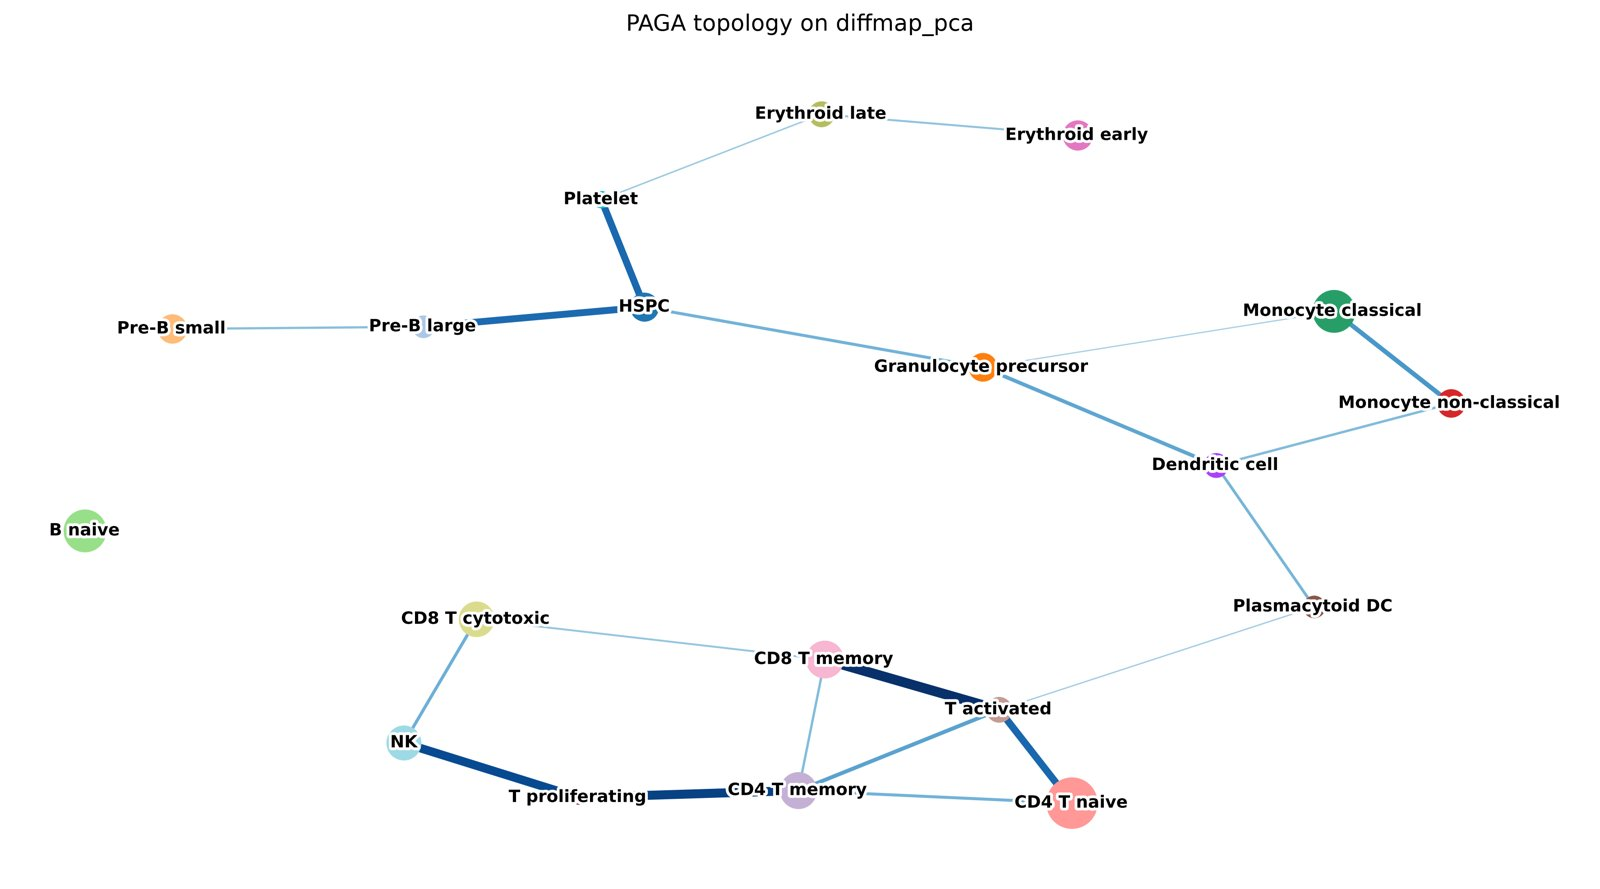

[Full-resolution figure](../figures/trajectory/paga_topology/paga_topology_diffmap_pca.png)

In [4]:
show("trajectory/paga_topology/paga_topology_diffmap_pca.png")

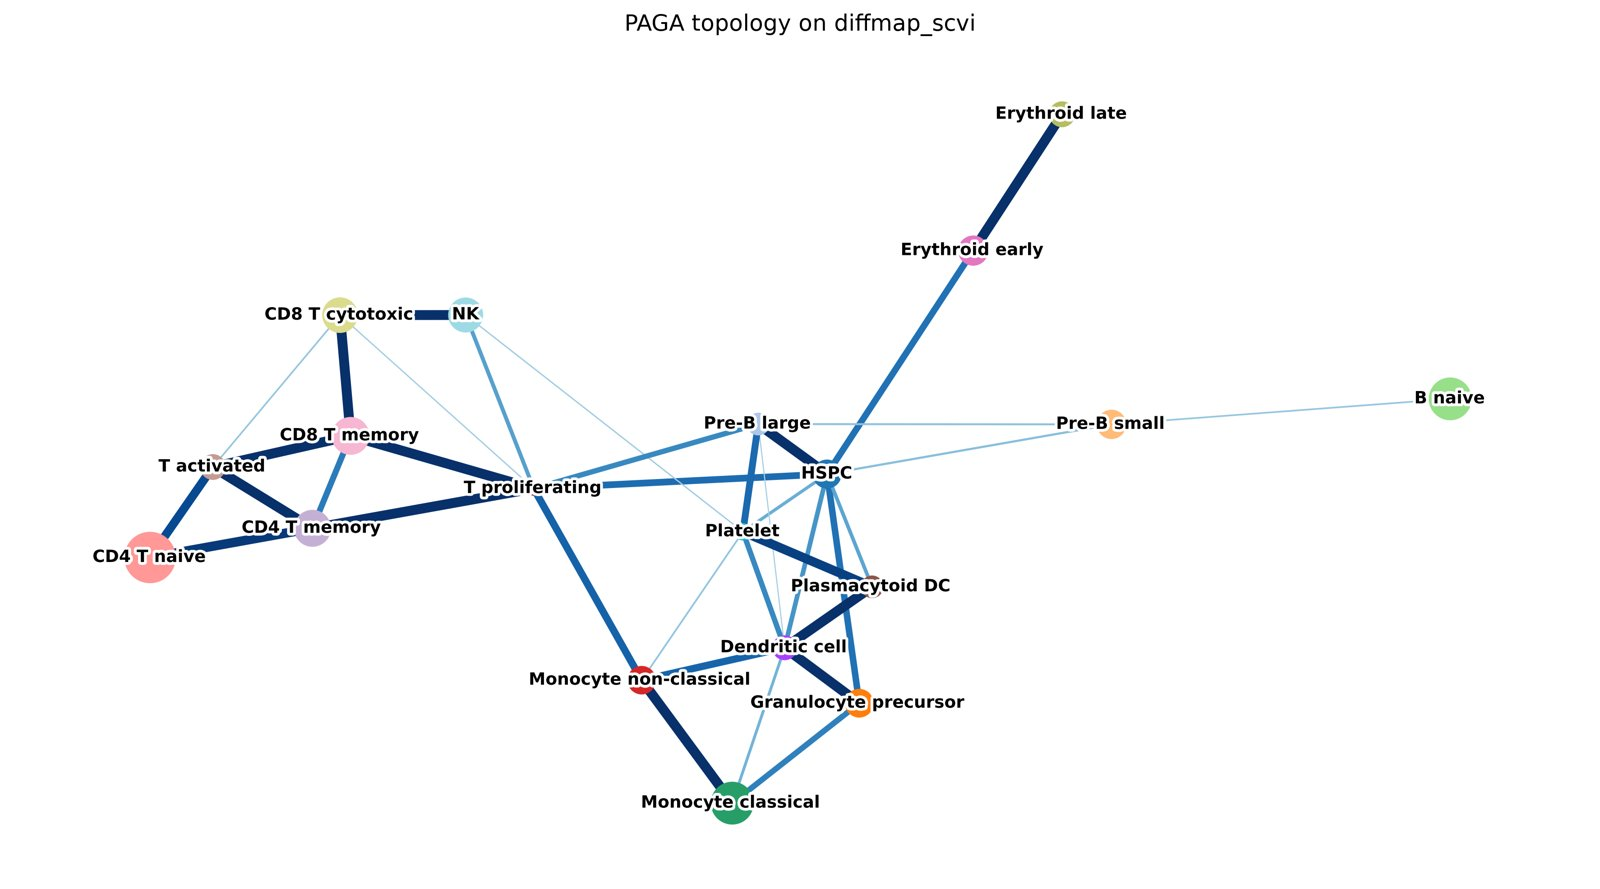

[Full-resolution figure](../figures/trajectory/paga_topology/paga_topology_diffmap_scvi.png)

In [5]:
show("trajectory/paga_topology/paga_topology_diffmap_scvi.png")

- **Edges below 0.1 are not drawn** (display only; all edges are in the
  tables). Width and colour follow connectivity.
- **`diffmap_pca`:** a sparse tree - myeloid arm to the right, B arm to the
  left, erythroid pair at the top hanging off Platelet, the T and NK block at
  the bottom joined to the rest by one weak edge (T activated-Plasmacytoid DC,
  0.137), and B naive alone.
- **`diffmap_scvi`:** a dense hub around HSPC, Platelet, Dendritic cell and
  Plasmacytoid DC, where nearly every node touches every other. The real
  backbone cannot be told apart from the false links here.

## 2. Palantir pseudotime

In [6]:
display(table("trajectory/pt_palantir/pt_palantir_roots.csv"))
display(table("trajectory/pt_palantir/pt_palantir_run_correlation.csv", index_col=0).round(3))
table("trajectory/pt_palantir/pt_palantir_terminal_states.csv")

,run,root,cell_type
0,diffmap_pca_marker,TTGCCGTAGCTACCTA-1-MantonBM6,HSPC
1,diffmap_pca_diffusion,CAGAATCGTACATCCA-1-MantonBM5,HSPC
2,diffmap_scvi_marker,TTGCCGTAGCTACCTA-1-MantonBM6,HSPC
3,diffmap_scvi_diffusion,GACTGCGGTGAAAGAG-1-MantonBM8,HSPC


,diffmap_pca_marker,diffmap_pca_diffusion,diffmap_scvi_marker,diffmap_scvi_diffusion
diffmap_pca_marker,1.000,1.000,0.802,0.241
diffmap_pca_diffusion,1.000,1.000,0.802,0.241
diffmap_scvi_marker,0.802,0.802,1.000,0.517
diffmap_scvi_diffusion,0.241,0.241,0.517,1.000


,run,terminal,cell_type
0,diffmap_pca_marker,CACCTTGGTTGCGTTA-1-MantonBM6,Monocyte classical
1,diffmap_pca_marker,GTACTTTTCTTGTATC-1-MantonBM2,NK
2,diffmap_pca_marker,GTTTCTACAATAACGA-1-MantonBM2,Platelet
3,diffmap_pca_marker,TAGCCGGAGGTCGGAT-1-MantonBM2,B naive
4,diffmap_pca_diffusion,CACCTTGGTTGCGTTA-1-MantonBM6,Monocyte classical
5,diffmap_pca_diffusion,GTACTTTTCTTGTATC-1-MantonBM2,NK
6,diffmap_pca_diffusion,GTTTCTACAATAACGA-1-MantonBM2,Platelet
7,diffmap_pca_diffusion,TAGCCGGAGGTCGGAT-1-MantonBM2,B naive
8,diffmap_scvi_marker,AGCGTATAGTGTGGCA-1-MantonBM5,HSPC
9,diffmap_scvi_marker,ACGATACGTCGGCACT-1-MantonBM6,Erythroid early


- **Four runs: 2 spaces × 2 root rules.** All four roots are HSPC cells. The
  stem-marker root is the same cell in both spaces; the "extreme of the first
  diffusion component" root differs.
- **In `diffmap_pca` the root rule does not matter**: two different HSPC cells
  from two donors give the identical ordering (Spearman 1.000).
- **The space does matter**: same marker root, `diffmap_pca` against
  `diffmap_scvi` - 0.802.
- **`diffmap_scvi_diffusion` is a failed run**, 0.241 against `diffmap_pca` and
  0.517 against its own space's other run (see the table below).
- **Terminal states found by Palantir in `diffmap_pca`: Monocyte classical, NK,
  Platelet, B naive.** Three are real end points of marrow development; NK is
  the mature-cell negative again. No erythroid and no plasmacytoid DC terminal.
  *Corrected 15 Oct 2026: earlier write-ups listed Erythroid late instead of
  Monocyte classical; the saved table is used here.*
- **Both scVI runs return HSPC itself as a terminal state** - a sign that their
  orderings are distorted.
- **Start cell and zero differ slightly**: the marker root sits at 0.143 in the
  stored `diffmap_pca` column; the cell at 0 is another HSPC cell
  (`AAAGCAAGTATTACCG-1-MantonBM7`). Both are HSPC, and the root choice does not
  change the ordering.

In [7]:
table("trajectory/pt_palantir/pt_palantir_pseudotime_by_celltype.csv", index_col="cell_type").round(3)

,diffmap_pca_marker,diffmap_pca_diffusion,diffmap_scvi_marker,diffmap_scvi_diffusion
cell_type,,,,
HSPC,0.155,0.155,0.172,0.498
Granulocyte precursor,0.494,0.494,0.384,0.203
Monocyte classical,0.729,0.729,0.527,0.083
Monocyte non-classical,0.740,0.740,0.567,0.059
Dendritic cell,0.547,0.547,0.451,0.164
Plasmacytoid DC,0.822,0.822,0.597,0.524
Erythroid early,0.576,0.576,0.633,0.877
Erythroid late,0.661,0.661,0.608,0.809
Platelet,0.676,0.676,0.719,0.765


- **Mean pseudotime per cell type**, 0 = earliest.
- **`diffmap_pca` (both roots identical): HSPC first (0.155), and three
  maturation series come out in the right order without being told:**
  - Erythroid early 0.576 -> Erythroid late 0.661
  - Pre-B large 0.714 -> Pre-B small 0.800 -> B naive 0.844
  - Granulocyte precursor 0.494 -> Monocyte classical 0.729 -> non-classical 0.740
- **T proliferating is second earliest (0.415)**: dividing cells look like
  dividing progenitors, so they are pulled toward the root. Not early cells.
- **The mature T block is a flat plateau**: CD8 T memory 0.584, CD4 T naive
  0.588, CD4 T memory 0.595, T activated 0.600 - four labels in a 0.015 band.
  A real trajectory spreads out; a plateau is the negative result in numbers.
- **`diffmap_scvi_diffusion` puts both monocyte types first** (0.083, 0.059)
  and HSPC mid-axis (0.498): its root, the extreme HSPC cell on the first
  diffusion component, lies in the monocyte region of that space.
- **Both scVI runs invert the erythroid order** (early 0.633 / 0.877, late
  0.608 / 0.809). Only `diffmap_pca` orders this known series correctly -
  the strongest single reason to keep it as the main space.

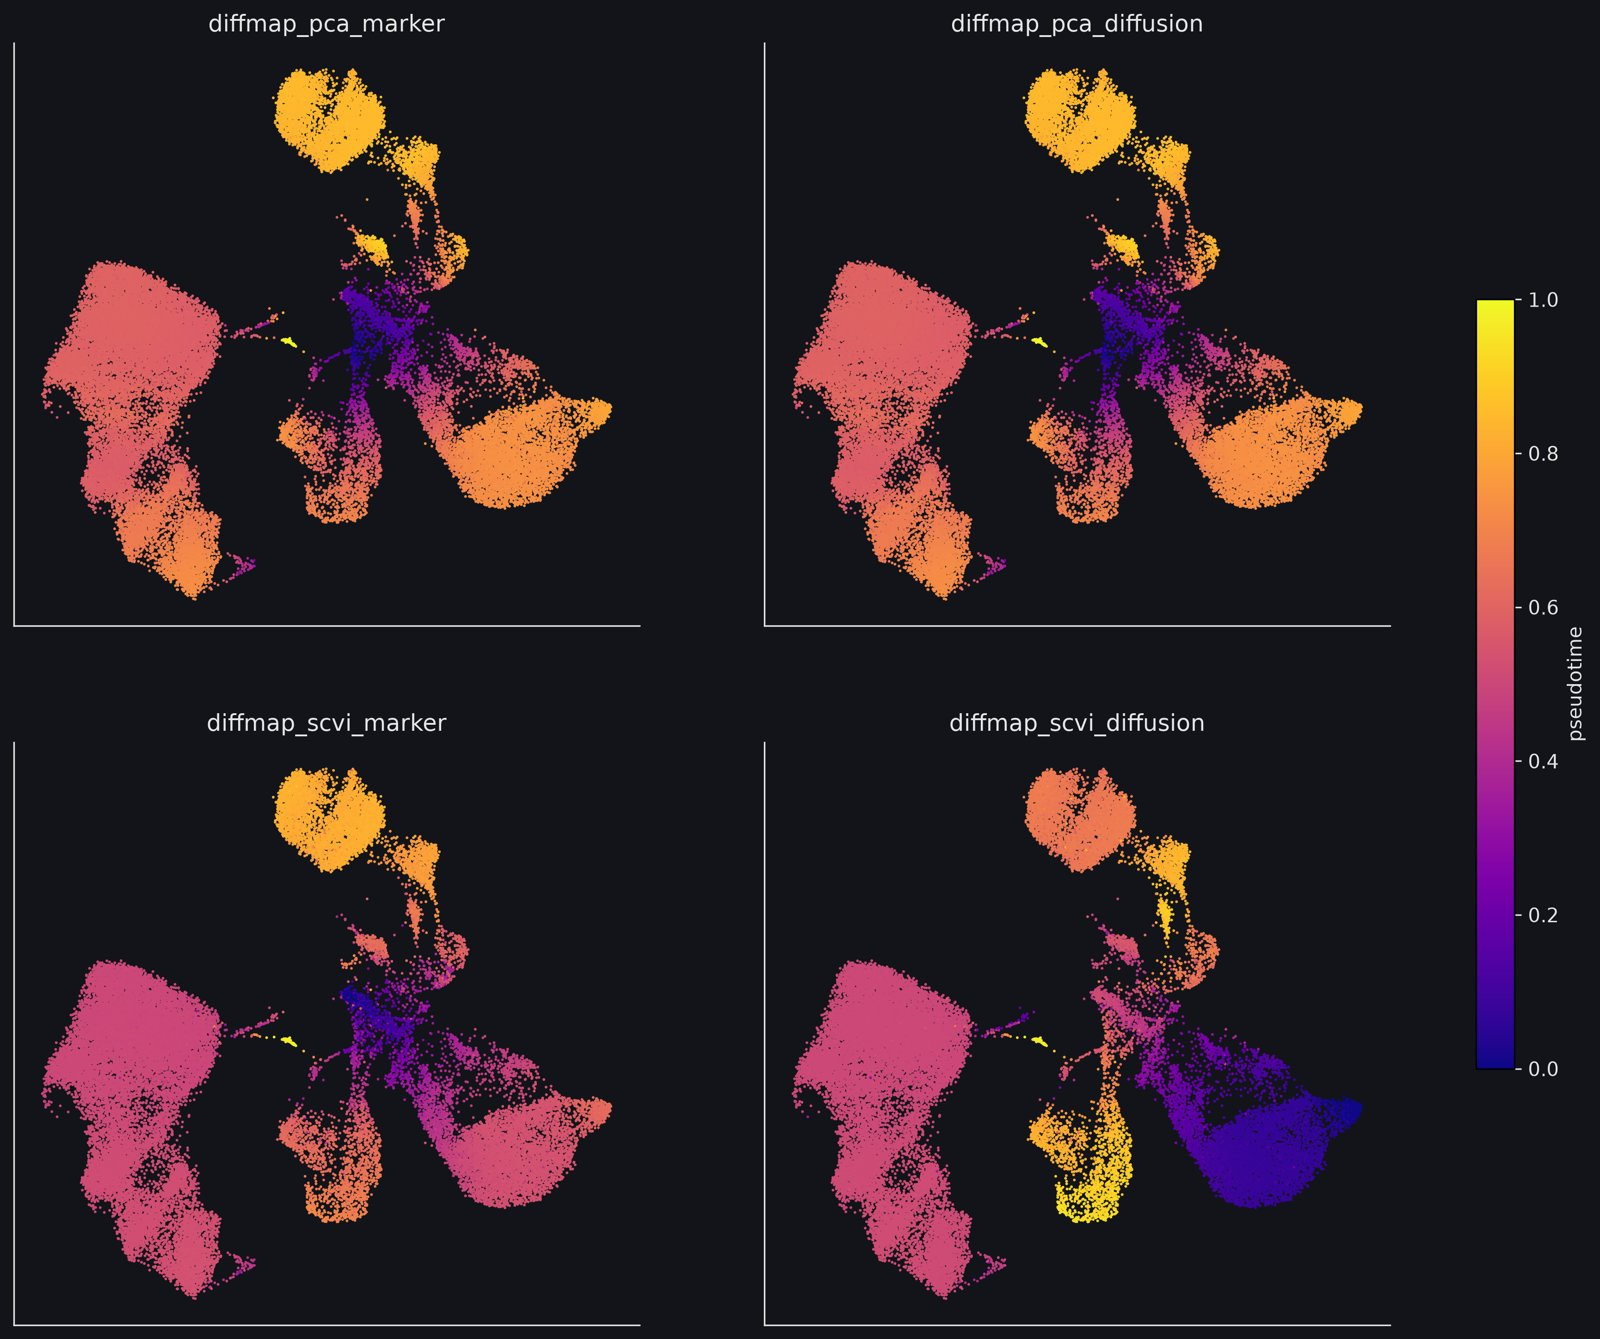

[Full-resolution figure](../figures/trajectory/pt_palantir/pt_palantir_umap_grid.png)

In [8]:
show("trajectory/pt_palantir/pt_palantir_umap_grid.png")

- **The two `diffmap_pca` panels are identical** - the 1.000 correlation
  drawn.
- **Pseudotime fans out from the dark HSPC hub in the middle** into every
  island; the large T region (left) is a uniform salmon colour with no
  internal gradient - the plateau.
- **`diffmap_scvi_diffusion` (bottom right) is inverted**: the monocyte region
  is the darkest (earliest) part of the map and the erythroid island the
  brightest.
- **A small speck left of centre is bright yellow (latest) in all four
  panels.** It is a group of platelets - see section 13.

## 3. CellRank fate probabilities

In [9]:
fates = {
    states: table(f"trajectory/pt_cellrank/pt_cellrank_fate_by_celltype_k{states}.csv",
                  index_col="cell_type")
    for states in (8, 5, 4)
}
display(pd.Series({states: ", ".join(frame.columns) for states, frame in fates.items()},
                  name="terminal states").rename_axis("states requested").to_frame())
fates[8].round(2)

,terminal states
states requested,
8,"Platelet, Plasmacytoid DC, Pre-B large, Erythroid late, Erythroid early, B n..."
5,"Pre-B large, Erythroid early, B naive, Monocyte non-classical, NK"
4,"Erythroid early, B naive, Monocyte non-classical, NK"


,Platelet,Plasmacytoid DC,Pre-B large,Erythroid late,Erythroid early,B naive,Monocyte classical,NK
cell_type,,,,,,,,
HSPC,0.01,0.09,0.18,0.05,0.06,0.19,0.19,0.23
Granulocyte precursor,0.00,0.04,0.01,0.02,0.00,0.08,0.75,0.10
Monocyte classical,0.00,0.03,0.00,0.01,0.00,0.08,0.83,0.06
Monocyte non-classical,0.00,0.04,0.00,0.01,0.00,0.10,0.76,0.09
Dendritic cell,0.00,0.07,0.01,0.01,0.01,0.09,0.74,0.07
Plasmacytoid DC,0.00,0.85,0.00,0.00,0.00,0.09,0.02,0.03
Erythroid early,0.00,0.00,0.00,0.11,0.87,0.00,0.01,0.01
Erythroid late,0.00,0.00,0.00,0.83,0.13,0.00,0.01,0.03
Platelet,0.54,0.02,0.02,0.08,0.01,0.04,0.03,0.27


- **CellRank** builds a Markov chain from the Palantir pseudotime (0.8) and the
  neighbour graph (0.2), finds stable groups of cells (macrostates), and gives
  every cell a probability of ending in each one. Each macrostate holds 30
  cells of a single label; all are treated as terminal.
- **At 8 states all four Palantir end points come back** (Monocyte classical,
  NK, Platelet, B naive), and Plasmacytoid DC, both erythroid stages and
  Pre-B large are added.
- **HSPC is the only cell type with spread fate**: NK 0.233, Monocyte 0.195,
  B naive 0.188, Pre-B large 0.182, Plasmacytoid DC 0.093, Erythroid early
  0.055, late 0.046, Platelet 0.008. No fate above a quarter - multipotency,
  found without being told which cells are progenitors.
- **The myeloid arm funnels into one end point**: Granulocyte precursor 0.752,
  Monocyte classical 0.830, Monocyte non-classical 0.762, Dendritic cell 0.744.
- **Plasmacytoid DC is its own branch** (0.848), with 0.089 to B naive.
- **Two terminals are intermediates, not ends**: Pre-B large keeps 0.892 of its
  own cells instead of flowing to B naive, and the two erythroid stages split
  into competing ends (early 0.869 own / 0.107 late; late 0.825 own / 0.131
  early). Forcing 8 states makes dense, well-separated islands absorbing.
- **Platelet is fragile**: only 0.538 to its own end point and 0.270 to NK;
  103 cells cannot hold a basin next to a 21,000-cell neighbour.
- **All seven mature lymphoid labels (21,545 cells, 56%) go 0.859-0.986 to the
  one NK end point** - one basin with no internal structure.

In [10]:
rows = ["HSPC", "Granulocyte precursor", "Monocyte classical", "Plasmacytoid DC",
        "Platelet", "Pre-B large", "Erythroid late"]
pd.concat({states: frame.loc[rows] for states, frame in fates.items()}, axis=1).round(2)

8                                             \
                      Platelet Plasmacytoid DC Pre-B large Erythroid late   
cell_type                                                                   
HSPC                      0.01            0.09        0.18           0.05   
Granulocyte precursor     0.00            0.04        0.01           0.02   
Monocyte classical        0.00            0.03        0.00           0.01   
Plasmacytoid DC           0.00            0.85        0.00           0.00   
Platelet                  0.54            0.02        0.02           0.08   
Pre-B large               0.00            0.01        0.89           0.00   
Erythroid late            0.00            0.00        0.00           0.83   

                                                                        \
                      Erythroid early B naive Monocyte classical    NK   
cell_type                                                                
HSPC                             0.06    0.19               0.19  0.23   
Granulocyte precursor            0.00    0.08               0.75  0.10   
Monocyte classical               0.00    0.08               0.83  0.06   
Plasmacytoid DC                  0.00    0.09               0.02  0.03   
Platelet                         0.01    0.04               0.03  0.27   
Pre-B large                      0.00    0.07               0.01  0.01   
Erythroid late                   0.13    0.00               0.01  0.03   

                                5                          \
                      Pre-B large Erythroid early B naive   
cell_type                                                   
HSPC                         0.19            0.08    0.23   
Granulocyte precursor        0.01            0.01    0.05   
Monocyte classical           0.00            0.00    0.04   
Plasmacytoid DC              0.04            0.01    0.51   
Platelet                     0.03            0.07    0.16   
Pre-B large                  0.89            0.00    0.08   
Erythroid late               0.01            0.53    0.04   

                                                                 4          \
                      Monocyte non-classical    NK Erythroid early B naive   
cell_type                                                                    
HSPC                                    0.25  0.26            0.08    0.37   
Granulocyte precursor                   0.84  0.09            0.01    0.06   
Monocyte classical                      0.93  0.03            0.00    0.04   
Plasmacytoid DC                         0.26  0.18            0.01    0.54   
Platelet                                0.09  0.66            0.07    0.18   
Pre-B large                             0.01  0.02            0.01    0.78   
Erythroid late                          0.09  0.33            0.53    0.05   

                                                    
                      Monocyte non-classical    NK  
cell_type                                           
HSPC                                    0.26  0.28  
Granulocyte precursor                   0.84  0.09  
Monocyte classical                      0.93  0.03  
Plasmacytoid DC                         0.26  0.19  
Platelet                                0.09  0.66  
Pre-B large                             0.09  0.11  
Erythroid late                          0.09  0.33

- **The resolution check: fewer end points do not remove the two
  intermediates first.** Going from 8 to 5 states removes Platelet,
  Plasmacytoid DC and Erythroid late (and the monocyte end point is now named
  after a non-classical cell); Pre-B large and Erythroid early survive. Only at
  4 states does Pre-B large go.
- **Four end points survive at every level**: Erythroid early, B naive, a
  monocyte end point, NK.
- **What improves at 4**: Pre-B large now goes 0.782 to B naive, so the B
  series reads correctly.
- **What gets worse**: Platelet is absorbed by NK (0.655 at 5, 0.659 at 4);
  Plasmacytoid DC goes 0.508 / 0.540 to B naive; Erythroid late sends 0.533 to
  the early end point and 0.33 to NK.
- **Stable at every level**: the myeloid funnel (0.74-0.93), the lymphoid
  collapse into NK (0.86-0.99) and HSPC as the least committed row (highest
  fate 0.233, 0.263, 0.372).
- **Decision: 8 states is the main result, 4 the check**; conclusions rest on
  what holds in both.
- *Corrected 15 Oct 2026: earlier write-ups named the 5- and 4-state monocyte
  end point "Monocyte classical" and gave smaller myeloid values; the saved
  tables are used here.*

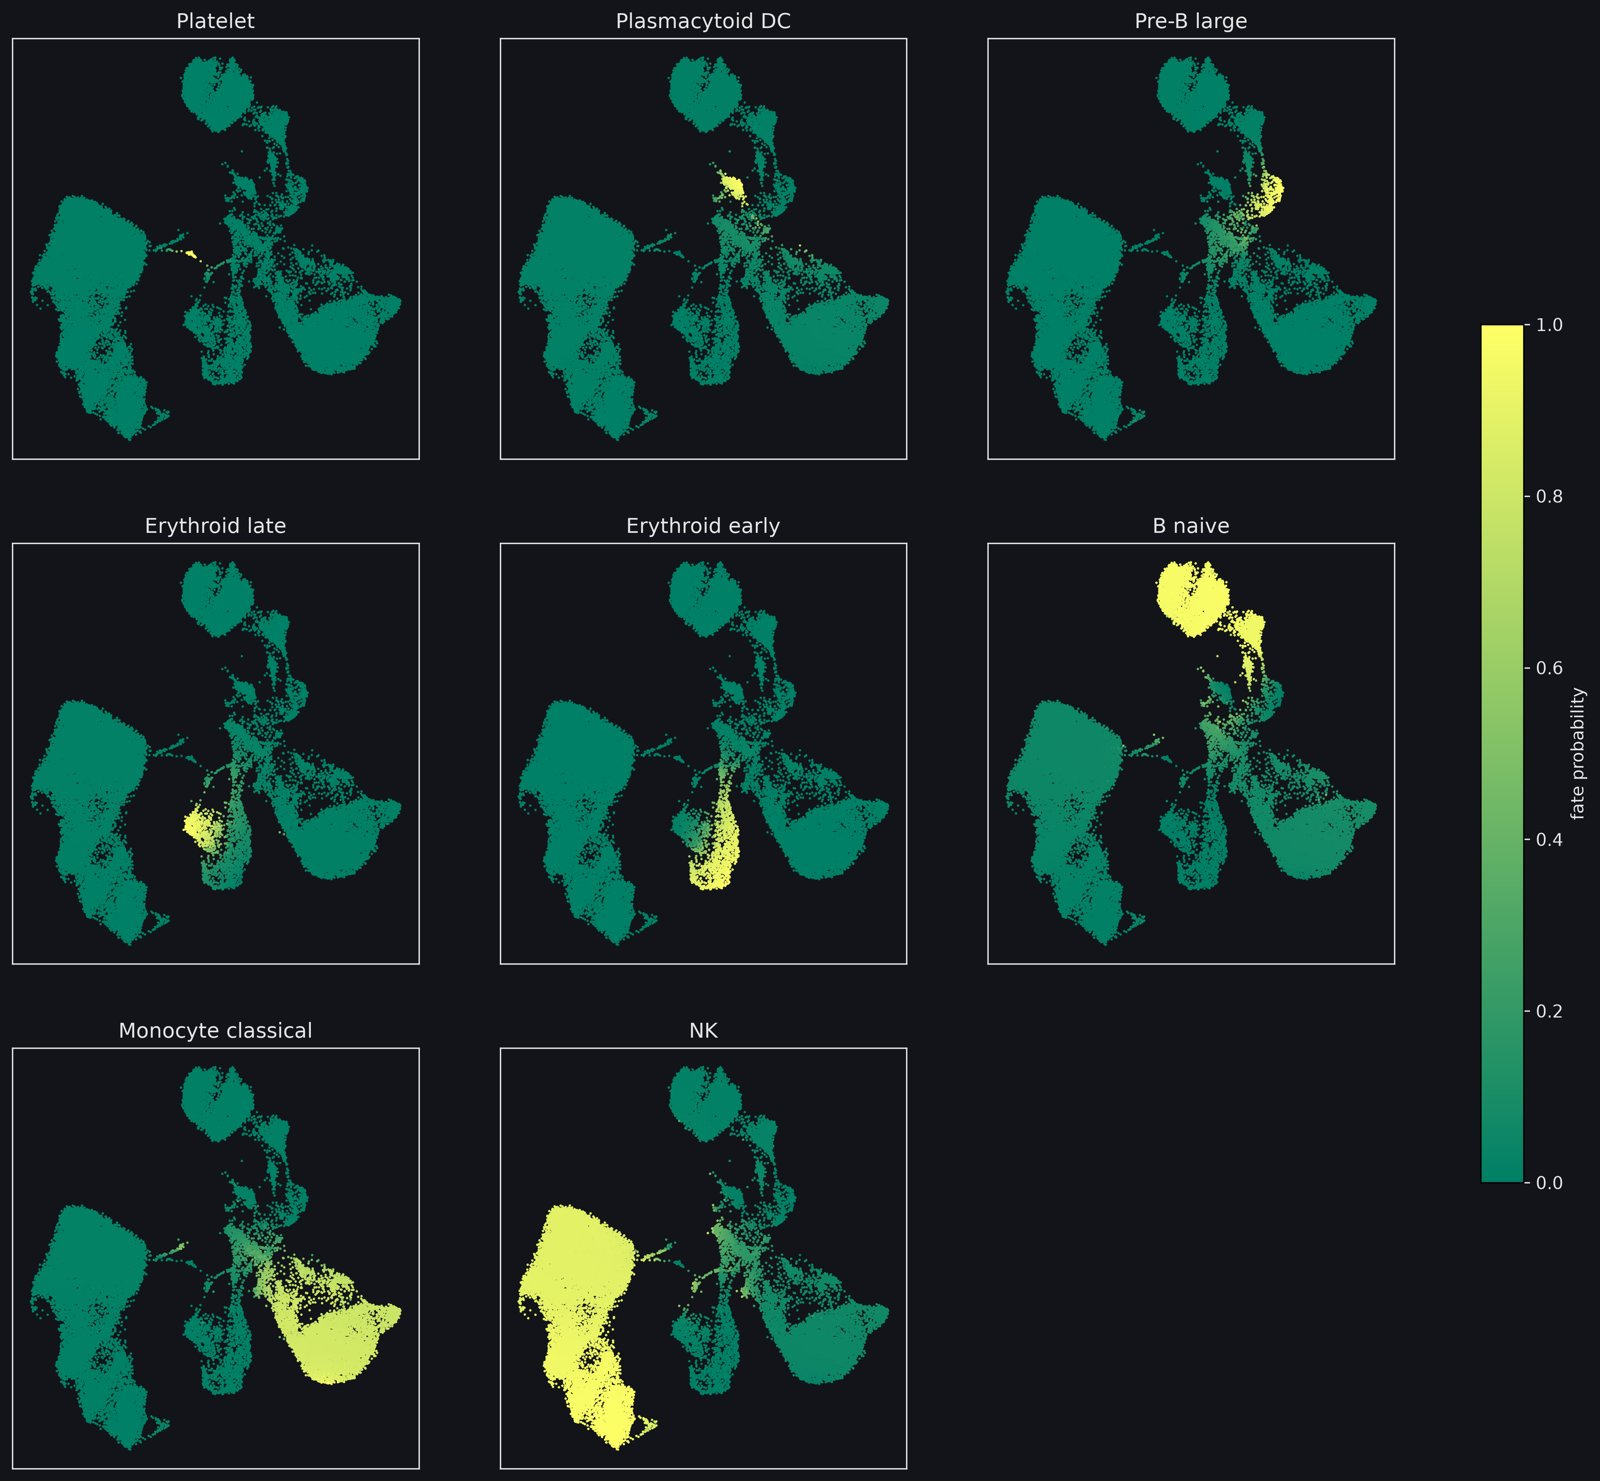

[Full-resolution figure](../figures/trajectory/pt_cellrank/pt_cellrank_fate_umap_k8.png)

In [11]:
show("trajectory/pt_cellrank/pt_cellrank_fate_umap_k8.png")

- **The panels are close to on/off**: bright where a lineage owns the cells,
  dark elsewhere - fates barely overlap.
- **The NK panel lights the whole T region at once**, with no gradient across
  it.
- **The erythroid island is split between two panels** (late in the upper
  part, early in the lower part): one series, two competing end points.
- **Monocyte classical shows the only broad gradient**, from the HSPC hub
  through the bridge into the monocyte region - what a lineage with a real
  intermediate looks like here.
- **Platelet and Plasmacytoid DC are small specks**: a terminal state says
  nothing about how many cells reach it.

## 4. Driver genes of each fate

In [12]:
drivers = table("trajectory/fate_drivers/fate_drivers_top.csv")
leading = drivers.groupby("lineage").head(10)
summary = pd.DataFrame({
    "top 10 genes (correlation)": {
        lineage: ", ".join(f"{gene} {value:.2f}" for gene, value in zip(rows["gene"], rows["correlation"]))
        for lineage, rows in leading.groupby("lineage")
    },
})
summary.join(drivers.groupby("lineage")["pct_cells"].agg(["min", "max"]).mul(100).round(1)
             .add_prefix("% cells expressing, "))

,top 10 genes (correlation),"% cells expressing, min","% cells expressing, max"
B naive,"IGHM 0.86, CD79A 0.85, MS4A1 0.71, IGHD 0.69, CD74 0.69, HLA-DRA 0.69, CD79B...",2.2,67.0
Erythroid early,"FAM178B 0.79, KCNH2 0.79, KLF1 0.79, AHSP 0.78, RHAG 0.77, EPCAM 0.76, CA2 0...",1.9,29.0
Erythroid late,"AHSP 0.62, CA1 0.57, HBB 0.56, HBA1 0.54, HBD 0.51, FAM178B 0.47, HBA2 0.47,...",2.2,37.4
Monocyte classical,"LYZ 0.96, S100A9 0.91, S100A8 0.89, CST3 0.88, CSTA 0.86, FCN1 0.85, LST1 0....",6.7,95.3
NK,"IL32 0.68, CD3D 0.62, CD3E 0.60, TRAC 0.57, CD7 0.53, B2M 0.49, MALAT1 0.47,...",9.9,99.8
Plasmacytoid DC,"LILRA4 0.80, SCT 0.68, SERPINF1 0.64, TPM2 0.58, SMPD3 0.57, CLEC4C 0.53, PL...",0.1,10.9
Platelet,"TUBB1 0.84, TMEM40 0.84, GP9 0.81, ACRBP 0.78, CAVIN2 0.74, TREML1 0.73, PF4...",0.2,6.1
Pre-B large,"IGLL1 0.67, VPREB1 0.54, UHRF1 0.53, STMN1 0.47, TYMS 0.46, NUSAP1 0.44, MKI...",0.4,32.5


- **Pearson correlation of every gene with every fate probability** (8 fates,
  14,087 genes detected in at least 50 cells), top 50 per fate saved. Nothing
  is removed for what it is - the haemoglobin genes *are* the erythroid
  drivers. P-values are 0 throughout at this cell count and are not used.
- **Textbook drivers, from a correlation alone:**
  - Monocyte classical: LYZ 0.96 (the strongest value in the table), S100A9,
    S100A8, CST3, with the factors SPI1 0.60, KLF4 0.54, CEBPD 0.52
    (MAFB 0.51, just outside the top 50).
  - Erythroid early: FAM178B, KCNH2, KLF1, AHSP 0.78-0.79, GATA1 0.72 - the two
    master factors plus heme enzymes, membrane proteins and globins.
  - Plasmacytoid DC: LILRA4 0.80, SCT, SERPINF1, CLEC4C, PLD4, IL3RA.
  - B naive: IGHM 0.86, CD79A 0.85, MS4A1, IGHD.
  - Platelet: TUBB1 0.84, TMEM40, GP9, ACRBP, PF4, PPBP.
- **Pre-B large is a cell-cycle fate**: after IGLL1 0.67 and VPREB1 0.54 come
  UHRF1, STMN1, TYMS, NUSAP1, MKI67, PCLAF, AURKB. Its end point is a dividing
  state, not a developmental end.
- **The NK fate is led by T-cell genes** (IL32 0.68, CD3D 0.62, CD3E, TRAC);
  NK genes rank lower (NKG7 0.43, GZMA 0.40). It is a *mature lymphoid*
  basin named after whichever cell sat at its centre.
- **Housekeeping genes enter the NK list**: B2M 0.49 and MALAT1 0.47 (in 99%
  of cells) and 10 ribosomal proteins at 0.32-0.44 (in 98-100% of cells). A
  gene in nearly every cell is not a driver; this is why `pct_cells` is kept.
- **Plasmacytoid DC carries a plasma-cell secretory module**: JCHAIN 0.44,
  ITM2C 0.44, DERL3 0.45, MZB1 0.31 - the reason it leans toward B naive at 4
  states.
- **Correlation strength and cell numbers are independent**: the platelet
  drivers are among the strongest yet are expressed in 0.2-6.1% of cells.

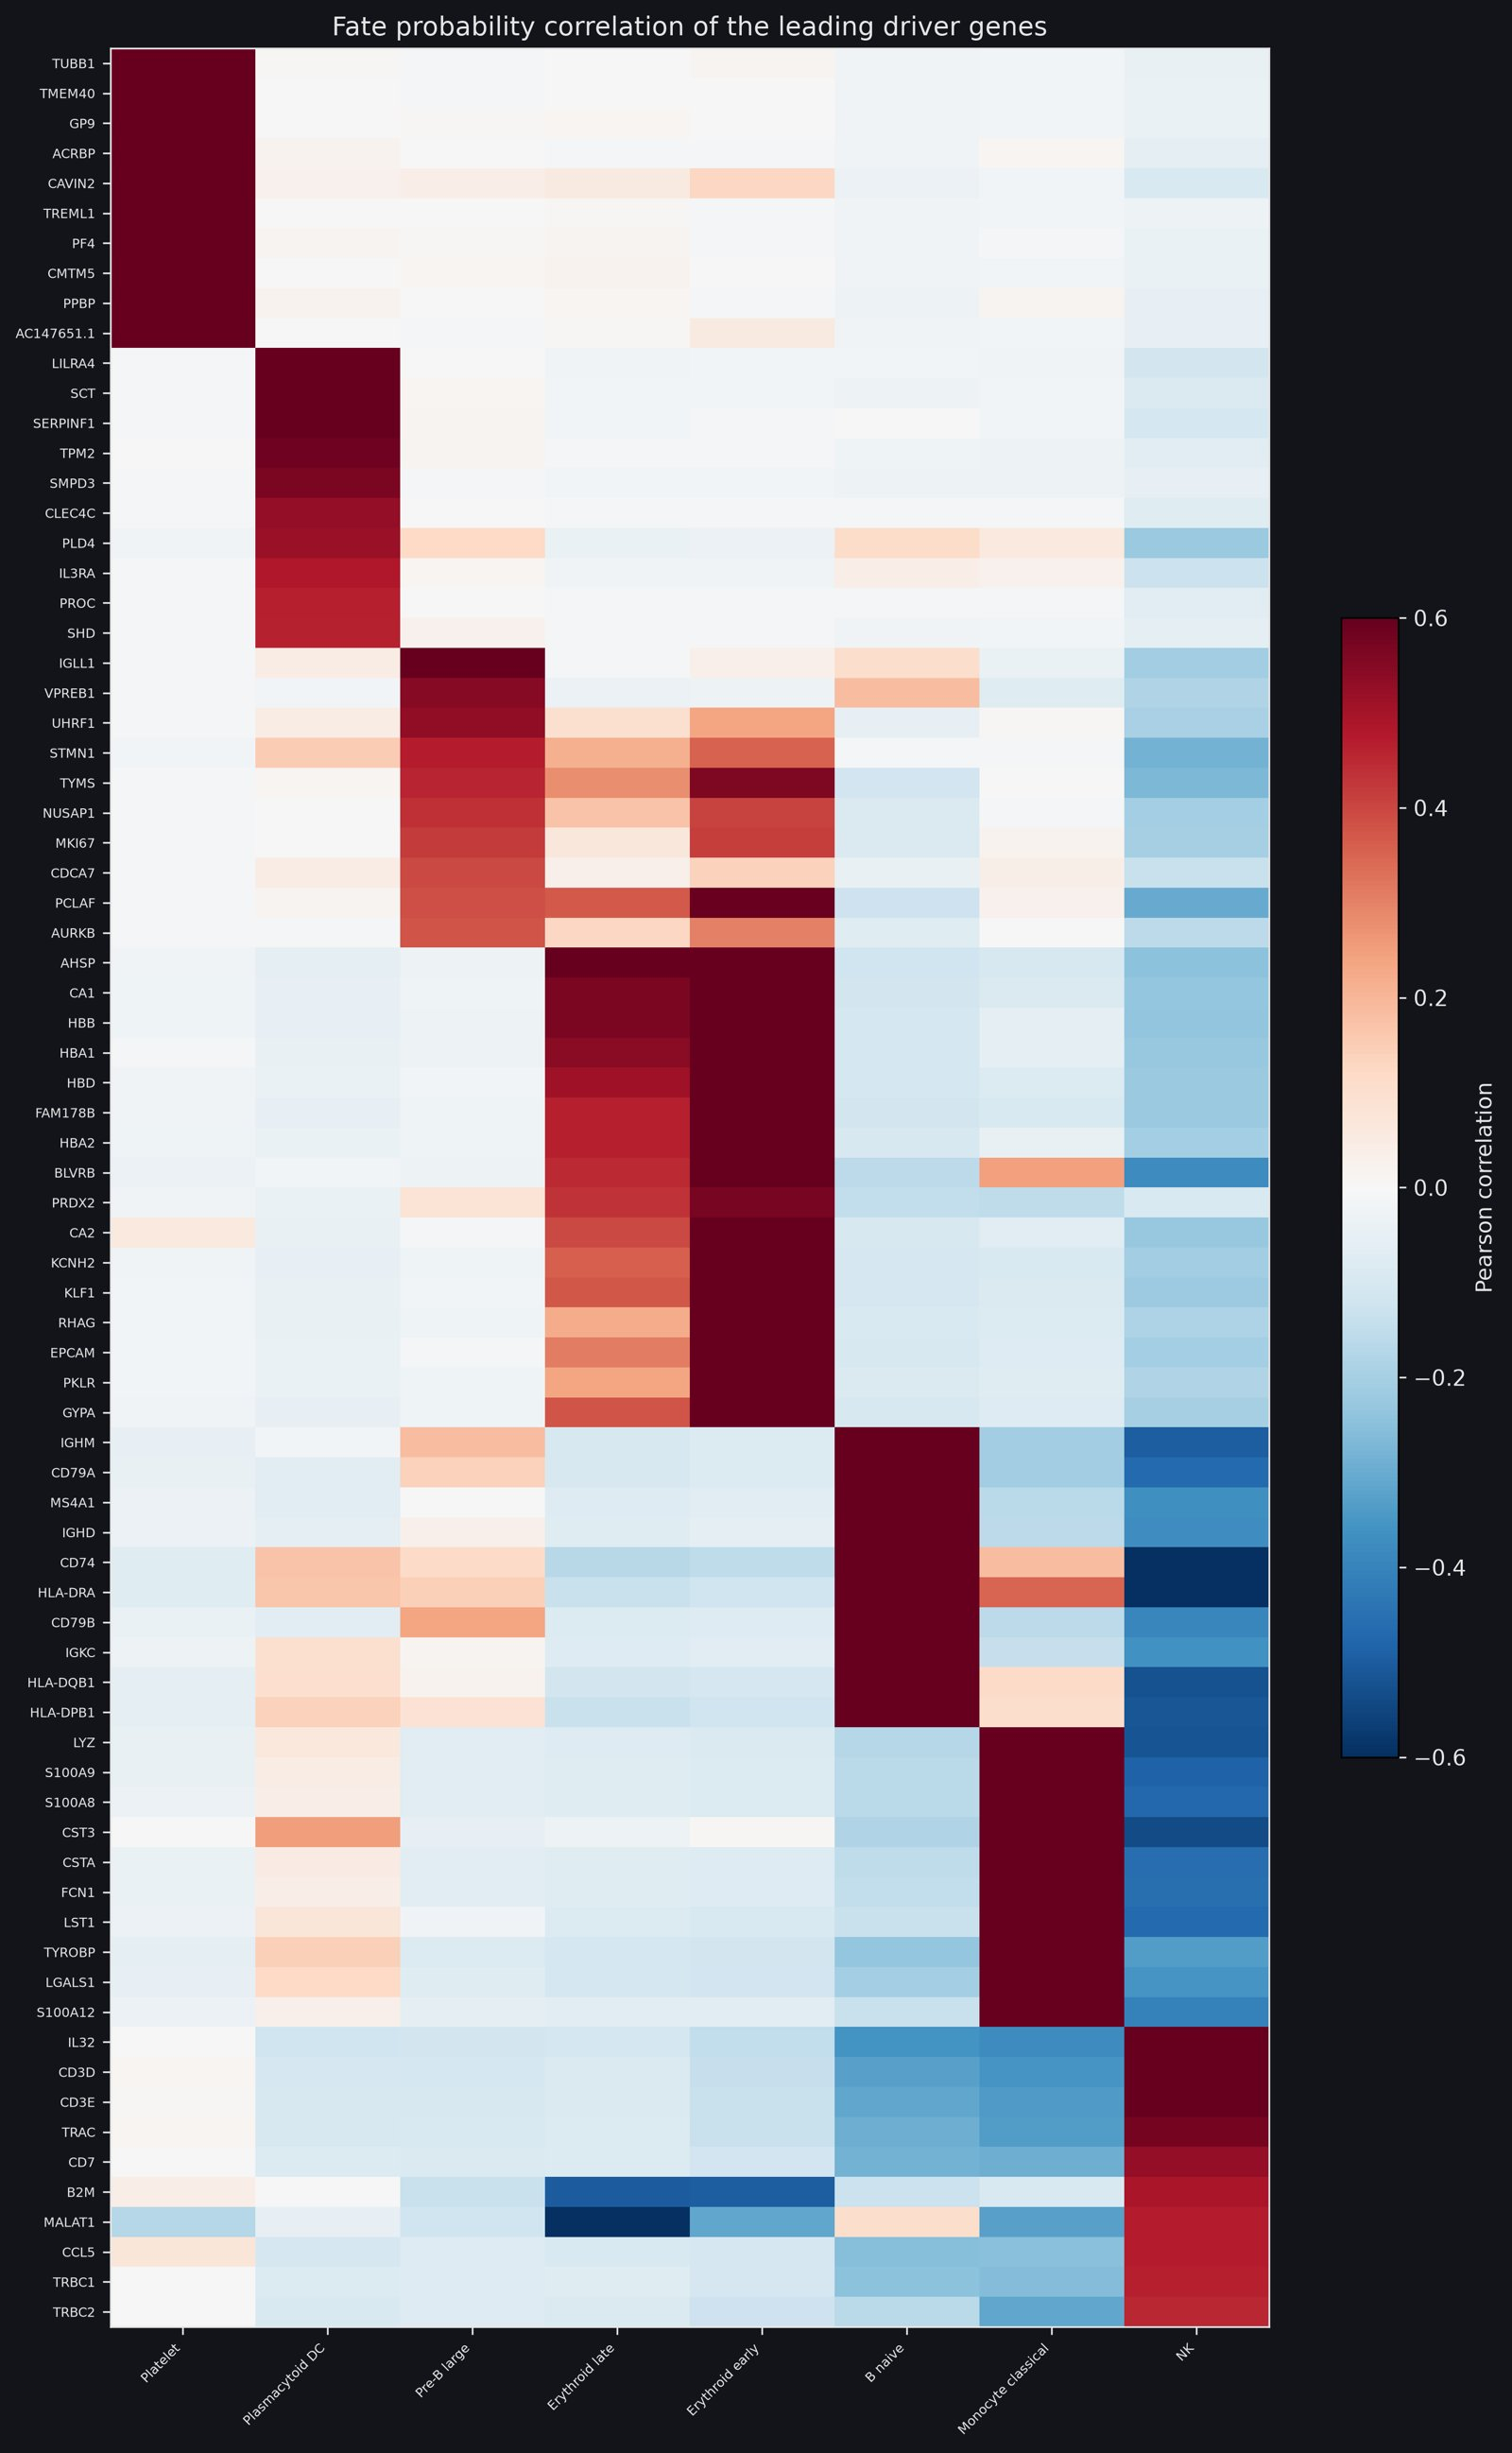

[Full-resolution figure](../figures/trajectory/fate_drivers/fate_drivers_heatmap.png)

In [13]:
show("trajectory/fate_drivers/fate_drivers_heatmap.png", width=650)

- **Top 10 drivers per fate, colour clipped at ±0.6** (so all strong values
  look equally dark). Block-diagonal: each fate owns its genes.
- **The two erythroid columns share one gene block**, the early column darker:
  the split end point again.
- **Cell-cycle genes are warm in both Pre-B large and Erythroid early**
  (TYMS, PCLAF, STMN1): division is shared, so it cannot separate lineages.
- **The NK column is deep blue across the B and monocyte blocks**: with 56% of
  cells in that basin, anything specific to another lineage is anticorrelated
  by construction.
- **MALAT1 and B2M are strongly negative in the erythroid columns**: maturing
  red cells lose their nucleus, and MALAT1 is a nucleus-retained RNA.

## 5. Gene trends along pseudotime

In [14]:
composition = table("trajectory/gene_trends/gene_trends_composition.csv")
dominant = (composition.sort_values("fraction", ascending=False)
            .drop_duplicates(["lineage", "bin"]).sort_values(["lineage", "bin"]))
dominant["run"] = (dominant["cell_type"] != dominant.groupby("lineage")["cell_type"].shift()).cumsum()
dominant.groupby(["lineage", "run"]).agg(
    label=("cell_type", "first"), first_bin=("bin", "min"), last_bin=("bin", "max"),
    lowest_share=("fraction", "min"), highest_share=("fraction", "max"),
).droplevel("run").round(2)

,label,first_bin,last_bin,lowest_share,highest_share
lineage,,,,,
B naive,Pre-B small,0,3,0.54,0.99
B naive,B naive,4,38,0.66,0.99
B naive,Pre-B small,39,39,0.79,0.79
Erythroid early,Erythroid early,0,39,0.93,1.00
Erythroid late,Erythroid late,0,39,1.00,1.00
Monocyte classical,Granulocyte precursor,0,0,0.74,0.74
Monocyte classical,Dendritic cell,1,1,0.54,0.54
Monocyte classical,Granulocyte precursor,2,6,0.51,0.77
Monocyte classical,Monocyte classical,7,36,0.66,0.99


- **Method:** cells committed to a fate (probability ≥ 0.60) are cut into 40
  bins of equal cell count along Palantir pseudotime; each gene is scaled
  across its own bins. Seven lineages qualified; Platelet was skipped (fewer
  than 200 committed cells).
- **The table is the test the methods can fail**: which label dominates each
  run of bins. The labels were never given to Palantir or CellRank.
- **Monocyte - correct end to end**: Granulocyte precursor and Dendritic cell
  in bins 0-6, Monocyte classical from bin 7, Monocyte non-classical in bins
  37-39 (100% in 38-39).
- **Pre-B large - HSPC in bins 0-1, then Pre-B large**; the rest of the axis
  orders cells inside one label.
- **B naive - correct with a bad tail**: Pre-B small leads bins 0-3, the
  handover runs to bin 7 (0.90 B naive), but bin 39 goes back to 0.79 Pre-B
  small (section 6).
- **Erythroid early, Erythroid late and Plasmacytoid DC are single-label
  axes** (0.88-1.00 one label in every bin): maturation within a label, not
  differentiation from a precursor.
- **NK - a gradient, not development**: CD8 T memory -> CD4 T naive -> CD4 T
  memory -> CD8 T cytotoxic -> NK. A naive CD4 T cell does not become a CD8 or NK
  cell. A trajectory method always returns an order, whether or not a process
  exists.

In [15]:
peaks = table("trajectory/gene_trends/gene_trends_peak_order.csv")
pd.Series({
    lineage: ", ".join(f"{gene} {peak}" for gene, peak in zip(rows["gene"], rows["peak_bin"]))
    for lineage, rows in peaks.groupby("lineage")
}, name="gene and peak bin, earliest first").to_frame()

,"gene and peak bin, earliest first"
B naive,"CD79B 0, VPREB3 0, HLA-DMA 0, IGLC3 18, RALGPS2 23, FCER2 28, MEF2C 28, ADAM..."
Erythroid early,"APOC1 1, CNRIP1 1, TFR2 5, FAM178B 16, PKLR 16, EPCAM 17, HBQ1 21, KCNH2 24,..."
Erythroid late,"PCLAF 2, APOC1 4, SYNGR1 5, EPCAM 6, FECH 7, TUBB 8, HMBS 9, GATA1 11, CA2 1..."
Monocyte classical,"LYZ 3, LGALS1 9, AC020656.1 10, S100A9 16, S100A8 16, CSTA 16, S100A12 18, V..."
NK,"RPS29 5, RPS27 5, RPL31 11, CD3E 17, TRBC2 18, CD3D 21, IL7R 21, SARAF 23, T..."
Plasmacytoid DC,"CCDC50 1, PROC 6, SCN9A 9, UGCG 12, JCHAIN 19, TPM2 23, ASIP 26, AC119428.2 ..."
Pre-B large,"UHRF1 2, CDCA7 5, DNTT 5, PHGDH 12, VPREB1 22, CDCA5 22, ASF1B 31, IGLL1 32,..."


- **Erythroid early - the best order in the stage**: GATA1 peaks at bin 31 and
  KLF1 at 35, before the heme enzymes (HMBS 36, FECH 38, ALAS2 39) and membrane
  genes (SPTA1 37, RHAG 39, EPB42 39). Regulators before targets.
- **Erythroid late - cycling first, globins last**: PCLAF at 2, GATA1 at 11,
  KLF1 at 29, then every globin at bin 39.
- **Monocyte - alarmins before surface markers**: S100A8 / S100A9 at 16, CD14 /
  FCN1 at 30, the non-classical genes (LST1, AIF1, FCER1G) and SPI1 at 39.
- **B naive - receptor genes before surface, surface before immunoglobulin**:
  CD79B / VPREB3 at 0, MS4A1 / BANK1 at 33, IGHD 37, IGHM 38.
- **Pre-B large - the cell cycle in order**: S phase (TYMS, PCNA, RRM2) at 32,
  then G2/M (AURKB 34, STMN1 35), then mitosis (MKI67, TOP2A, UBE2C, CENPF) at
  39.
- **Plasmacytoid DC - secretory genes mid-axis** (JCHAIN 19, DERL3 33, ITM2C
  34), identity factors last (IRF7 36, IRF8 37, TCF4 38).
- **NK - T genes first, cytotoxic genes last**: IL7R 21, TRAC 25, then NKG7,
  GZMA, KLRB1 and CST7 all at 39 - the gradient from the table above, in genes.

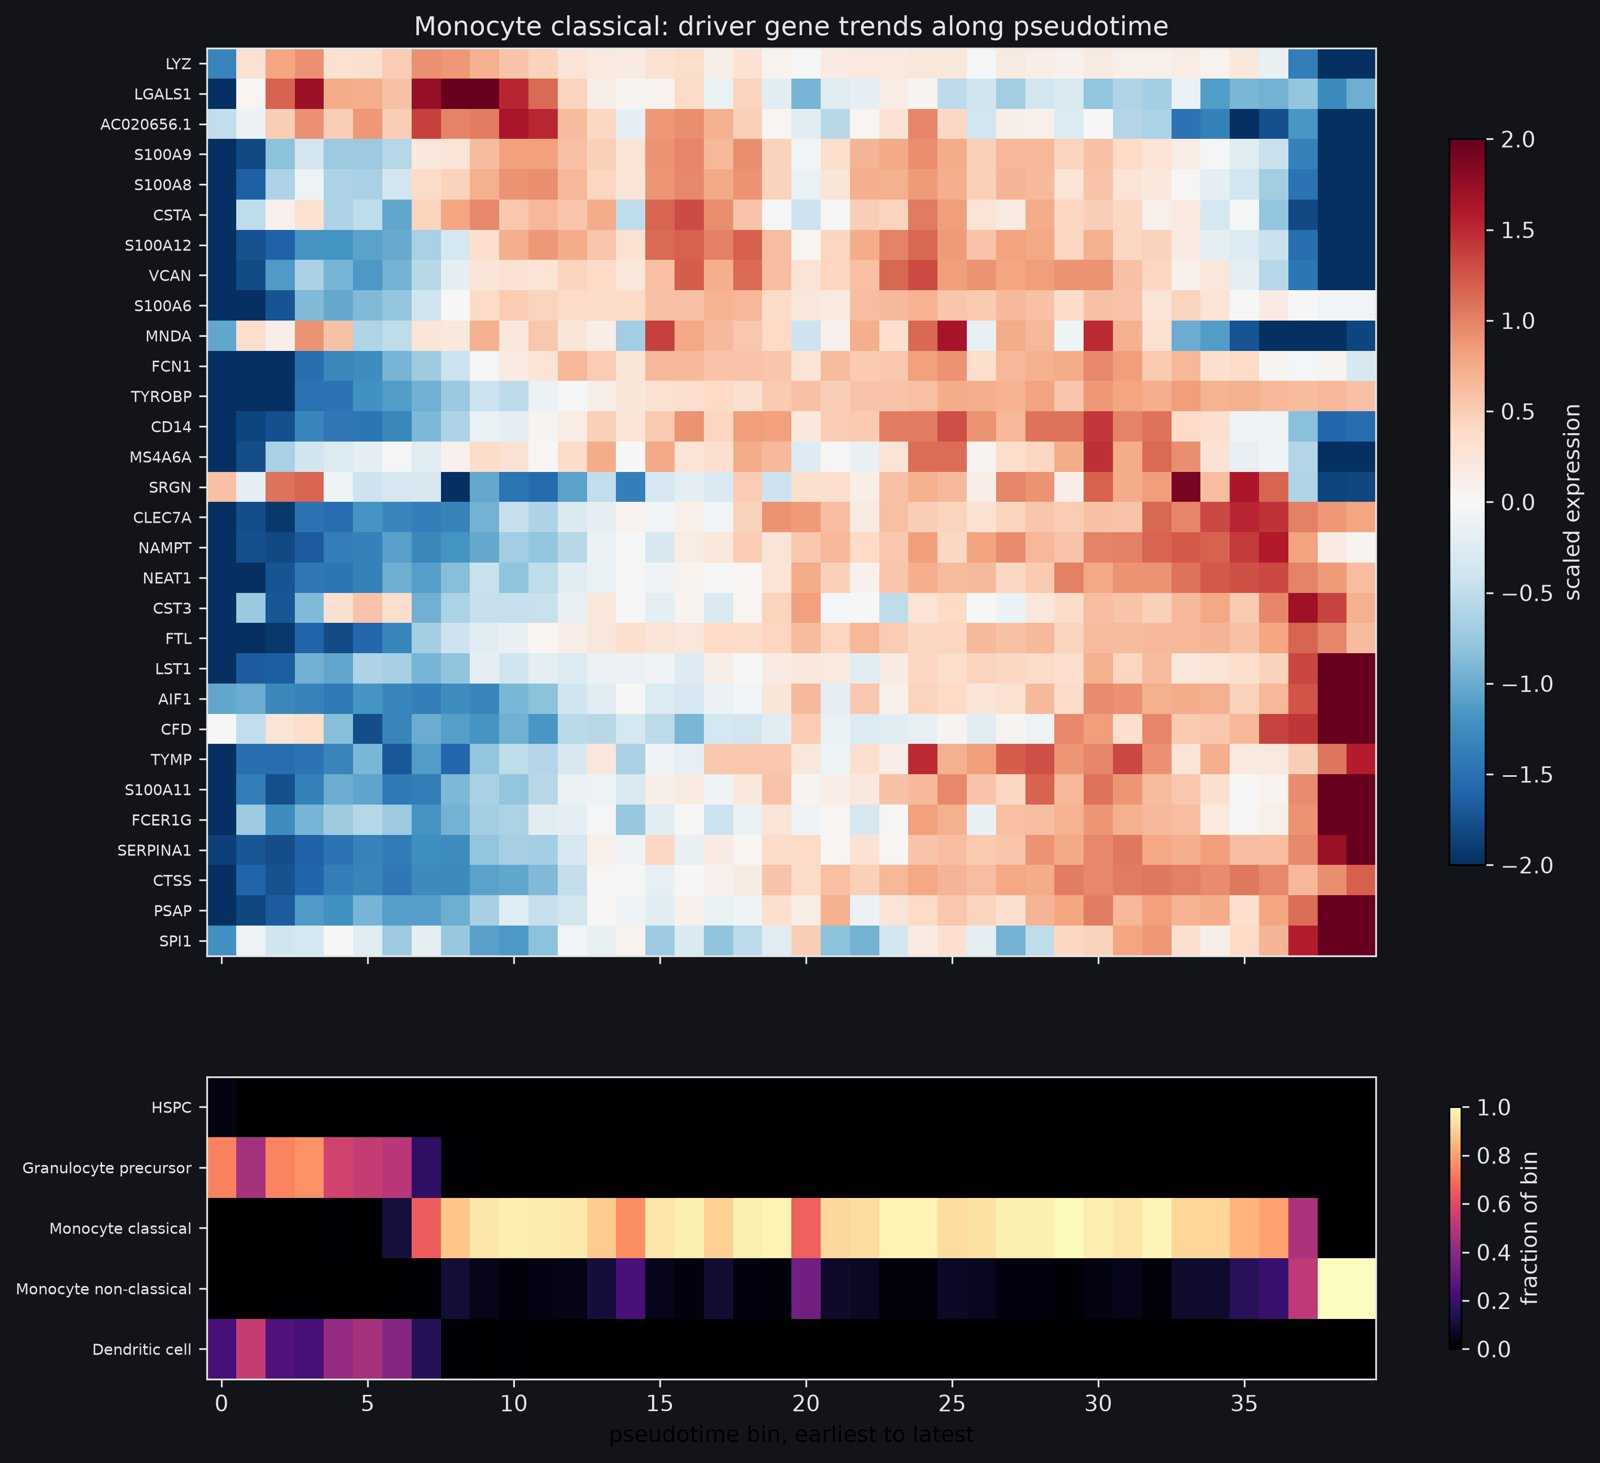

[Full-resolution figure](../figures/trajectory/gene_trends/gene_trends_monocyte_classical.png)

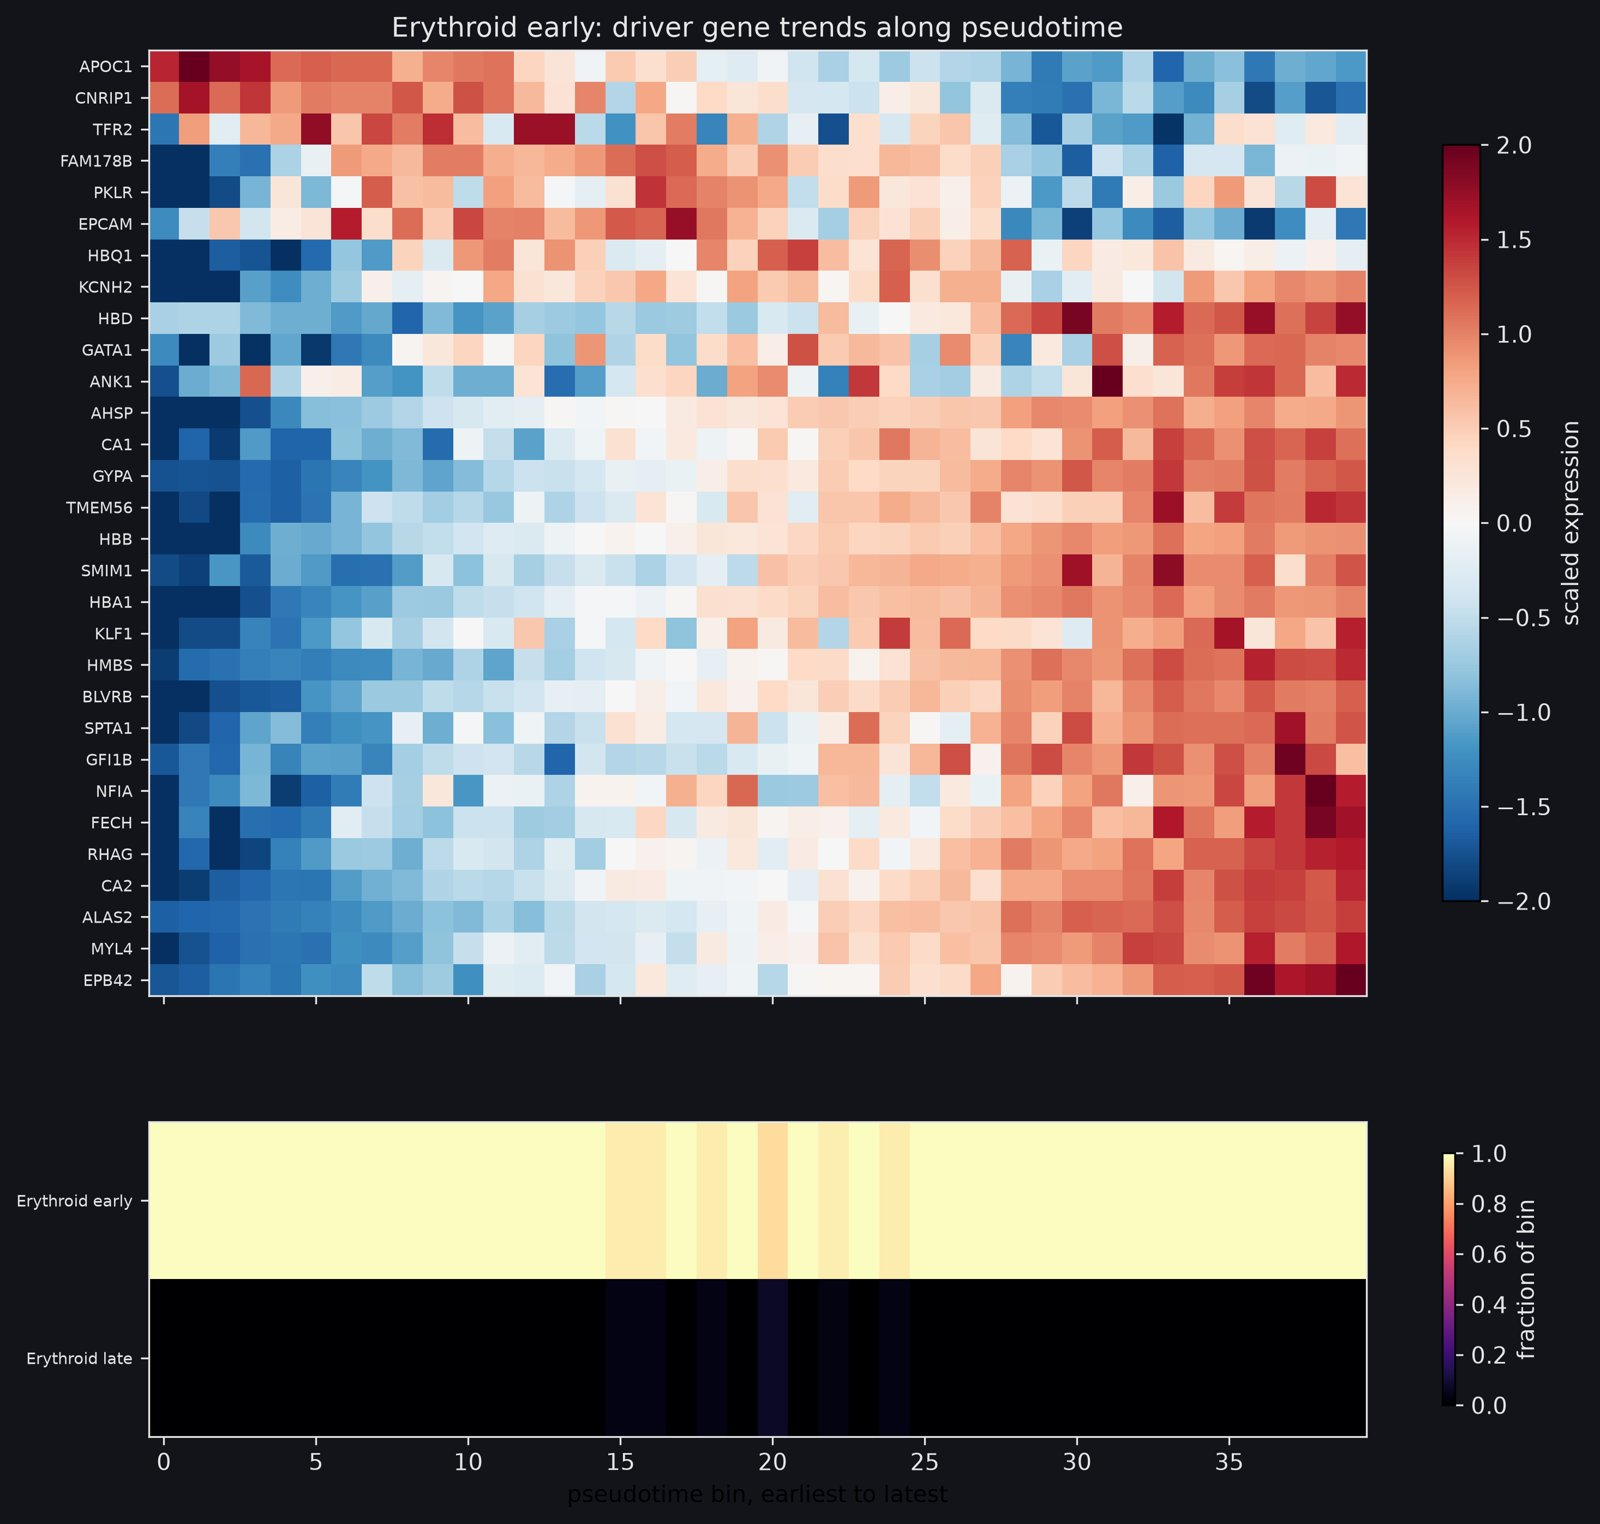

[Full-resolution figure](../figures/trajectory/gene_trends/gene_trends_erythroid_early.png)

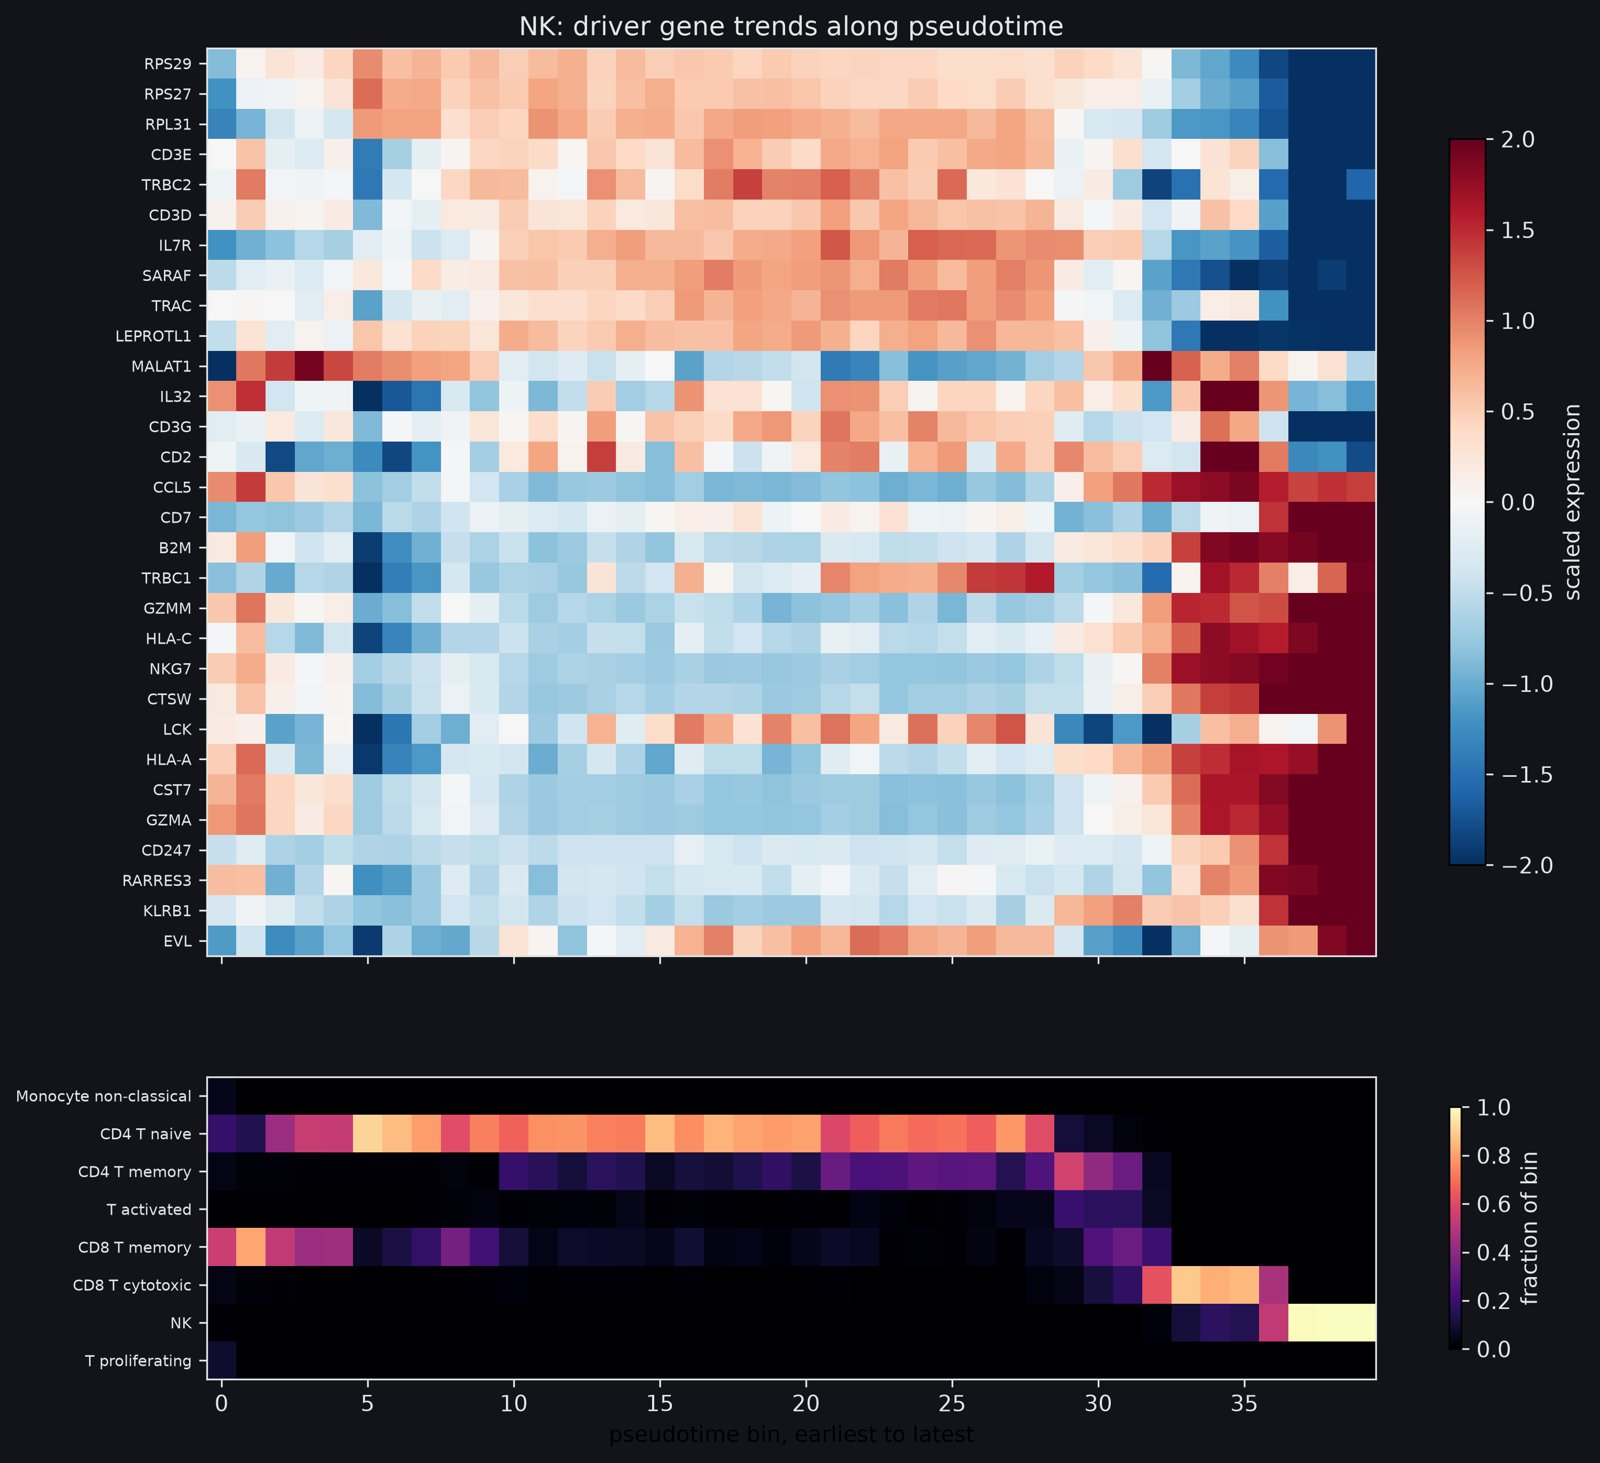

[Full-resolution figure](../figures/trajectory/gene_trends/gene_trends_nk.png)

In [16]:
for lineage in ("monocyte_classical", "erythroid_early", "nk"):
    show(f"trajectory/gene_trends/gene_trends_{lineage}.png", width=700)

- **Top: scaled expression per bin; bottom: label share per bin.** A clean
  diagonal from top left to bottom right means a correct gene order.
- **Monocyte:** the diagonal and the label handover line up - granulocyte
  precursors on the left, the non-classical block on the right.
- **Erythroid early:** the clearest diagonal; the bottom panel is one label
  throughout.
- **NK:** the late block (bins 33-39) is the cytotoxic programme and lines up
  exactly with the CD8 T cytotoxic -> NK handover below it.

## 6. Checking two odd results against raw counts

In [17]:
tail = table("trajectory/lineage_diagnostics/lineage_diagnostics_tail_summary.csv", index_col=0)
tail.set_index("group").round(3)

,n_cells,median_pseudotime,median_lineage_fate,median_n_genes_by_counts,median_n_genes,median_total_counts,median_pct_counts_mt,median_doublet_score,median_predicted_doublet
group,,,,,,,,,
Pre-B small in tail bins,172,0.859,0.948,574.0,574.0,1274.5,3.020,0.040,0.0
B naive in tail bins,130,0.852,0.975,630.0,630.0,1876.0,3.879,0.034,0.0
all Pre-B small,1025,0.832,0.942,660.0,660.0,1476.0,2.574,0.032,0.0
all committed B naive,6038,0.846,0.968,612.0,611.0,1879.0,3.609,0.028,0.0


- **The B naive tail (bins 38-39) holds 172 Pre-B small cells.** All 172 have
  B naive as their most likely fate (0.937-0.963), and none is a predicted
  doublet.
- **They are the shallowest cells in the lineage**: median 574 genes and 1,275
  counts, against 660 / 1,476 for all Pre-B small and 612 / 1,879 for committed
  B naive. Few counts make a cell's neighbours noisy, so it drifts away from the
  root. A Palantir depth effect, not a fate error.
- **The B naive axis is very compressed** (bins 38-39 span 0.851-0.866), so a
  small shift moves a cell many bins. Fine position along this axis carries
  little information; the label handover and the gene order still hold.
- **Not corrected**: the fix would be a stricter gene-count cut in the core
  pipeline, which would change every later stage for 0.45% of cells.

In [18]:
genes = table("trajectory/lineage_diagnostics/lineage_diagnostics_genes.csv", index_col=0)
focus = ["Erythroid early", "Erythroid late", "HSPC", "Platelet", "Plasmacytoid DC",
         "Pre-B large", "Pre-B small", "T proliferating"]
genes = genes[genes["cell_type"].isin(focus)]
pd.concat({
    "% expressing": genes.pivot(index="cell_type", columns="gene", values="pct_expressing").mul(100),
    "mean count when expressed": genes.pivot(index="cell_type", columns="gene", values="mean_expressing"),
}, axis=1).loc[focus].round(1)

% expressing                                     \
gene                   EPCAM HIST1H2AC HIST1H2BJ HIST1H3H PTCRA   
cell_type                                                         
Erythroid early         89.1      12.1       4.7      5.7   0.0   
Erythroid late          26.0       0.3       0.2      0.2   0.0   
HSPC                    12.4      13.2       1.7      5.1   0.9   
Platelet                 0.0      59.2      35.0     36.9  47.6   
Plasmacytoid DC          0.3      11.2       2.1      2.7  47.3   
Pre-B large              0.6      14.1       4.8      5.1   3.6   
Pre-B small              0.0      41.4       1.7      4.0   0.8   
T proliferating          0.0      10.6       2.1      4.3   0.0   

                mean count when expressed                                     
gene                                EPCAM HIST1H2AC HIST1H2BJ HIST1H3H PTCRA  
cell_type                                                                     
Erythroid early                       6.5       1.4       1.2      1.0   0.0  
Erythroid late                        1.6       1.0       1.0      1.0   0.0  
HSPC                                  1.7       1.5       1.1      1.1   1.2  
Platelet                              0.0      10.5       2.3      2.9   4.0  
Plasmacytoid DC                       1.0       1.4       1.4      1.2   1.9  
Pre-B large                           1.0       1.2       1.0      1.1   1.2  
Pre-B small                           0.0       1.9       1.1      1.1   1.0  
T proliferating                       0.0       1.4       1.0      1.0   0.0

- **Three driver genes looked wrong and were taken to the raw counts. All three
  are real.**
- **EPCAM in Erythroid early**: 89.1% of cells, mean 6.5 counts - confined to
  HSPC -> Erythroid early -> Erythroid late and absent from five unrelated labels.
  Ambient RNA would sprinkle evenly instead.
- **PTCRA in Platelet and Plasmacytoid DC**: about 47% of cells in both, with
  platelets at twice the count (4.0 against 1.9). Not spillover from pDCs.
- **Histone genes in platelets**: HIST1H2AC in 59.2% of platelets at 10.5
  counts, against 14.1% of Pre-B large and 10.6% of T proliferating at about
  one count. The dividing cells barely express them, so it is not a cell-cycle
  signal - most likely mRNA inherited from the parent megakaryocyte.
- **Rule: take any driver gene to the raw counts before believing it**, and read
  % expressing and mean count together.

## 7. Stage summary: certainty, order and method agreement

In [19]:
table("trajectory/trajectory_report/trajectory_report_summary.csv", index_col="cell_type")

,n_cells,median_pseudotime,mean_entropy,mean_top_probability,dominant_terminal
cell_type,,,,,
HSPC,973,0.129,0.804,0.335,NK
T proliferating,47,0.404,0.302,0.859,NK
Granulocyte precursor,926,0.530,0.414,0.754,Monocyte classical
CD8 T memory,2977,0.580,0.167,0.932,NK
Dendritic cell,497,0.585,0.439,0.747,Monocyte classical
CD4 T naive,10765,0.589,0.256,0.882,NK
CD4 T memory,2713,0.594,0.239,0.893,NK
Platelet,103,0.595,0.380,0.736,Platelet
T activated,583,0.599,0.231,0.897,NK


- **`mean_entropy`**: how spread a cell's 8 fate probabilities are, 0 = one
  fate, 1 = all equal. Ranked, it is a developmental-potential scale nobody
  supplied.
- **HSPC is the least committed population (0.804)** and the only one whose
  top fate holds less than half the probability (0.335). The strongest
  positive result of the stage.
- **Next come the real intermediates**: Dendritic cell 0.439, Granulocyte
  precursor 0.414; finished cells sit lowest (B naive 0.087, NK 0.046).
- **`dominant_terminal` for HSPC reads NK only by 0.04** - an argmax over a
  nearly flat row; read it next to the entropy.
- **The median pseudotime (Palantir) starts at HSPC 0.129 with a 0.27 gap**
  to the next label; 17 of 19 labels then fall between 0.530 and 0.857.

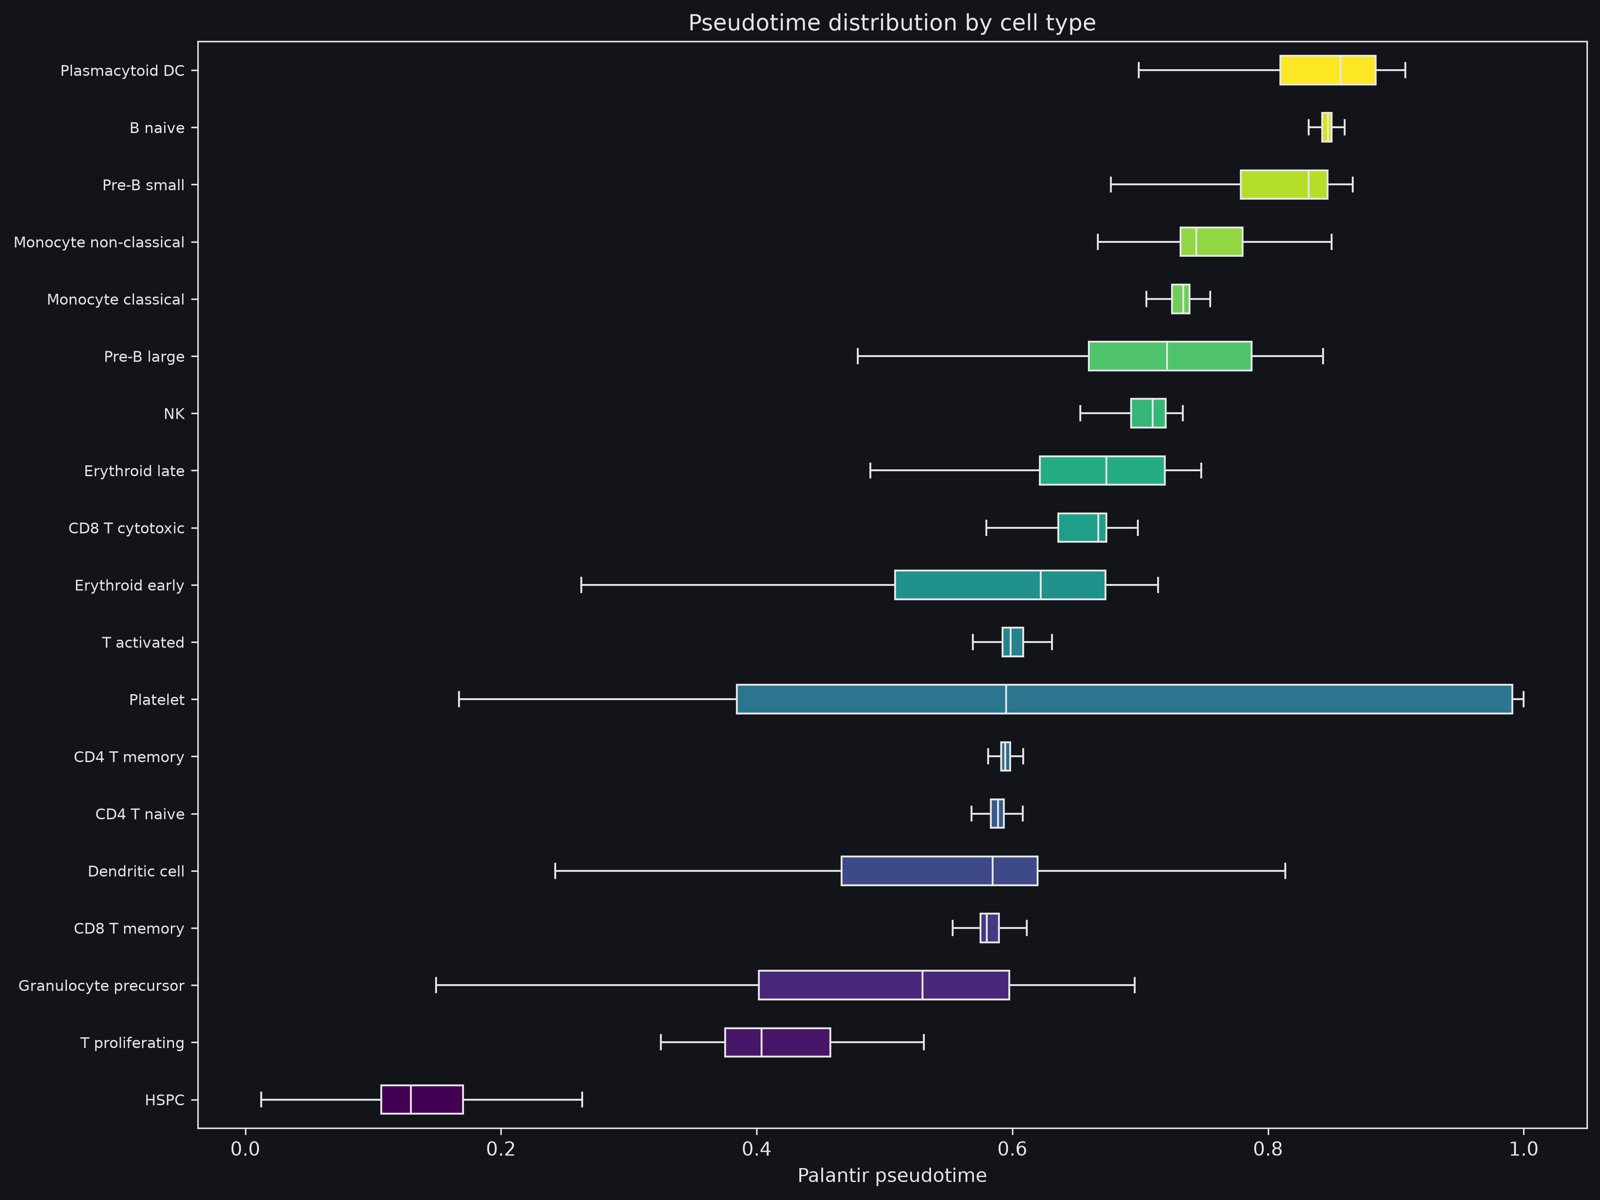

[Full-resolution figure](../figures/trajectory/trajectory_report/trajectory_report_pseudotime_by_celltype.png)

In [20]:
show("trajectory/trajectory_report/trajectory_report_pseudotime_by_celltype.png", width=750)

- **Ordered by median.** HSPC is alone at the left.
- **Narrow boxes** (B naive, Monocyte classical, CD4 T naive and memory, CD8 T
  memory, T activated, NK): large, uniform populations - their order between
  labels can be read, their order inside cannot.
- **The Platelet box spans almost the whole axis** (box about 0.38-0.99): the
  103 platelets carry no usable position; the upper half is the bright speck
  (section 13).
- **Plasmacytoid DC is last (0.857)**: furthest from the root in the diffusion
  space, which is transcriptional distance, not time.

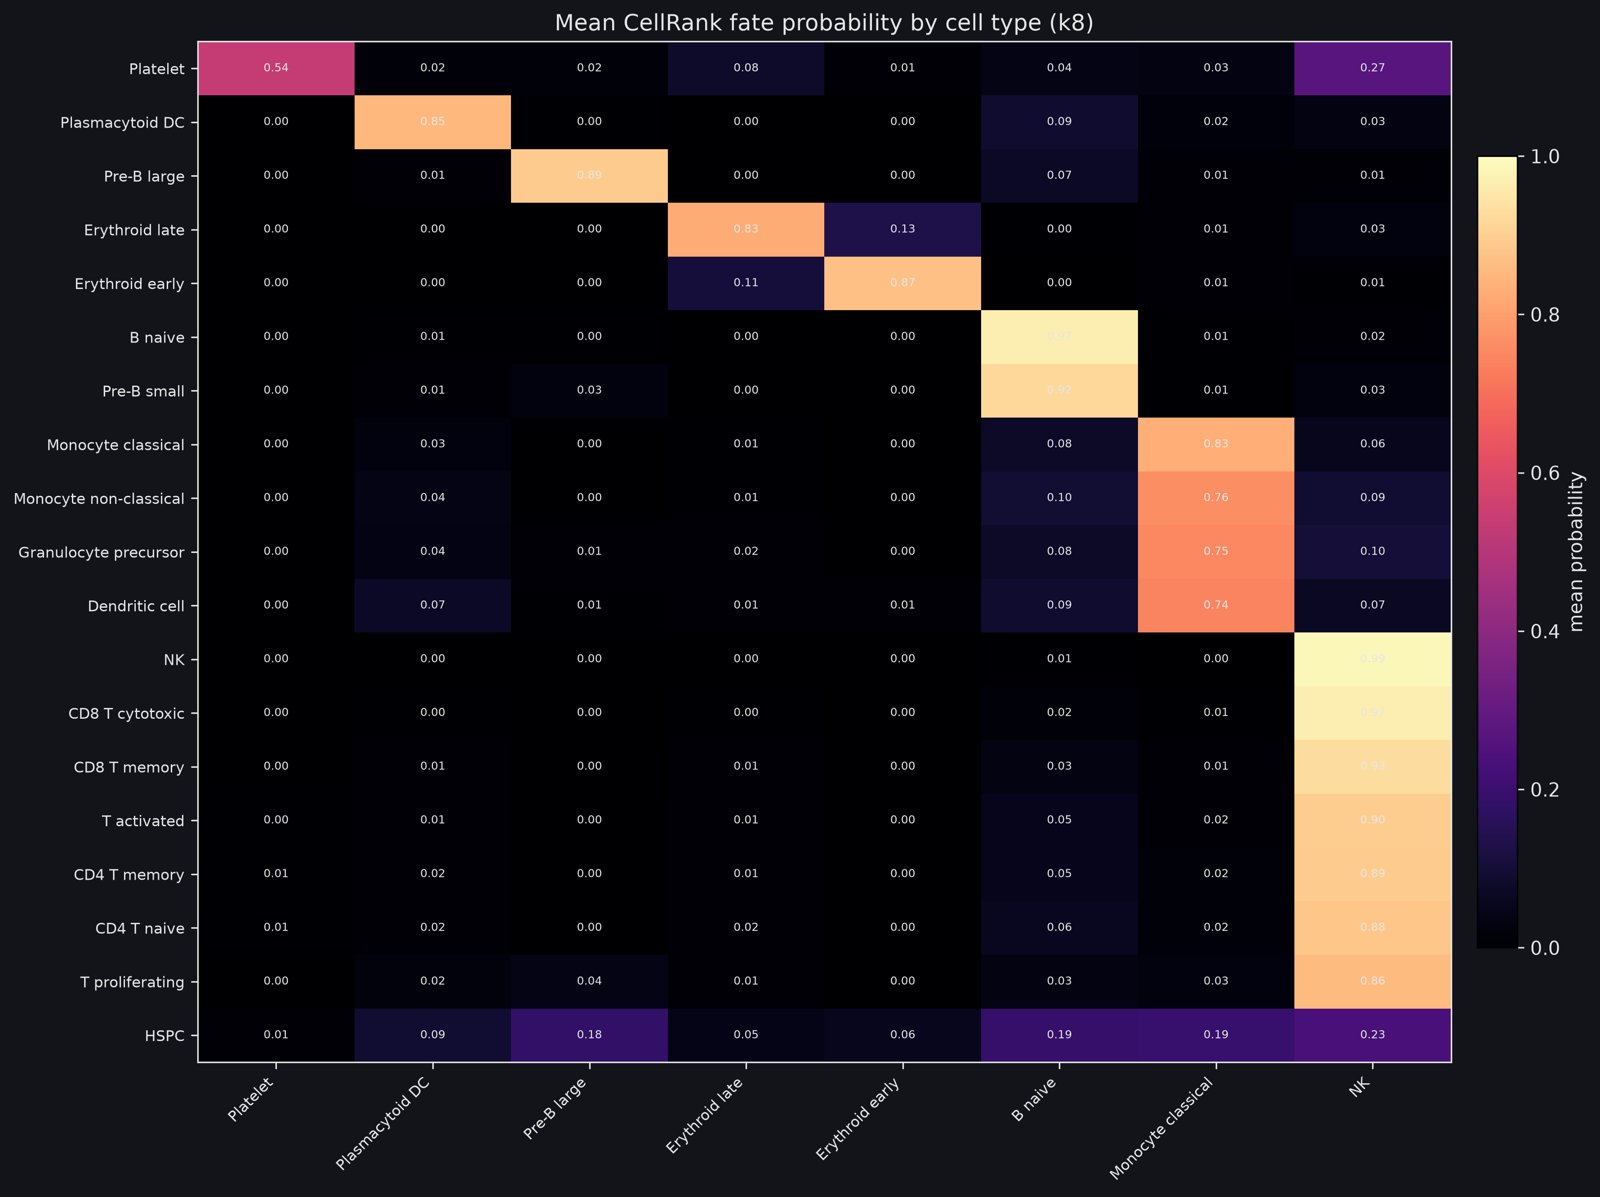

[Full-resolution figure](../figures/trajectory/trajectory_report/trajectory_report_fate_matrix.png)

In [21]:
show("trajectory/trajectory_report/trajectory_report_fate_matrix.png", width=750)

- **The same 8-state fate table as section 3, as a picture**: strong diagonal,
  the myeloid block in the Monocyte column, and the whole lymphoid block in the
  NK column - the right-hand column is the negative result.
- **The HSPC row (bottom) is the only row with colour spread across many
  columns.**

In [22]:
table("trajectory/trajectory_report/trajectory_report_method_agreement.csv", index_col=0).round(2)

,Platelet,Plasmacytoid DC,Pre-B large,Erythroid late,Erythroid early,B naive,Monocyte classical,NK
Monocyte classical | CACCTTGGTTGCGTTA-1-MantonBM6,-0.05,0.16,0.02,0.01,0.02,-0.21,0.98,-0.59
NK | GTACTTTTCTTGTATC-1-MantonBM2,0.00,-0.11,-0.10,0.06,0.02,-0.62,-0.61,0.94
Platelet | GTTTCTACAATAACGA-1-MantonBM2,0.97,-0.01,-0.01,-0.01,-0.01,-0.02,-0.02,-0.04
B naive | TAGCCGGAGGTCGGAT-1-MantonBM2,-0.05,-0.02,0.12,-0.07,-0.05,0.98,-0.23,-0.57


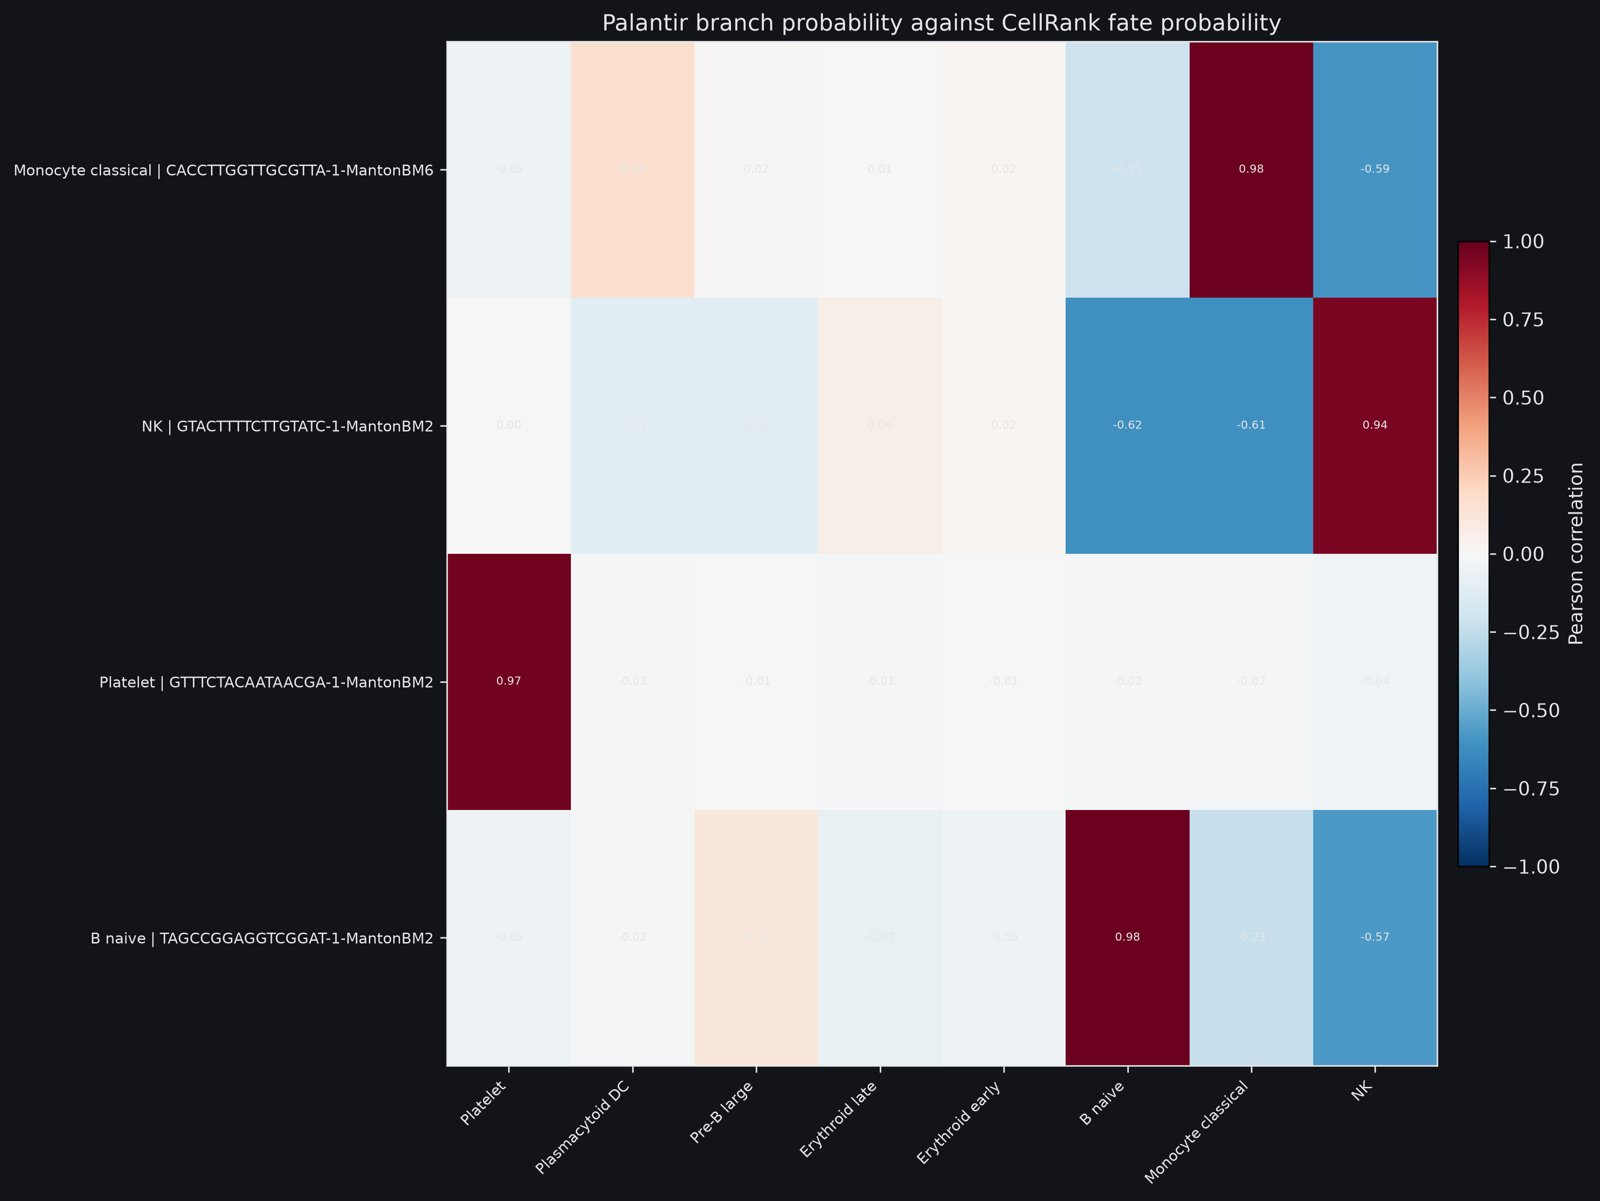

[Full-resolution figure](../figures/trajectory/trajectory_report/trajectory_report_method_agreement.png)

In [23]:
show("trajectory/trajectory_report/trajectory_report_method_agreement.png", width=700)

- **Correlation of each Palantir branch with each CellRank fate**, over all
  38,430 cells. The two methods share only the expression data.
- **Four end points are confirmed by both**: Monocyte classical 0.98, B naive
  0.98, Platelet 0.97, NK 0.94. These four are properties of the data, not of
  one algorithm.
- **Four CellRank end points have no Palantir branch** (Plasmacytoid DC,
  Pre-B large, both erythroid): no value above 0.16 in those columns.
- **The large negatives are bookkeeping**: probabilities sum to 1, so the big
  basins (NK, B naive, Monocyte) must anticorrelate (−0.57 to −0.62).

## 8. The backbone on the real map

In [24]:
edges = table("trajectory/trajectory_backbone/trajectory_backbone_tree_edges.csv")
edges["length"] = ((edges["source_x"] - edges["target_x"]) ** 2
                   + (edges["source_y"] - edges["target_y"]) ** 2) ** 0.5
display(edges["length"].describe()[["mean", "50%"]].rename({"50%": "median"}).round(2).to_frame().T)
edges.sort_values("length", ascending=False)[["source", "target", "connectivity", "length"]].round(3)

,mean,median
length,4.64,3.67


,source,target,connectivity,length
16,T activated,Plasmacytoid DC,0.137,11.267
1,T proliferating,CD4 T memory,0.914,10.912
11,Dendritic cell,Plasmacytoid DC,0.286,7.477
10,HSPC,Granulocyte precursor,0.304,4.453
13,Pre-B large,Pre-B small,0.228,4.284
17,Pre-B small,B naive,0.038,4.272
15,Platelet,Erythroid late,0.156,4.177
5,HSPC,Pre-B large,0.698,4.125
4,HSPC,Platelet,0.707,3.681
7,CD4 T memory,T activated,0.396,3.664


- **The PAGA spanning tree** (strongest 18 edges joining all 19 labels) drawn
  between cell-type centres on the UMAP, so every edge gets a length.
- **Two edges are three times the median length (3.67)**:
  - T activated-Plasmacytoid DC (0.137, 11.27): the tree's only link between
    the mature lymphoid block and the rest, invented to keep the tree
    connected.
  - T proliferating-CD4 T memory (0.914, 10.91): the second strongest edge in
    the data spans the map - high connectivity plus long distance is the mark
    of a tiny group (47 cells).
- **Remove the one bridge and the tree splits in two**: 7 lymphoid labels
  (21,545 cells) against the 12 progenitor-side labels.
- **The B lineage, the one series recovered end to end, hangs on the weakest
  edge** (Pre-B small-B naive, 0.038).

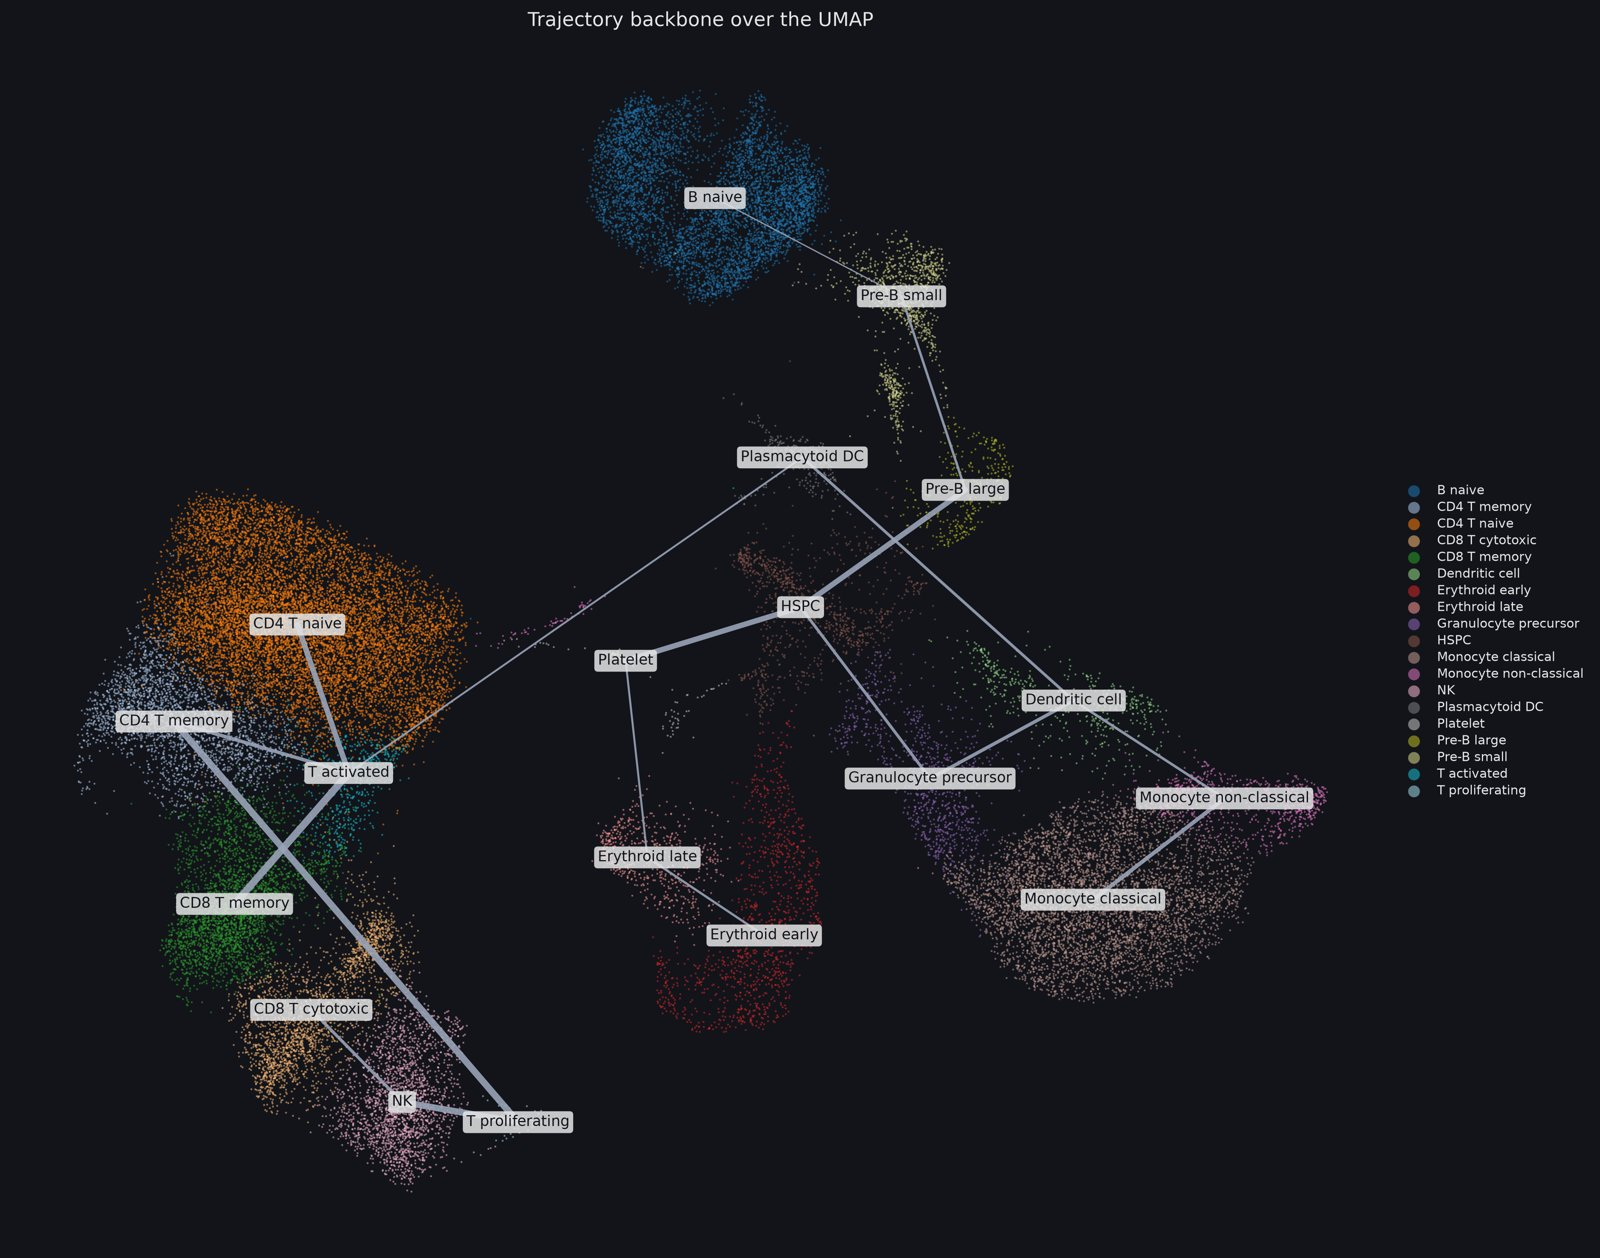

[Full-resolution figure](../figures/trajectory/trajectory_backbone/trajectory_backbone_tree_cell_type.png)

In [25]:
show("trajectory/trajectory_backbone/trajectory_backbone_tree_cell_type.png")

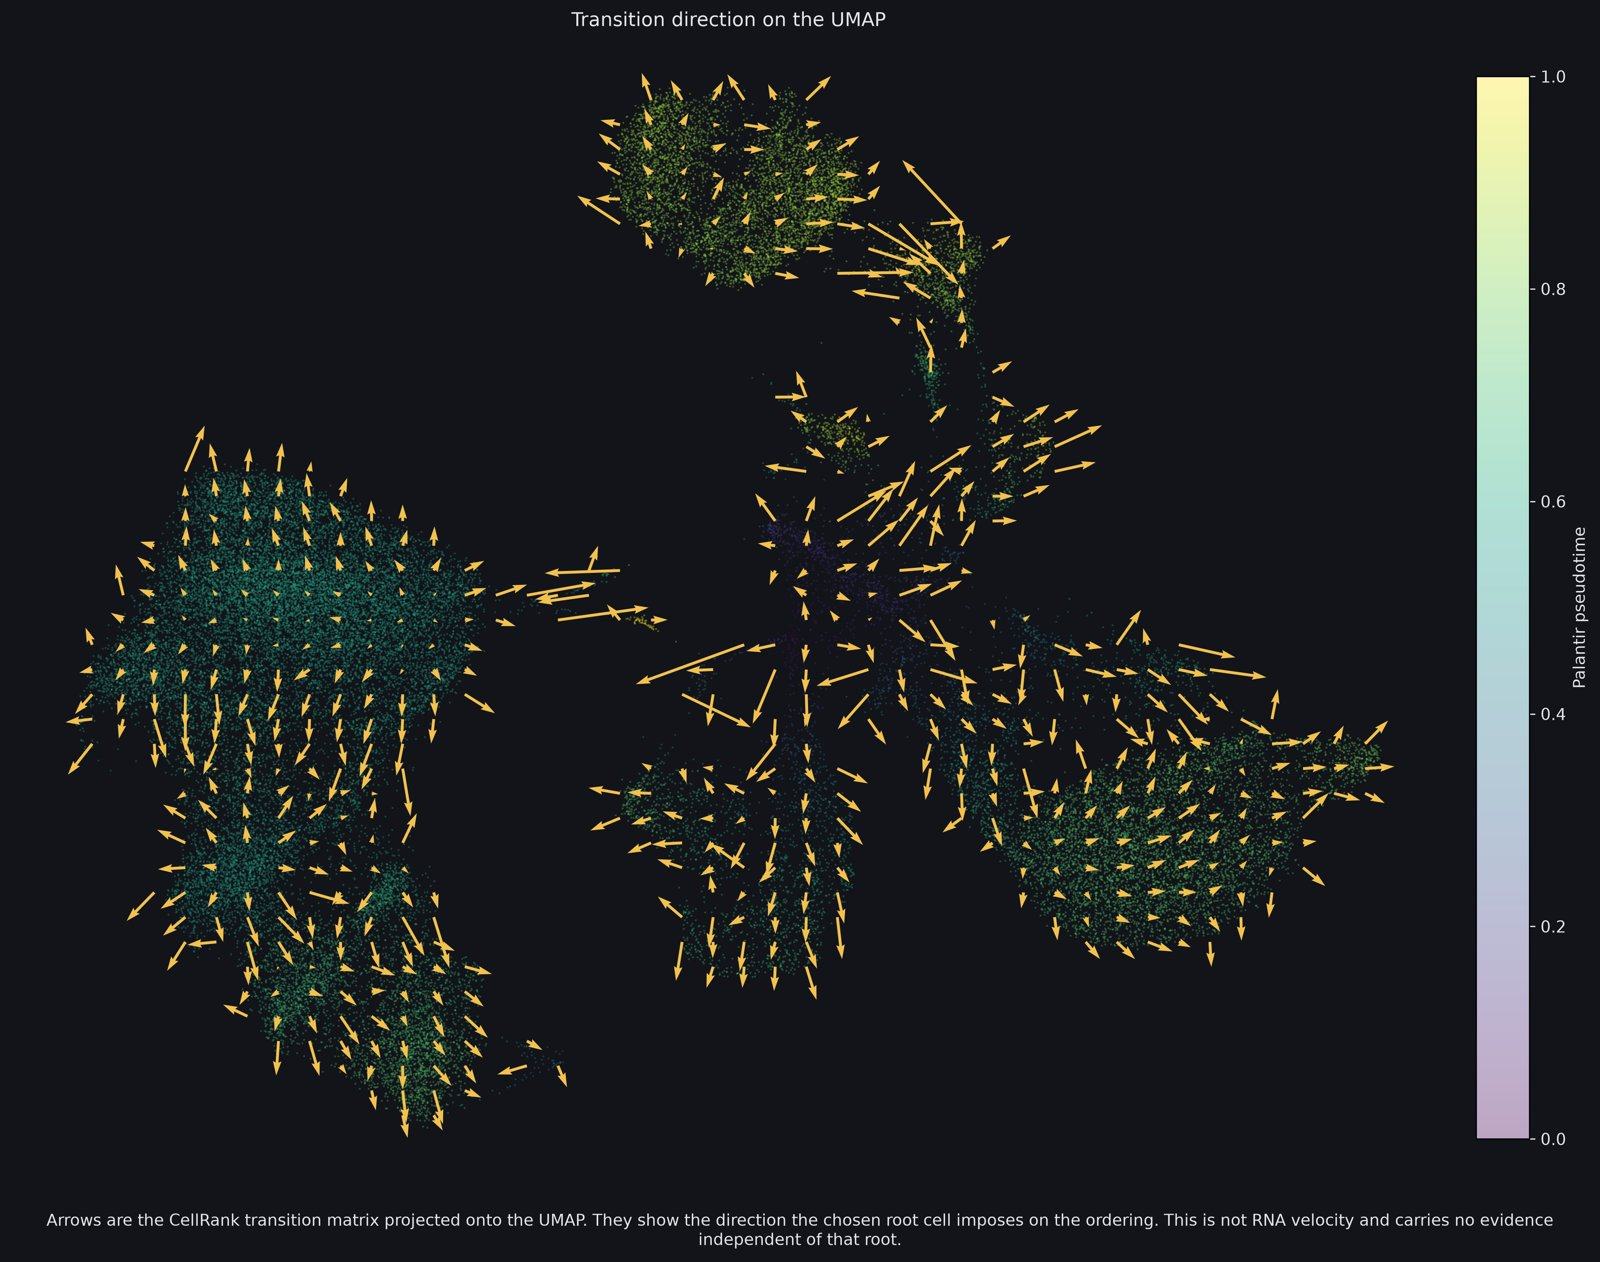

[Full-resolution figure](../figures/trajectory/trajectory_backbone/trajectory_backbone_arrows.png)

In [26]:
show("trajectory/trajectory_backbone/trajectory_backbone_arrows.png")

- **Arrow field = the CellRank transition matrix projected on the UMAP.** It
  shows the direction the chosen root imposes. **It is not RNA velocity**, and
  the figure says so in its caption.
- **Arrows leave the HSPC hub into the surrounding islands.**
- **Inside the T region they run in one consistent direction (top to bottom,
  toward CD8 and NK)**, which looks like a differentiation front. That island
  hangs on one invented edge, so the direction there is only distance from a
  root the cells are not related to. Section 10 shows velocity disagrees.

## 9. Principal tree: a second geometry

In [27]:
segments = table("trajectory/principal_graph/principal_graph_segments.csv")
labels = segments.columns[5:]
segments["contents"] = [
    ", ".join(f"{label} {int(row[label])}" for label in labels if row[label] >= 20)
    for _, row in segments.iterrows()
]
display(segments[["segment", "from", "to", "length", "cells", "contents"]].round(2))
empty = segments.loc[segments["cells"] <= 3, "length"].sum()
print(f"length on segments with 3 cells or fewer: {empty:.2f} of {segments['length'].sum():.2f} "
      f"({empty / segments['length'].sum():.0%})")

,segment,from,to,length,cells,contents
0,1,22,3,3.71,6000.0,"B naive 5016, Pre-B small 982"
1,2,44,6,1.50,14520.0,"CD4 T memory 2703, CD4 T naive 10761, CD8 T memory 446, Monocyte non-classic..."
2,3,42,8,1.47,1128.0,"Monocyte classical 314, Monocyte non-classical 814"
3,4,26,18,2.63,1162.0,"Dendritic cell 316, Granulocyte precursor 806, HSPC 31"
4,5,22,31,1.46,0.0,
5,6,45,22,3.53,1382.0,"Erythroid early 42, Granulocyte precursor 27, HSPC 934, Pre-B large 334, Pre..."
6,7,26,23,1.87,335.0,Plasmacytoid DC 318
7,8,44,25,2.61,7062.0,"CD8 T cytotoxic 2302, CD8 T memory 2531, NK 2153, T activated 20, T prolifer..."
8,9,42,26,4.59,5029.0,"Dendritic cell 170, Granulocyte precursor 91, Monocyte classical 4716, Monoc..."
9,10,31,28,1.73,0.0,


length on segments with 3 cells or fewer: 7.16 of 39.59 (18%)


- **A scFates principal tree** (50 points, length penalty 1000) fitted on the
  first 10 `diffmap_pca` components, rooted at the stage root cell.
  The penalty was the only setting that reduced the number of end points, and
  it stops at 10 tips (9 plus the root).
- **18% of the tree runs through empty space**: three segments hold no cells
  and one holds three. A high length penalty makes straight short-cuts across
  gaps cheaper than curves through cells.
- **The trunk runs through the B lineage**: every non-B lineage leaves from a
  fork (node 31) that holds less than one cell.
- **The myeloid compartment is entered from the wrong end**: the tree reaches
  the monocytes first and the granulocyte precursors last.

In [28]:
display(table("trajectory/principal_graph/principal_graph_agreement.csv"))
table("trajectory/principal_graph/principal_graph_by_celltype.csv", index_col="cell_type")

,statistic,value,p_value
0,spearman,-0.42,0.000e+00
1,pearson,0.04,7.051e-15


,cells,median_graph,median_palantir,rank_graph,rank_palantir,rank_shift
cell_type,,,,,,
HSPC,973,3.575e-10,0.129,1,1,0
Pre-B large,334,1.409e-01,0.721,2,14,-12
Pre-B small,1025,4.120e-01,0.832,3,17,-14
B naive,5018,5.046e-01,0.847,4,18,-14
Monocyte classical,5030,5.525e-01,0.734,5,15,-10
Erythroid early,1151,5.963e-01,0.622,6,10,-4
Monocyte non-classical,901,5.986e-01,0.744,7,16,-9
Platelet,103,6.351e-01,0.595,8,8,0
CD8 T memory,2977,6.498e-01,0.580,9,4,5


- **Over all cells the tree is anticorrelated with Palantir (Spearman
  −0.42).** The cause is the topology above, not noise.
- **Granulocyte precursor is last in the tree (1.000) but third in
  Palantir** - the myeloid inversion; Dendritic cell is also near the end
  (0.910).
- **Several labels collapse to one value** (Pre-B large 0.141, B naive 0.505,
  Plasmacytoid DC 0.947): 50 points are too coarse to order cells inside them.
- **Where the tree follows cells continuously it agrees with Palantir**: the
  erythroid lineage at +0.89, and six branches at +0.73 or better (from
  `principal_graph_pseudotime.csv`).
- **The lymphoid block is again joined by an invented link - at a different
  place from PAGA's** (through the platelet fork, not Plasmacytoid DC). Two
  methods bridging the same gap in two places is direct evidence that no real
  connection exists.
- **Palantir stays the stage's ordering**; the tree is used as a topology
  check only.

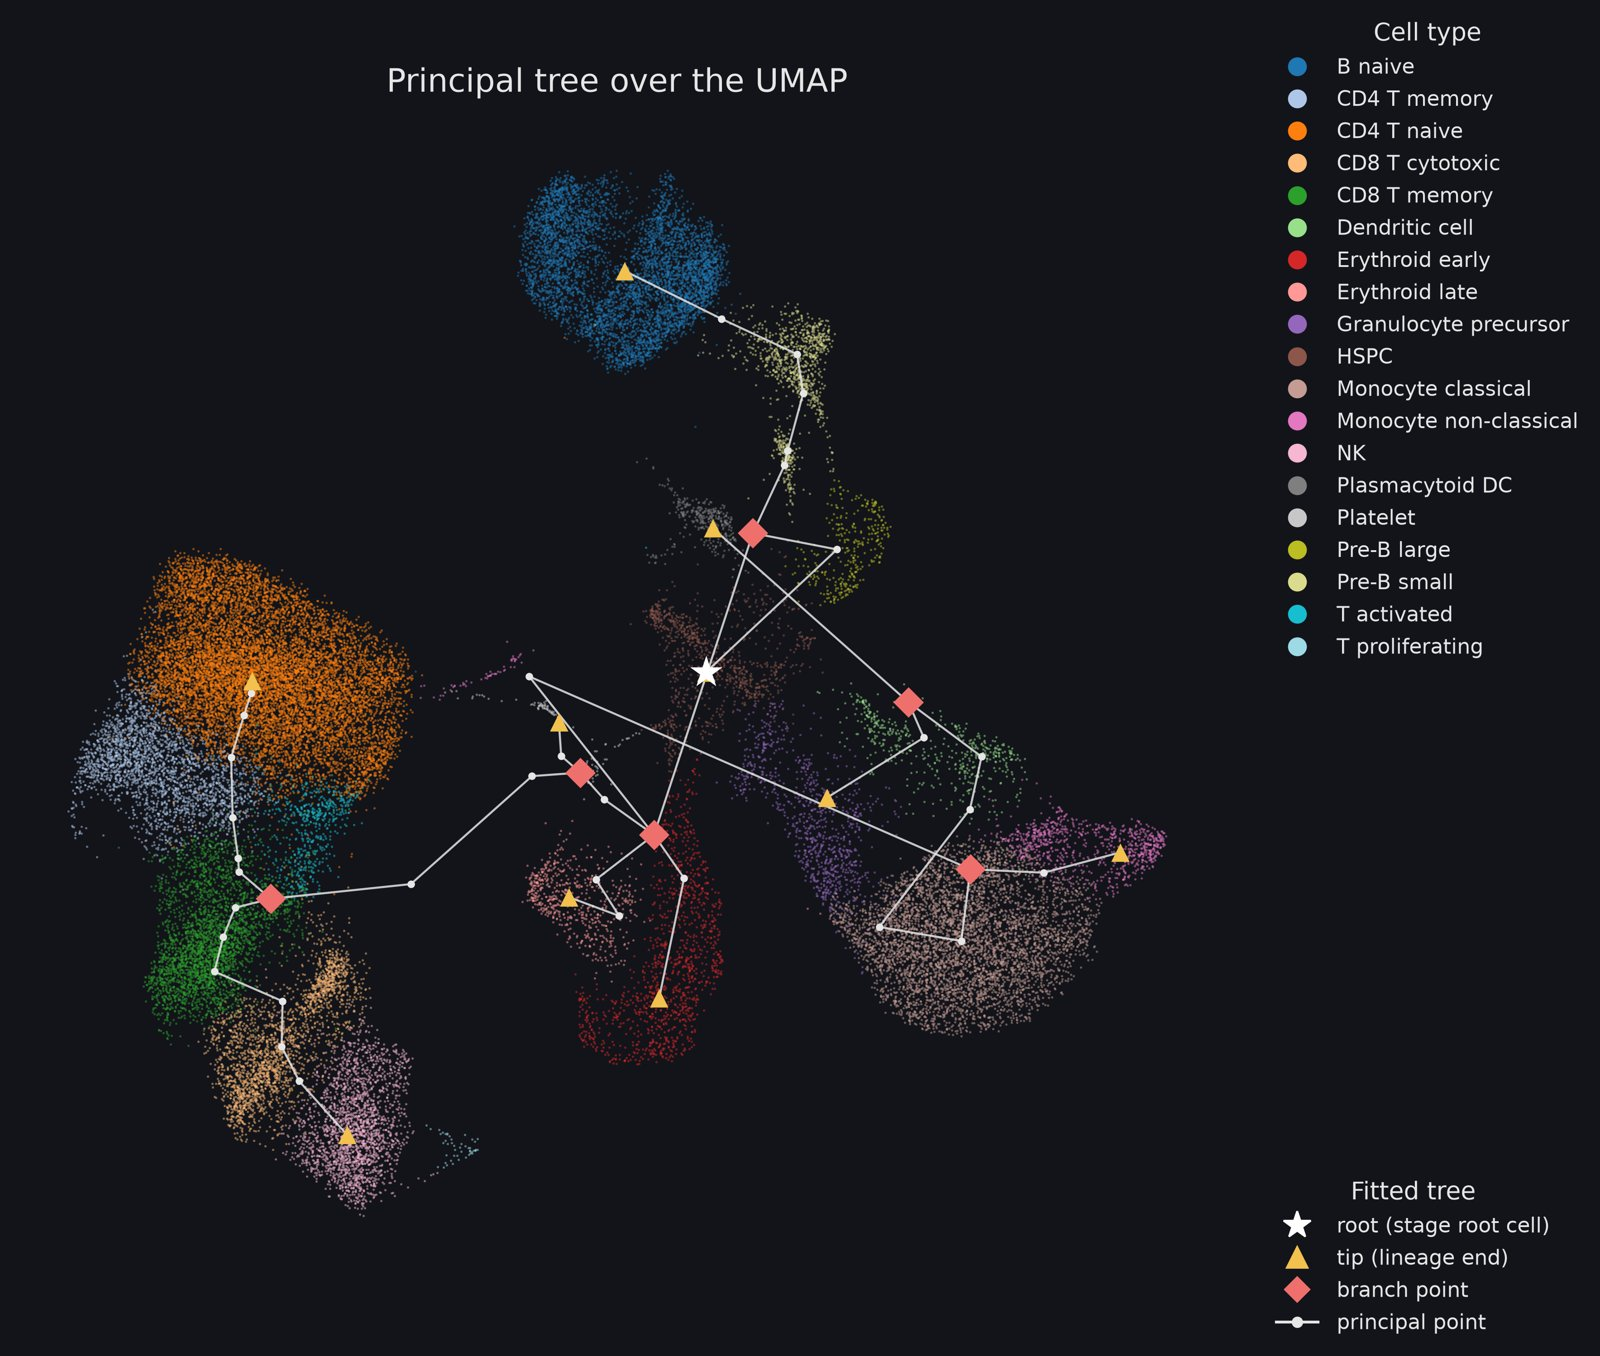

[Full-resolution figure](../figures/trajectory/principal_graph/principal_graph_umap.png)

In [29]:
show("trajectory/principal_graph/principal_graph_umap.png", width=750)

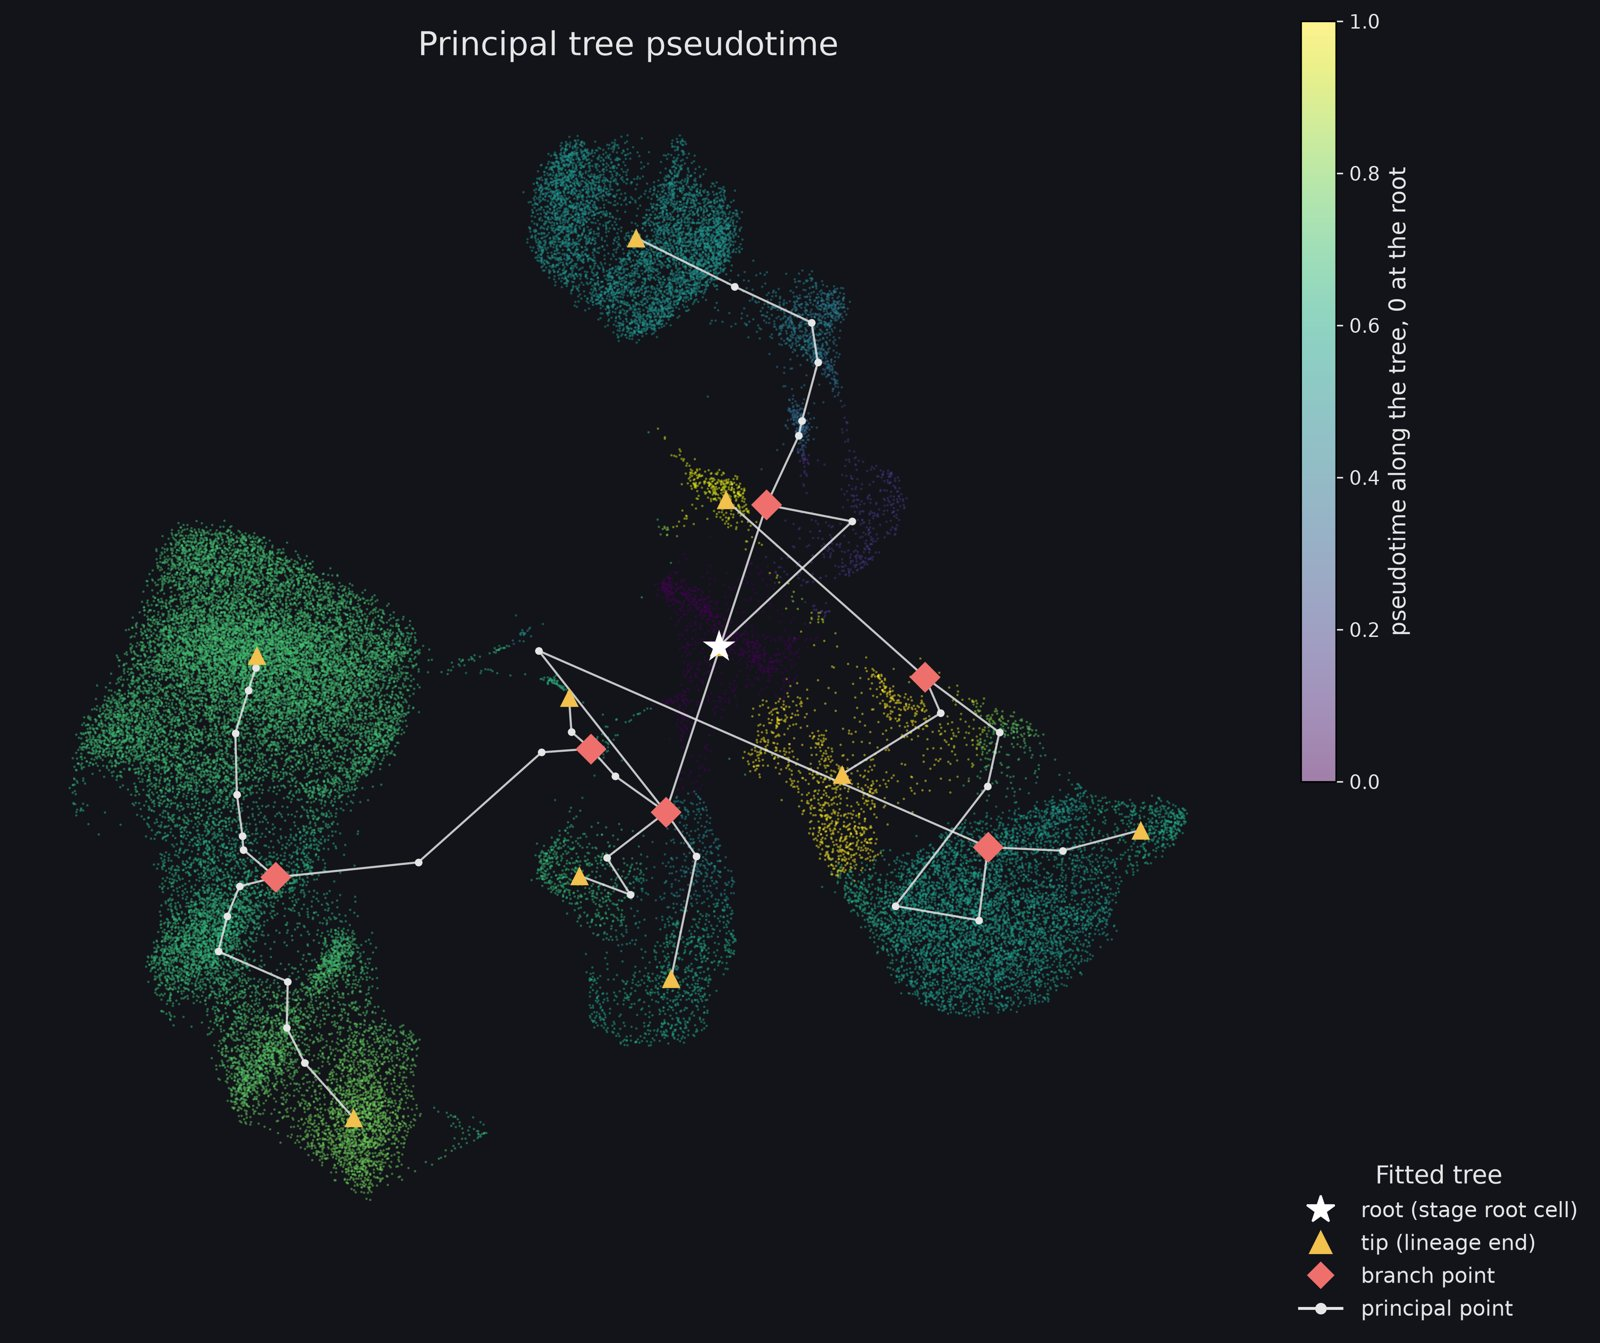

[Full-resolution figure](../figures/trajectory/principal_graph/principal_graph_pseudotime.png)

In [30]:
show("trajectory/principal_graph/principal_graph_pseudotime.png", width=750)

- **Long straight lines cross empty space** between islands: from the pre-B
  fork past the root, from the erythroid hub across to the monocytes, and to
  the T block.
- **The pseudotime map shows the inversion without numbers**: the granulocyte
  and dendritic cells (right of centre) are the brightest yellow, right beside
  the dark HSPC hub.

## 10. RNA velocity - data preparation

- **Why:** velocity is the one check whose direction does not come from the
  root cell.
- **Source:** the HCA BAM files (aligned reads), one per lane. velocyto 0.17.17
  counted spliced and unspliced reads per cell against GENCODE v27 with a
  repeat mask, restricted to the 38,430 kept cells (about 49 min per lane).

,lane,cells,dominant_type,dominant_share
0,MantonBM1,4553,CD4 T naive,0.351
1,MantonBM2,5073,B naive,0.260
2,MantonBM3,4542,CD4 T naive,0.220
3,MantonBM4,4694,Monocyte classical,0.228
4,MantonBM5,4582,CD4 T naive,0.250
5,MantonBM6,4917,CD4 T naive,0.411
6,MantonBM7,5038,CD4 T naive,0.371
7,MantonBM8,5031,CD4 T naive,0.298


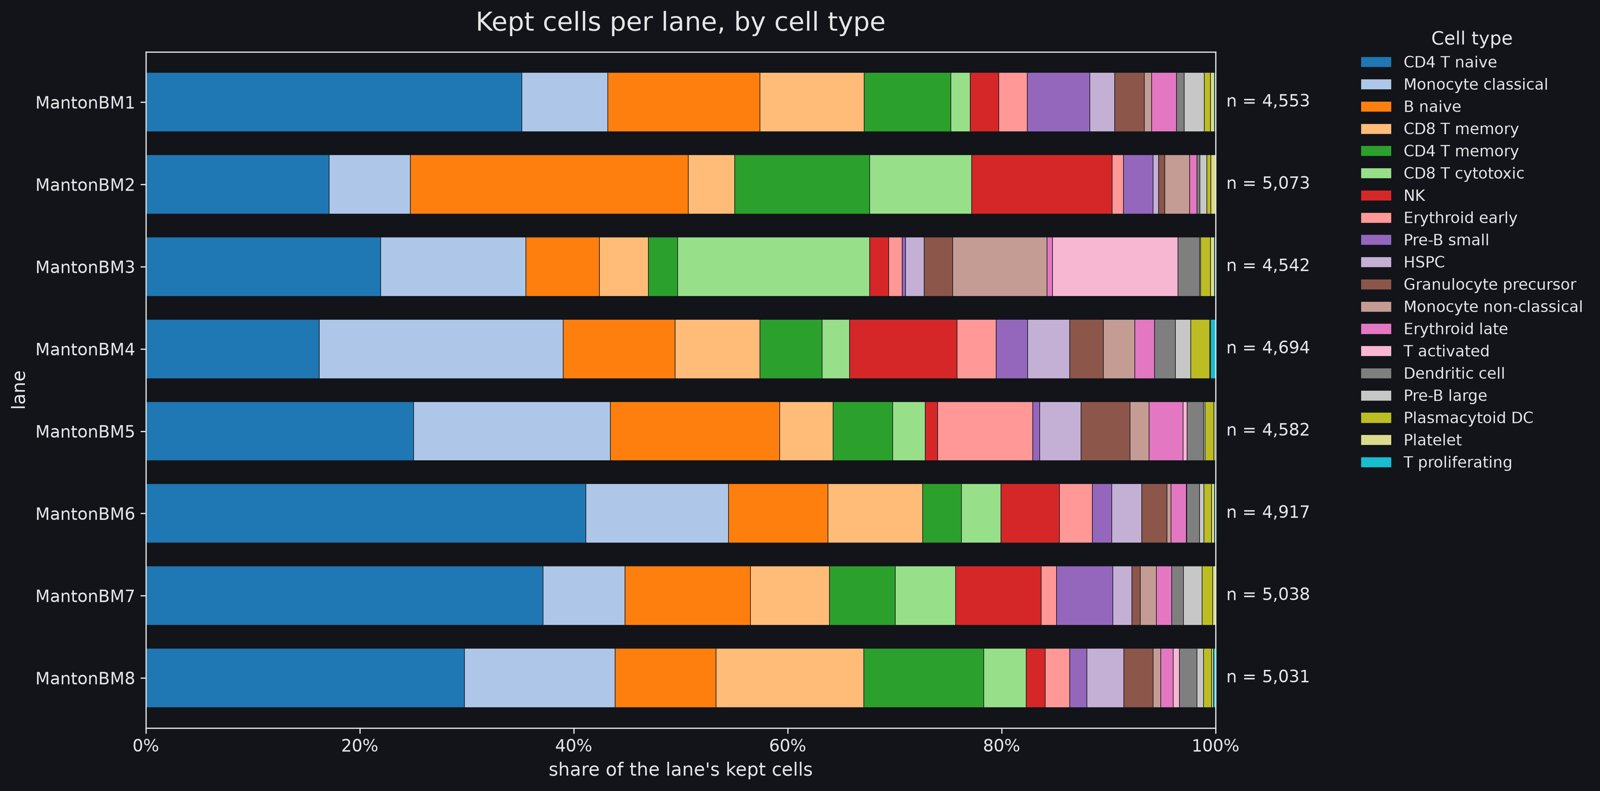

[Full-resolution figure](../figures/trajectory/velocity_barcodes/velocity_barcodes_composition.png)

In [31]:
display(table("trajectory/velocity_barcodes/velocity_barcodes_summary.csv").drop(columns="file"))
show("trajectory/velocity_barcodes/velocity_barcodes_composition.png")

- **Lane size is even (4,542-5,073 cells); lane content is not.**
- **Two lanes are not led by CD4 T naive**: MantonBM2 (B naive 26%) and
  MantonBM4 (Monocyte classical 23%). CD4 T naive ranges 22-41% elsewhere.
- **MantonBM3 is unusual**: about 18% CD8 T cytotoxic and almost all of T
  activated (532 of 583 cells; the pink band). MantonBM5 holds the largest
  erythroid share.
- **Consequence:** a technical difference between lanes would look like a
  difference between cell types, so every velocity check is made per lane
  first.

In [32]:
recovery = table("trajectory/velocity_counts/velocity_counts_recovery_cell_type.csv", index_col="cell_type")
print("cells recovered:", recovery["recovered"].sum(), "of", recovery["expected"].sum())
recovery["median_unspliced_fraction"].sort_values(ascending=False).round(3).to_frame()

cells recovered: 38430 of 38430


,median_unspliced_fraction
cell_type,
CD8 T cytotoxic,0.113
Pre-B small,0.111
NK,0.110
CD8 T memory,0.110
T activated,0.109
CD4 T naive,0.098
B naive,0.096
CD4 T memory,0.095
Plasmacytoid DC,0.090


- **Every kept cell was recovered** - 38,430 of 38,430, and 148 of 148
  lane × cell-type groups at 100%. That rules out a wrong lane-to-file match, a
  barcode format mismatch or a truncated file.
- **Unspliced fraction = unspliced / all counted molecules per cell**, the raw
  signal velocity is built on.
- **It splits by compartment**: mature lymphoid and Pre-B small 0.095-0.113;
  myeloid and HSPC 0.061-0.084; erythroid and platelet 0.045-0.054.
- **Platelets set a floor (0.050)**: they have no nucleus and make no new RNA,
  so their "unspliced" reads are background. **Erythroid late (0.045) is at
  that floor** - velocity there has nothing to read.
- **The signal is strongest in the non-developmental lymphoid block and weakest
  in the real erythroid series**: confidence and meaning will run in opposite
  directions.

In [33]:
lanes = table("trajectory/velocity_counts/velocity_counts_lane_summary.csv", index_col="lane")
display(lanes[["median_unspliced_fraction", "pooled_unspliced_fraction", "deviation_from_lane_median",
               "flagged", "reads_counted_in_cells", "reads_skipped_no_barcode"]].round(3))
groups = table("trajectory/velocity_counts/velocity_counts_recovery_lane_cell_type.csv")
groups = groups[groups["expected"] >= 50].copy()
groups["offset"] = (groups["median_unspliced_fraction"]
                    / groups.groupby("cell_type")["median_unspliced_fraction"].transform("median") - 1)
offsets = groups.groupby("lane")["offset"]
pd.DataFrame({
    "median offset %": offsets.median().mul(100),
    "cell types tested": offsets.size(),
    "cell types above median": groups.assign(above=groups["offset"] > 0).groupby("lane")["above"].sum(),
}).round(1)

,median_unspliced_fraction,pooled_unspliced_fraction,deviation_from_lane_median,flagged,reads_counted_in_cells,reads_skipped_no_barcode
lane,,,,,,
MantonBM1,0.107,0.091,0.101,False,42019289,29998200
MantonBM2,0.099,0.093,0.121,False,45006977,31132952
MantonBM3,0.106,0.097,0.173,False,48648338,34200171
MantonBM4,0.081,0.072,-0.136,False,59535215,34318882
MantonBM5,0.082,0.064,-0.225,False,64757026,30170992
MantonBM6,0.093,0.081,-0.024,False,65455200,39895058
MantonBM7,0.096,0.085,0.024,False,37449644,28397149
MantonBM8,0.089,0.077,-0.066,False,53354602,29786234


,median offset %,cell types tested,cell types above median
lane,,,
MantonBM1,12.0,13,13
MantonBM2,3.8,10,9
MantonBM3,13.5,13,12
MantonBM4,-6.5,16,1
MantonBM5,-5.2,13,2
MantonBM6,0.3,13,8
MantonBM7,-0.5,15,3
MantonBM8,-3.5,13,3


- **No lane crosses the 25% flag on pooled totals** (largest: MantonBM5,
  −22%).
- **Inside the same cell type there is a real lane offset.** MantonBM1 (+12.0%)
  is above the cell-type median in 13 of 13 cell types, MantonBM3 (+13.5%) in
  12 of 13; MantonBM4 (−6.5%) is below it in 15 of 16 and MantonBM5 (−5.2%) in
  11 of 13. About 20% from top to bottom lane - against a 2.5-fold spread
  between cell types. Cause unknown.
- **Part of T activated's high unspliced fraction is MantonBM3's offset**: its
  all-lane value is MantonBM3's.
- **About a quarter of reads per lane had no cell barcode** and were skipped;
  they come from droplets outside the kept cells, so no kept cell lost depth.
- **scVelo normalises spliced and unspliced counts separately per cell**, so a
  lane-wide offset cancels before the model sees it. A rescaled re-run was
  therefore dropped; the per-lane check after fitting (below) is the test that
  remains.

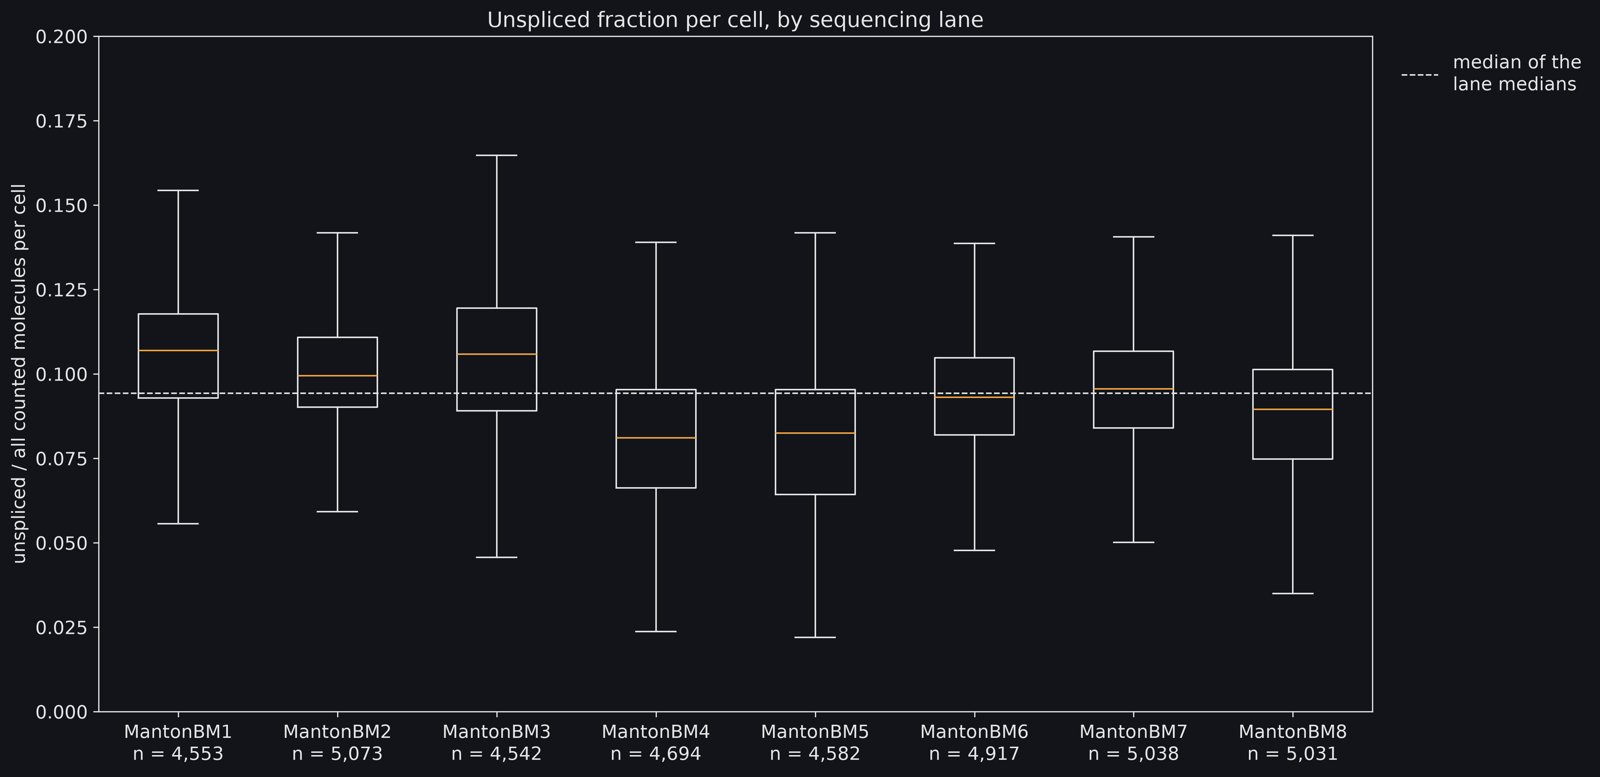

[Full-resolution figure](../figures/trajectory/velocity_counts/velocity_counts_lane_unspliced.png)

In [34]:
show("trajectory/velocity_counts/velocity_counts_lane_unspliced.png")

- **Fixed axis 0-0.20; dashed line = median of the lane medians (0.094).**
- **MantonBM1 and MantonBM3 have the highest medians, MantonBM4 and MantonBM5
  the lowest**, the same order as the within-cell-type offsets.
- **The spread inside each lane is larger than the gap between lanes** - which
  is why the lane effect only shows when the same cell type is compared.

## 11. RNA velocity - whole sample (all 38,430 cells)

In [35]:
def gene_fit(run: str) -> pd.Series:
    """Dynamical-model fit summary: genes fitted, median and banded likelihood."""
    fits = table(f"trajectory/{run}/{run}_genes.csv", index_col=0)["fit_likelihood"].dropna()
    return pd.Series({
        "genes with a fit": len(fits), "median likelihood": round(fits.median(), 3),
        "above 0.1": int((fits > 0.1).sum()), "above 0.3": int((fits > 0.3).sum()),
        "below 0.001": int((fits < 0.001).sum()),
    })


def lineage_genes(run: str) -> pd.DataFrame:
    """Fit likelihood and steady-state fit of selected lineage-defining genes."""
    genes = table(f"trajectory/{run}/{run}_genes.csv", index_col="gene_symbol")
    selected = ["KLF1", "GYPA", "ALAS2", "HBA1", "HBB", "CA1", "MPO", "ELANE", "LYZ",
                "S100A8", "CD79A", "DNTT", "VPREB1"]
    return genes.loc[selected, ["fit_likelihood", "stochastic_velocity_r2"]]


display(gene_fit("velocity_scvelo").to_frame("whole sample").T)
display(lineage_genes("velocity_scvelo"))
genes = table("trajectory/velocity_scvelo/velocity_scvelo_genes.csv")
genes.nlargest(10, "fit_likelihood")[["gene_symbol", "fit_likelihood"]]

,genes with a fit,median likelihood,above 0.1,above 0.3,below 0.001
whole sample,453.0,0.052,185.0,9.0,188.0


,fit_likelihood,stochastic_velocity_r2
gene_symbol,,
KLF1,NaN,3.380e-01
GYPA,NaN,5.467e-01
ALAS2,NaN,4.733e-01
HBA1,NaN,5.049e-01
HBB,NaN,7.705e-01
CA1,2.417e-01,8.844e-01
MPO,NaN,5.950e-01
ELANE,NaN,6.511e-01
LYZ,NaN,4.337e-02


,gene_symbol,fit_likelihood
1130,GNLY,0.648
961,NKG7,0.590
1538,CD74,0.578
585,IGHM,0.535
1624,HLA-DQB1,0.376
467,KLRD1,0.356
1026,CD37,0.352
1307,TKT,0.345
1910,FCN1,0.341
605,FOS,0.293


- **Two models**: *stochastic* (steady-state ratio of unspliced to spliced per
  gene) and *dynamical* (fits each gene's full on/off kinetics; gives a fit
  likelihood and a shared "latent time").
- **Setup:** 2,000 variable genes chosen per lane, neighbours on the annotated
  PCA, the dynamical model fitted on the 454 stochastic velocity genes.
- **Fit quality is low**: median likelihood 0.052; only 185 genes above 0.1 and
  9 above 0.3.
- **The best-fitted genes are lymphoid and immune** (GNLY, NKG7, CD74, IGHM,
  HLA-DQB1, KLRD1) - matching where the unspliced signal is strongest.
- **The lineage programmes are not in the model**: KLF1, GYPA, ALAS2, HBA1,
  HBB, MPO, ELANE, LYZ, S100A8, CD79A and DNTT were not selected as velocity
  genes (no fit), though several have a fair steady-state fit. CA1 is the only
  erythroid gene fitted. Every erythroid and myeloid direction below rests on
  other genes.

In [36]:
orderings = ["palantir", "stochastic_velocity_pseudotime", "dynamical_velocity_pseudotime",
             "latent_time", "stochastic_velocity_confidence", "dynamical_velocity_confidence"]
whole = table("trajectory/velocity_scvelo/velocity_scvelo_cells.csv", index_col=0)
whole.groupby("cell_type")[orderings].median().sort_values("palantir").round(3)

,palantir,stochastic_velocity_pseudotime,dynamical_velocity_pseudotime,latent_time,stochastic_velocity_confidence,dynamical_velocity_confidence
cell_type,,,,,,
HSPC,0.129,0.626,0.445,0.365,0.958,0.757
T proliferating,0.404,0.913,0.617,0.335,0.977,0.703
Granulocyte precursor,0.530,0.666,0.109,0.275,0.923,0.722
CD8 T memory,0.580,0.961,0.965,0.362,0.880,0.626
Dendritic cell,0.585,0.652,0.047,0.153,0.946,0.943
CD4 T naive,0.589,0.993,0.997,0.434,0.810,0.673
CD4 T memory,0.594,0.980,0.973,0.389,0.934,0.713
Platelet,0.595,0.544,0.507,0.450,0.914,0.650
T activated,0.599,0.980,0.992,0.395,0.647,0.604


- **Median per cell type; 0 = earliest.** The velocity orderings choose their
  own start.
- **None starts at HSPC** (0.626, 0.445, 0.365).
- **Each starts somewhere else**: the stochastic pseudotime in the erythroid
  island (Erythroid early 0.002, late 0.005; 1,481 cells below 0.01), the
  dynamical pseudotime in the myeloid labels (Dendritic cell 0.047, monocytes
  0.090-0.108), the latent time in Dendritic cell (0.153), ending in Erythroid
  early (0.808).
- **Both velocity pseudotimes put the whole lymphoid block last**
  (0.91-0.997), CD4 T naive latest of all - "everything ends in naive T cells",
  which is not development.
- **Confidence is high where direction is wrong**: Erythroid early 0.992
  (stochastic) while its direction is reversed (below). Confidence measures
  agreement between neighbouring cells, not correctness.

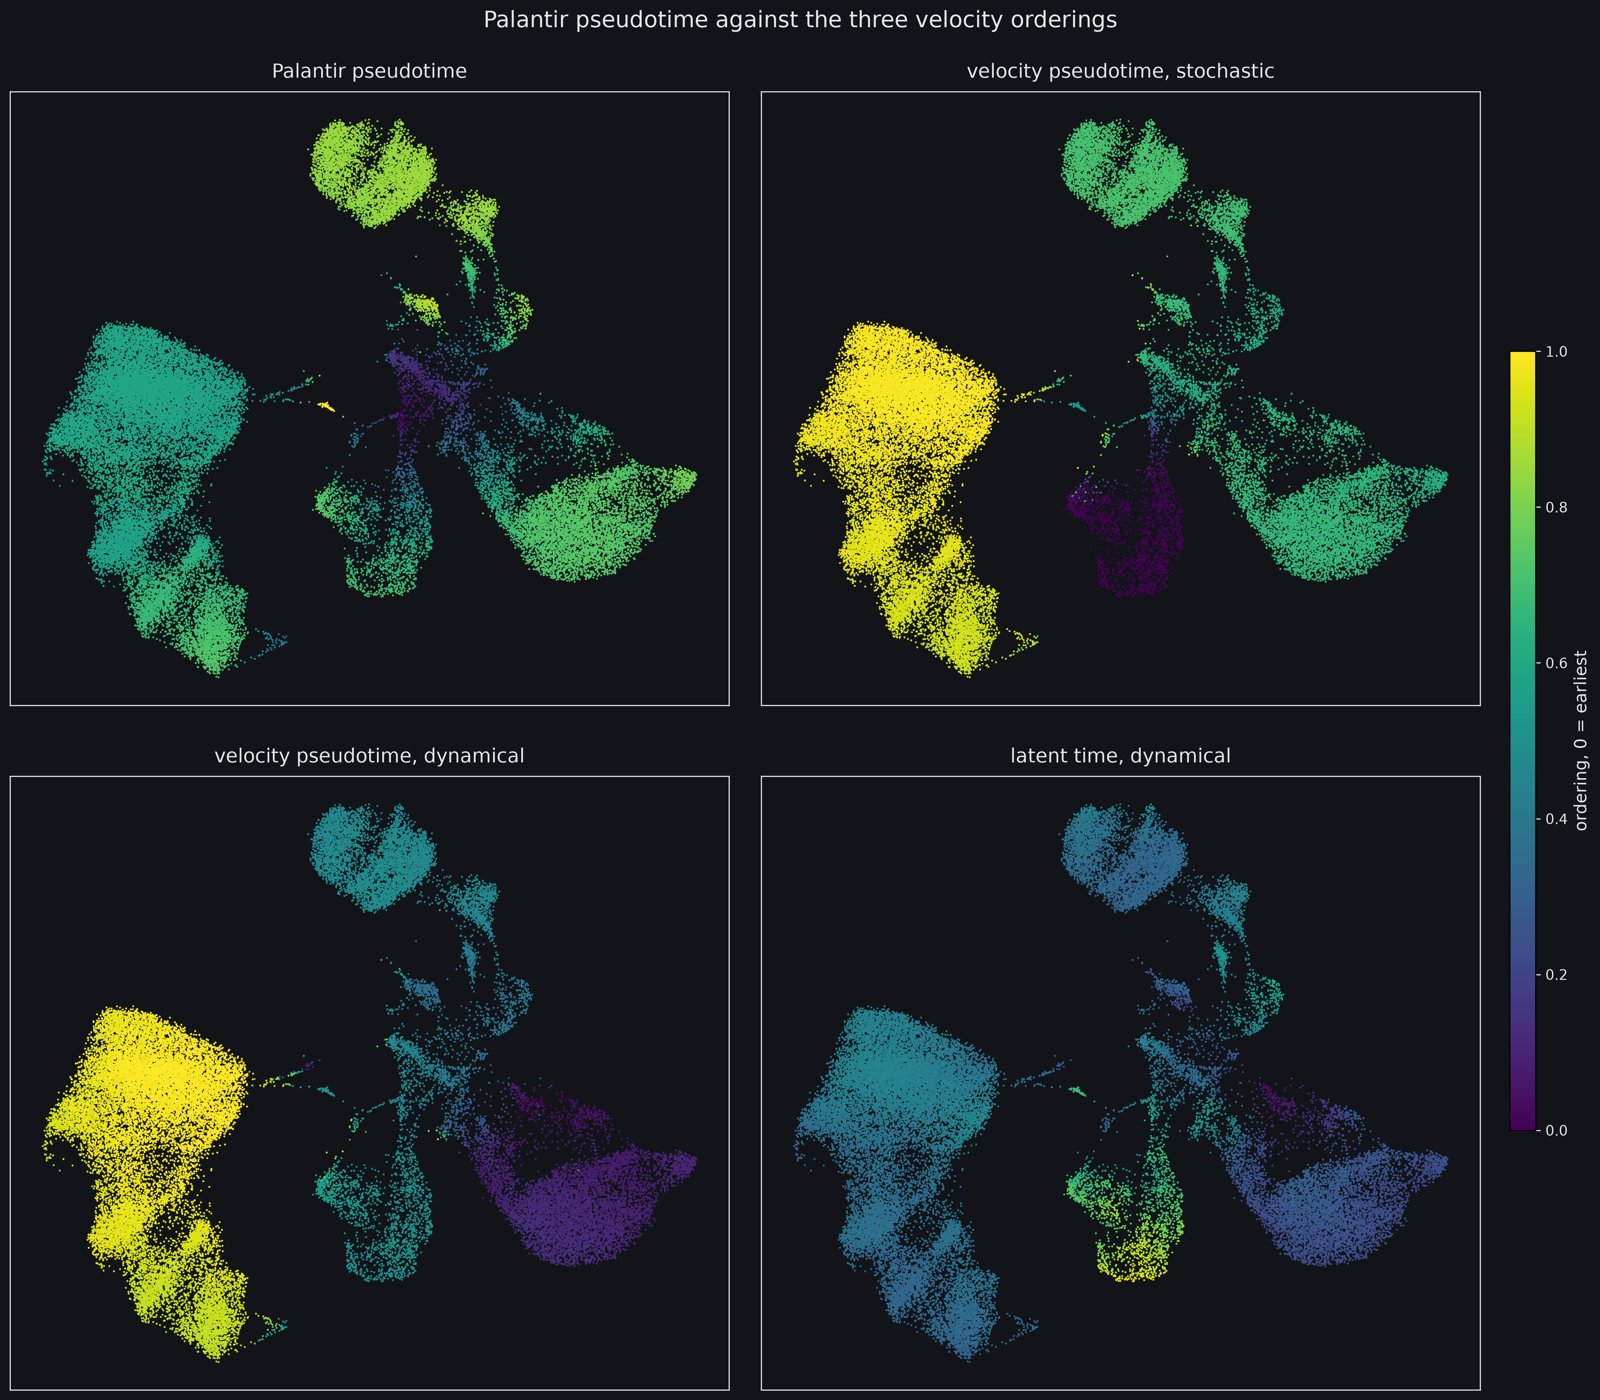

[Full-resolution figure](../figures/trajectory/velocity_scvelo/velocity_scvelo_orderings_umap.png)

In [37]:
show("trajectory/velocity_scvelo/velocity_scvelo_orderings_umap.png")

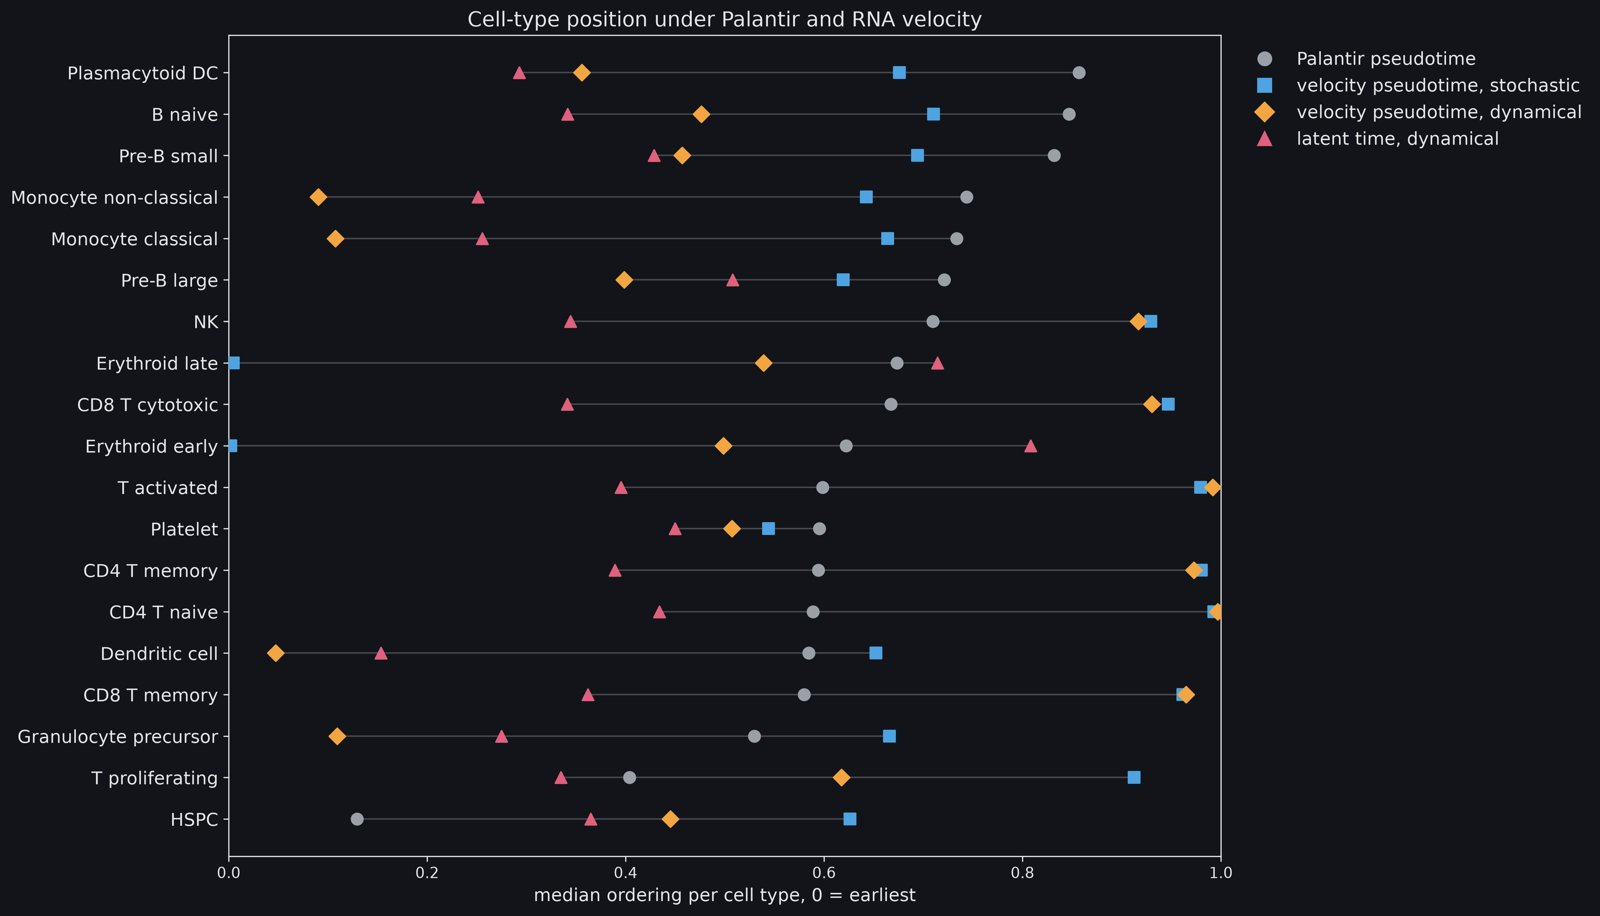

[Full-resolution figure](../figures/trajectory/velocity_scvelo/velocity_scvelo_celltype_orderings.png)

In [38]:
show("trajectory/velocity_scvelo/velocity_scvelo_celltype_orderings.png", width=750)

- **One fixed 0-1 colour scale in all four panels.**
- **Stochastic (top right):** the erythroid island is the darkest region and
  the whole T region bright yellow.
- **Dynamical (bottom left):** the monocyte region is darkest, the T region
  bright yellow.
- **Latent time (bottom right):** most of the map in a narrow 0.25-0.45 band,
  only the erythroid island bright - 185 usable genes cannot order 38,000
  cells.
- **Per cell type (second figure):** the four markers rarely sit together; the
  erythroid rows show the widest split (stochastic at the far left, latent time
  at the far right).

In [39]:
agreement = table("trajectory/velocity_scvelo/velocity_scvelo_agreement.csv")
agreement.pivot(index="group", columns="ordering", values="spearman").round(3)

ordering,dynamical_velocity_pseudotime,latent_time,stochastic_velocity_pseudotime
group,,,
B,0.298,-0.254,0.538
all cells,-0.560,-0.438,-0.469
erythroid,0.802,0.784,-0.650
mature lymphoid,-0.450,-0.340,-0.469
myeloid,-0.419,-0.241,0.025


- **Spearman with Palantir. Globally negative (−0.44 to −0.56)**, driven by the
  21,545 lymphoid cells (late in velocity, mid-axis in Palantir) and by HSPC.
- **The "erythroid" +0.80 includes HSPC.** Inside Erythroid early and late only
  it is +0.60 (dynamical), +0.48 (latent) and −0.08 (stochastic) - from
  `velocity_scvelo_cells.csv`.
- **Myeloid does not agree on any ordering**, because the myeloid labels are
  the dynamical model's start.

In [40]:
edges = table("trajectory/velocity_scvelo/velocity_scvelo_paga_edges.csv")
display(edges.pivot_table(index=["source", "target"], columns="model", values="confidence")
        .sort_values("dynamical", ascending=False).round(3))
check = table("trajectory/velocity_progenitor/velocity_progenitor_direction_check.csv")
check[check["run"] == "whole sample"].pivot(index=["source", "target"], columns="model",
                                             values="direction")

,model,dynamical,stochastic
source,target,,
CD8 T memory,CD4 T memory,1.210,0.449
NK,CD8 T cytotoxic,1.104,0.576
T activated,CD4 T naive,0.455,NaN
CD8 T memory,T activated,0.403,0.588
Erythroid late,Erythroid early,0.319,0.124
T proliferating,HSPC,0.267,NaN
NK,CD8 T memory,0.231,NaN
Pre-B small,B naive,0.201,0.148
T proliferating,Pre-B large,0.168,NaN


model                                        dynamical stochastic
source                target                                     
Erythroid early       Erythroid late          reversed   reversed
Granulocyte precursor Monocyte classical       correct    correct
HSPC                  Erythroid early         reversed     absent
                      Granulocyte precursor     absent     absent
                      Pre-B large               absent    correct
Monocyte classical    Monocyte non-classical   correct     absent
Pre-B large           Pre-B small              correct    correct
Pre-B small           B naive                  correct    correct

- **Velocity-directed PAGA**: arrows between cell types, read as source ->
  target. `confidence` is not a probability (two values exceed 1.0); rank it
  within one model only.
- **Direction check on eight textbook steps** (forward against reverse
  arrow):
  - **Correct**: Pre-B large -> Pre-B small -> B naive (both models), Granulocyte
    precursor -> Monocyte classical (both), Monocyte classical -> non-classical
    (dynamical), HSPC -> Pre-B large (stochastic).
  - **Reversed**: Erythroid late -> Erythroid early in both models, and on into
    HSPC in the dynamical model.
  - **Absent**: HSPC -> Granulocyte precursor in both.
  - **No step that is present is correct in one model and reversed in the
    other.**
- **The strongest arrows are inside the mature lymphoid block and all run
  backwards**: memory -> naive, NK and CD8 -> CD4 (dynamical CD8 T memory ->
  CD4 T memory 1.21, NK -> CD8 T cytotoxic 1.10). CD8 -> CD4 does not happen at
  all.
- **It also reverses the CellRank arrow field** (section 8). Two methods give
  coherent, opposite directions in the same island - strong evidence that the
  island has no direction to find.
- **Arrows that cannot be biology**: Erythroid late, Platelet and Monocyte
  non-classical -> CD4 T naive (stochastic); T proliferating (47 cells) -> HSPC
  0.267 and -> Pre-B large 0.168 (dynamical) - dividing cells resemble dividing
  progenitors.

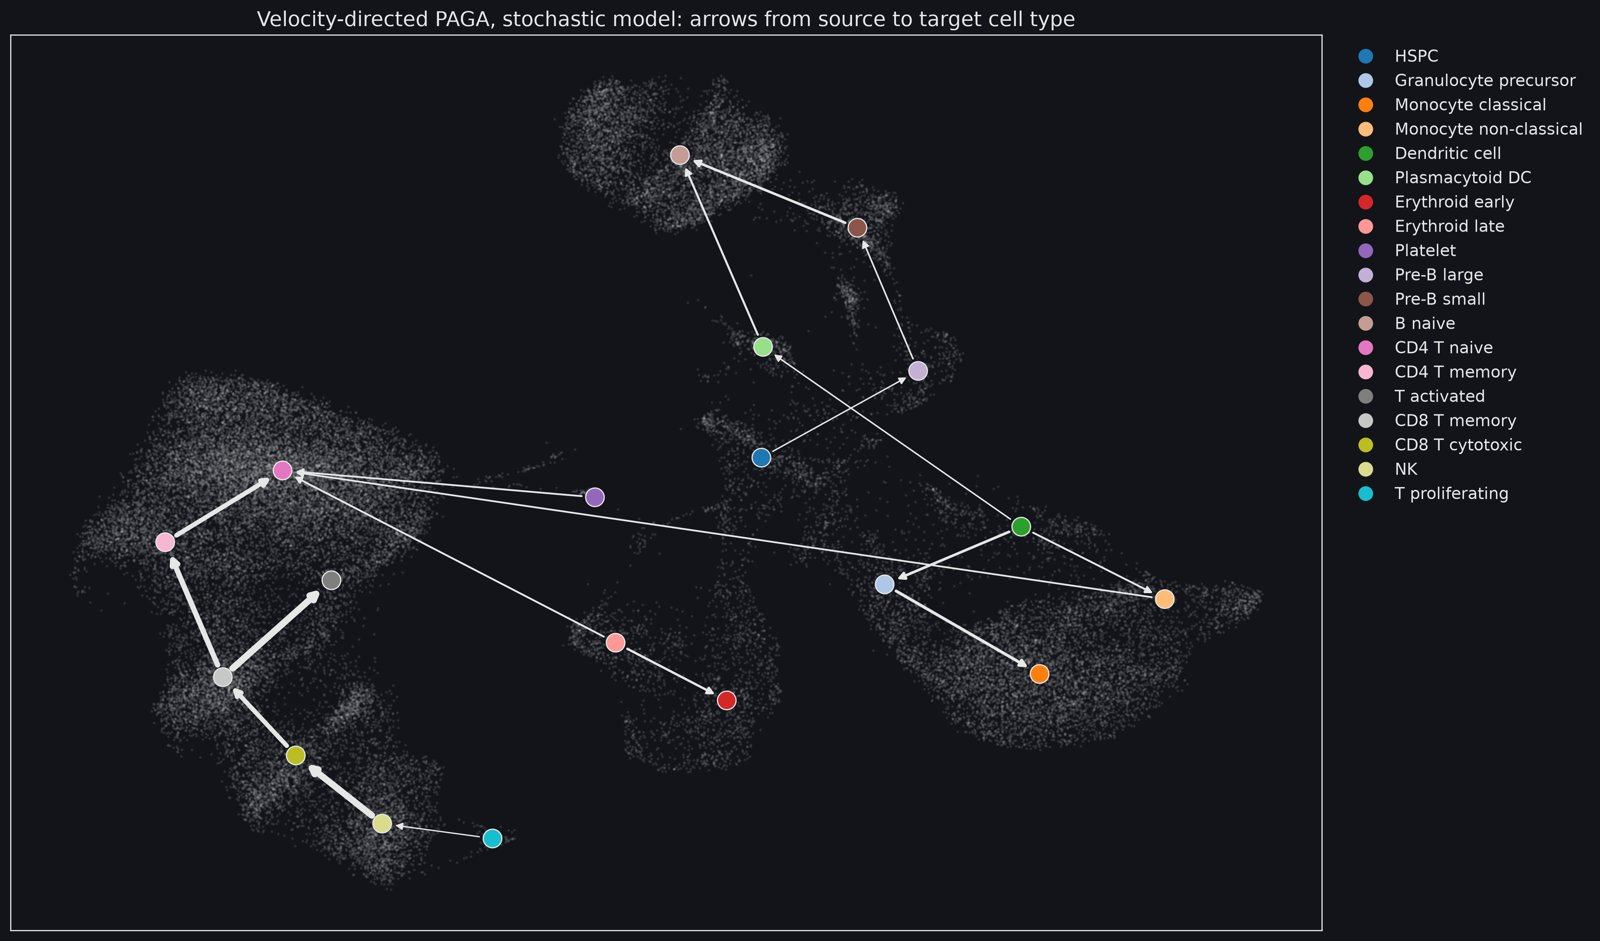

[Full-resolution figure](../figures/trajectory/velocity_scvelo/velocity_scvelo_paga_stochastic.png)

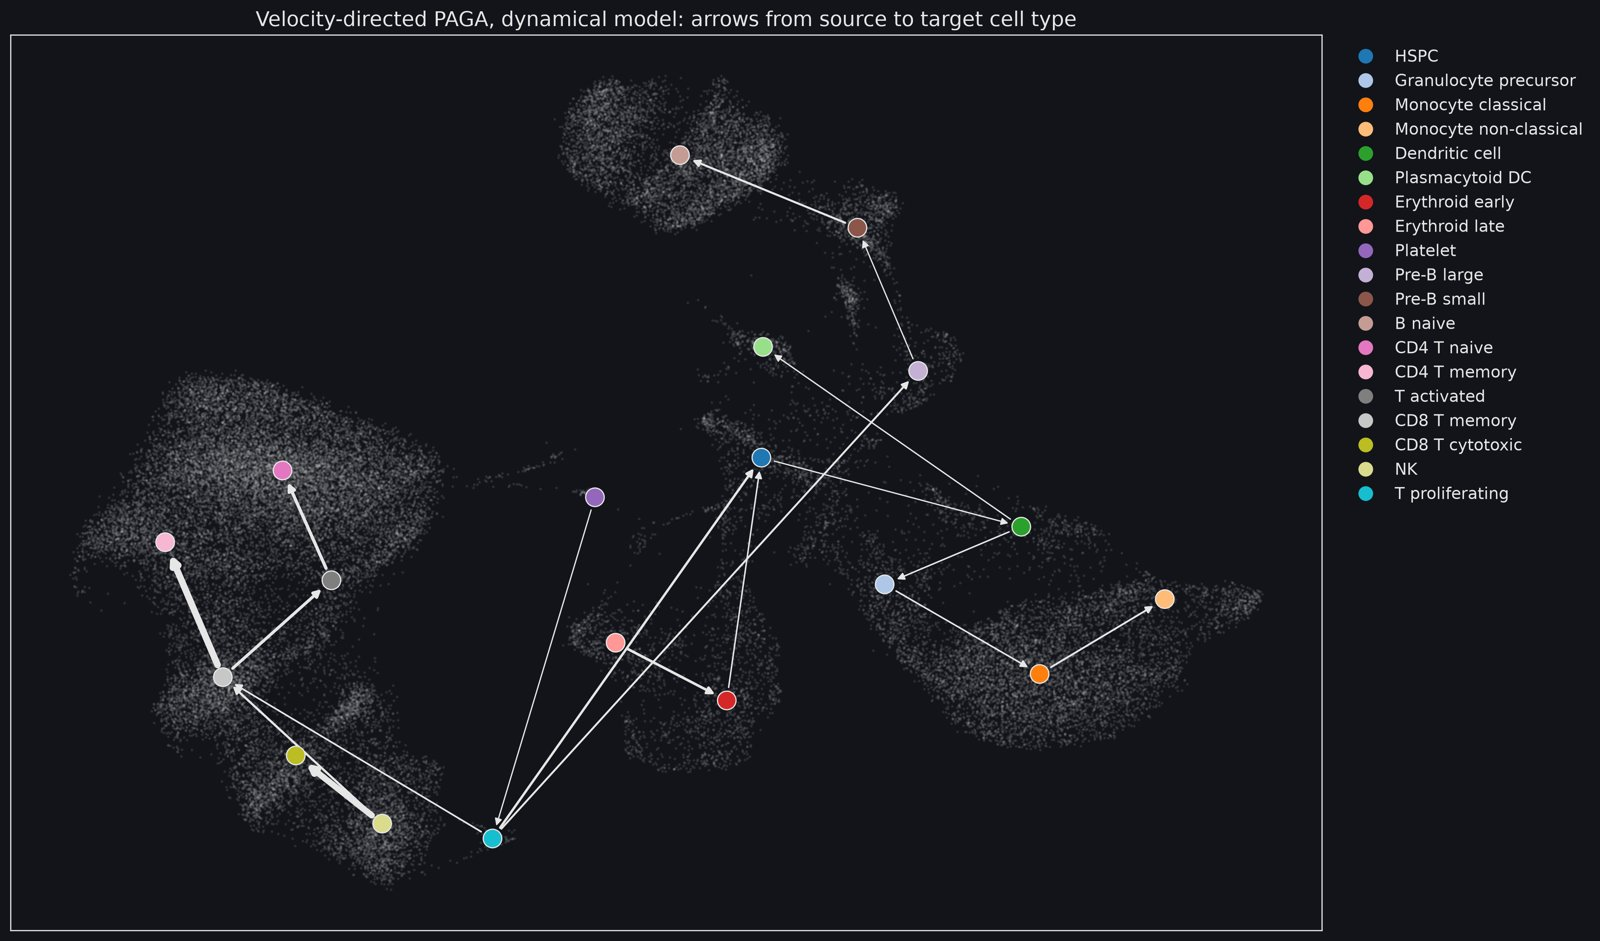

[Full-resolution figure](../figures/trajectory/velocity_scvelo/velocity_scvelo_paga_dynamical.png)

In [41]:
for model in ("stochastic", "dynamical"):
    show(f"trajectory/velocity_scvelo/velocity_scvelo_paga_{model}.png", width=800)

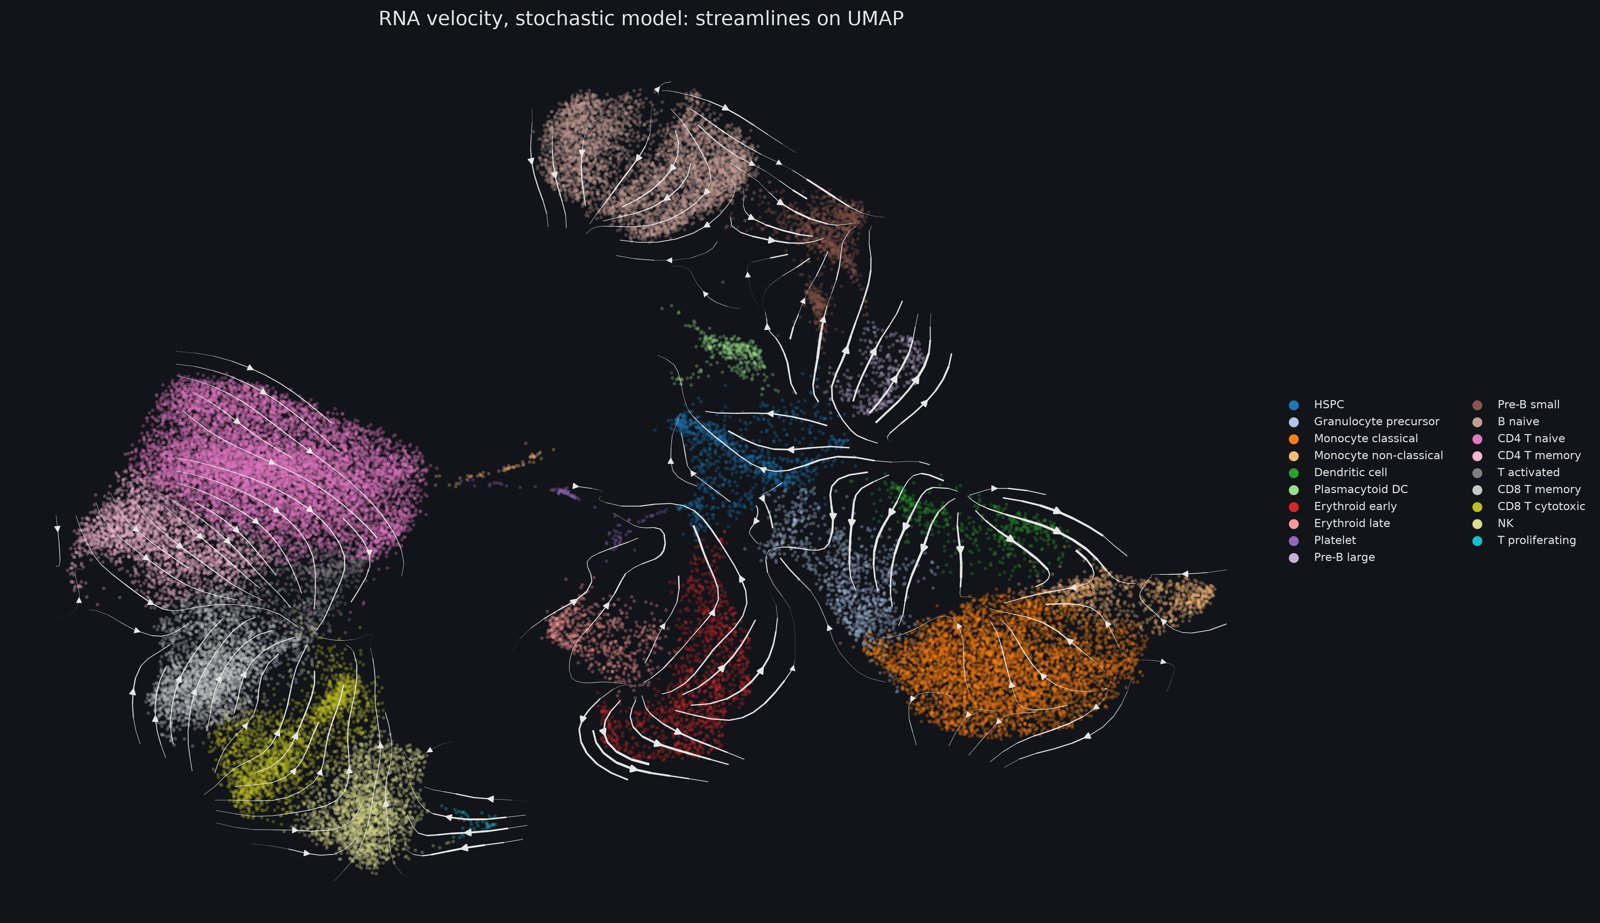

[Full-resolution figure](../figures/trajectory/velocity_scvelo/velocity_scvelo_stream_stochastic.png)

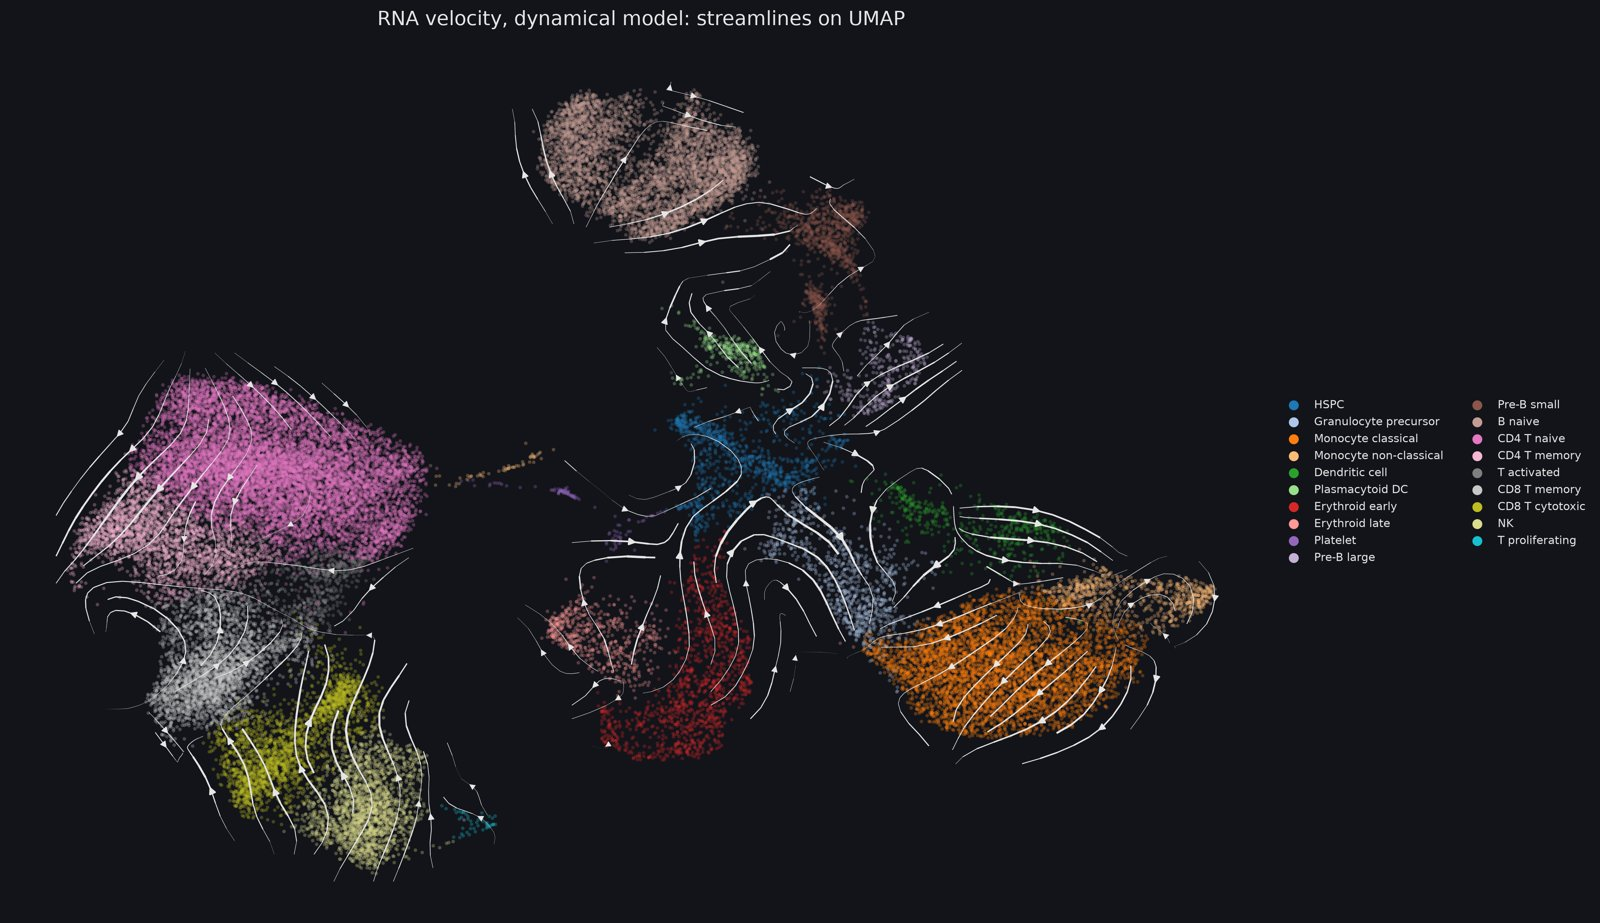

[Full-resolution figure](../figures/trajectory/velocity_scvelo/velocity_scvelo_stream_dynamical.png)

In [42]:
for model in ("stochastic", "dynamical"):
    show(f"trajectory/velocity_scvelo/velocity_scvelo_stream_{model}.png")

- **PAGA figures:** arrow width follows confidence. The thick arrows sit in
  the T block (left); the stochastic figure shows the long arrows from
  Erythroid late, Platelet and Monocyte non-classical into CD4 T naive; the
  dynamical figure shows T proliferating (bottom) as a hub sending arrows across
  the map into HSPC and Pre-B large.
- **Streamlines** (the colours here follow scVelo's own palette; read the
  legend): dense, parallel streams across the whole T block - the most
  confident-looking part of both figures and the least meaningful. Clear
  correct flows: Pre-B large up into Pre-B small, and through the monocyte
  region toward the non-classical tip (dynamical). In the dynamical panel the
  streams in Erythroid early point up out of the island toward HSPC - the
  reversed erythroid series, drawn.
- **Stream density follows the strength of the unspliced signal**, not the
  importance of the biology.

In [43]:
def lane_effects(run: str) -> pd.DataFrame:
    """Lane groups deviating by at least 0.1 from the cell-type median, per measure."""
    lanes = table(f"trajectory/{run}/{run}_lane_check.csv")
    rows = []
    for column in [name for name in lanes.columns if name.endswith("_deviation")]:
        large = lanes[lanes[column].abs() >= 0.1]
        rows.append({
            "measure": column.removesuffix("_deviation"),
            "groups tested": len(lanes),
            "groups ≥ 0.1": len(large),
            "which": "; ".join(f"{row.cell_type} {row.lane} {getattr(row, column):+.3f}"
                               for row in large.itertuples()),
        })
    return pd.DataFrame(rows).set_index("measure")


lane_effects("velocity_scvelo")

,groups tested,groups ≥ 0.1,which
measure,,,
stochastic_velocity_pseudotime,106,0,
stochastic_velocity_confidence,106,5,B naive MantonBM3 +0.145; CD4 T naive MantonBM3 -0.144; CD8 T memory MantonB...
dynamical_velocity_pseudotime,106,0,
dynamical_velocity_confidence,106,5,CD4 T naive MantonBM1 +0.135; CD4 T naive MantonBM2 +0.133; CD4 T memory Man...
latent_time,106,1,Erythroid early MantonBM3 -0.126


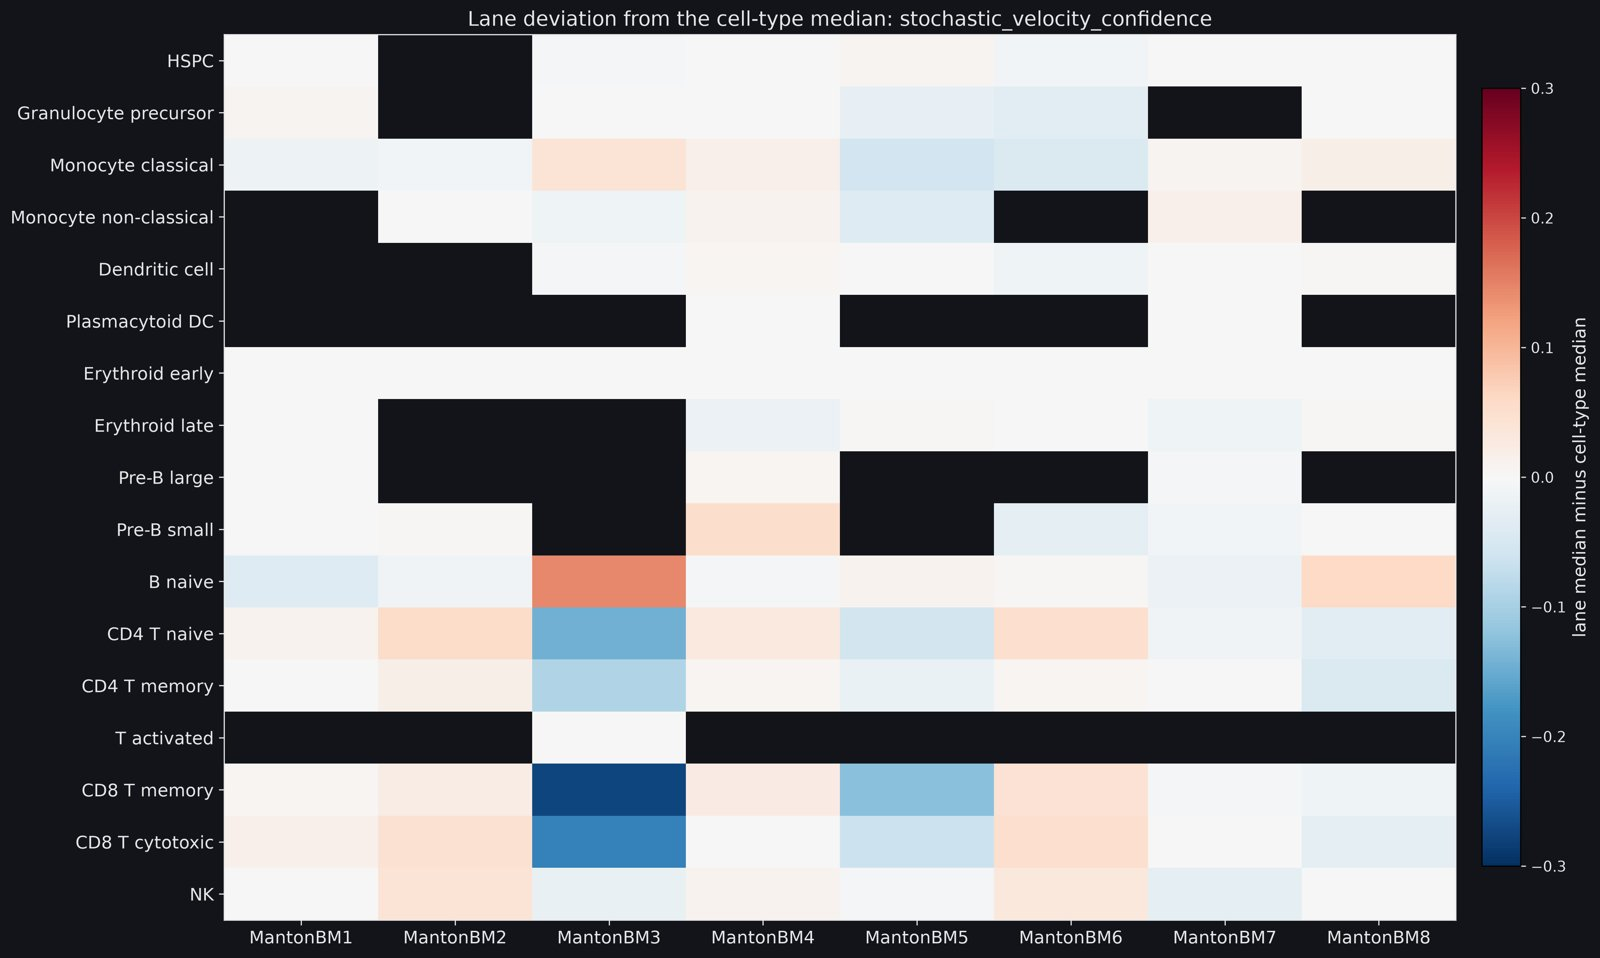

[Full-resolution figure](../figures/trajectory/velocity_scvelo/velocity_scvelo_lane_stochastic_velocity_confidence.png)

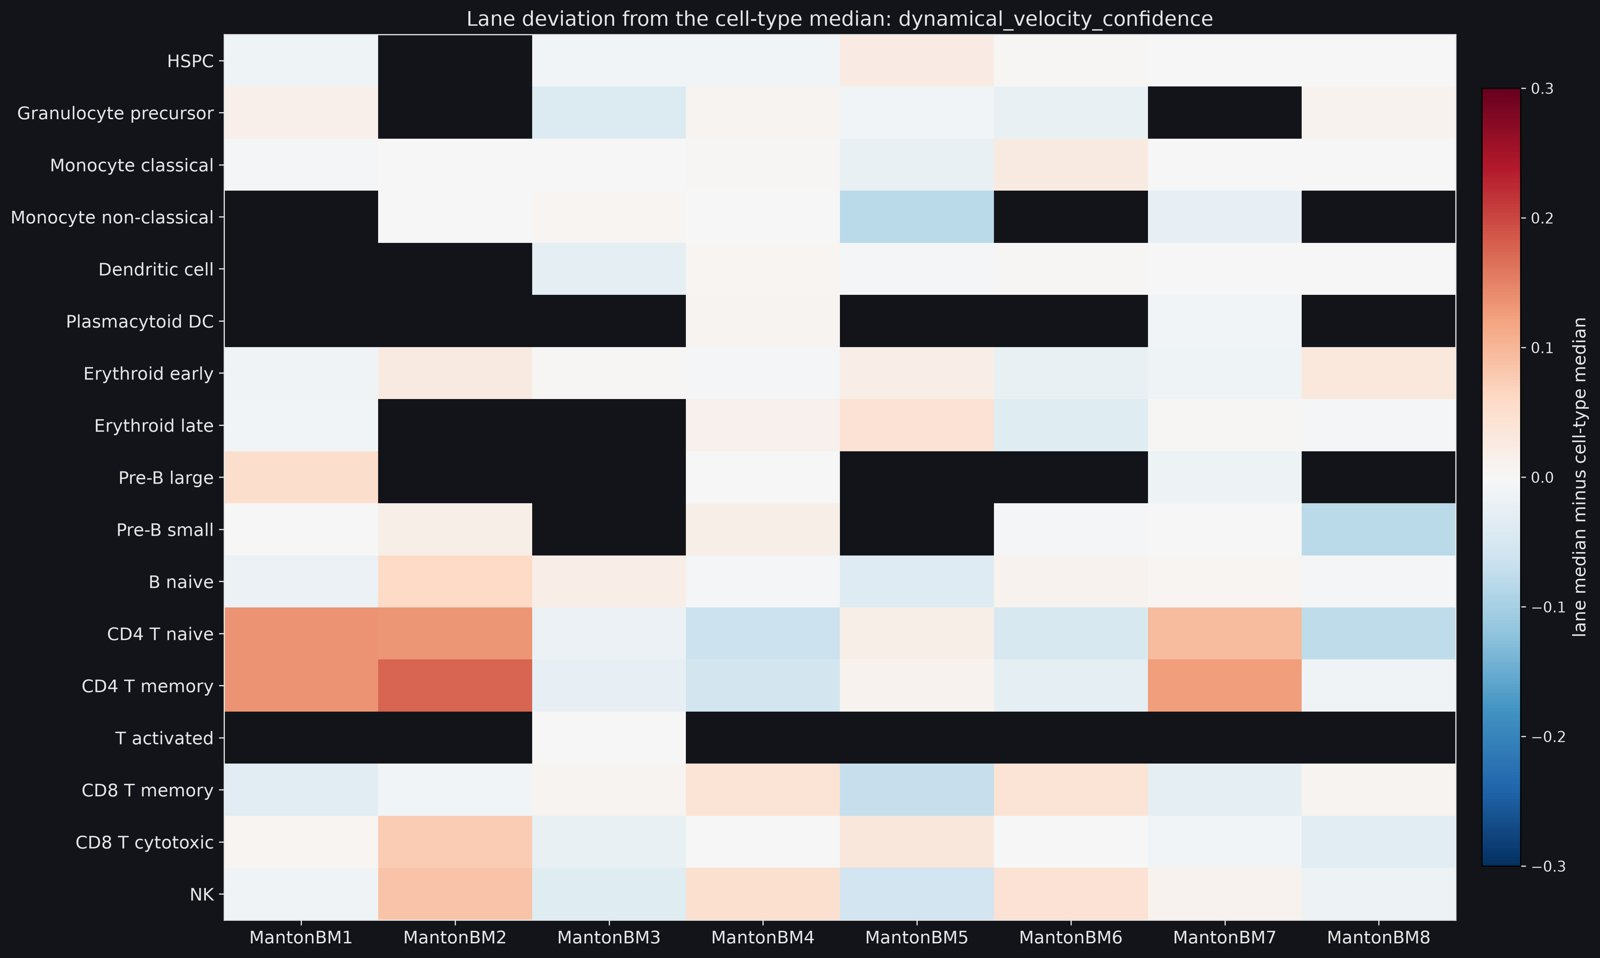

[Full-resolution figure](../figures/trajectory/velocity_scvelo/velocity_scvelo_lane_dynamical_velocity_confidence.png)

In [44]:
for measure in ("stochastic_velocity_confidence", "dynamical_velocity_confidence"):
    show(f"trajectory/velocity_scvelo/velocity_scvelo_lane_{measure}.png", width=750)

- **Each lane × cell type with at least 50 cells, compared with that cell
  type's median** (fixed ±0.3 scale; black = too few cells).
- **Positions do not depend on the lane**: no pseudotime group deviates by 0.1;
  latent time has one (Erythroid early in MantonBM3, −0.126, 57 cells). The
  orderings are not a lane artefact.
- **Confidence does depend on the lane**:
  - Stochastic: MantonBM3 is blue down the whole T block (CD8 T memory −0.276,
    CD8 T cytotoxic −0.202, CD4 T naive −0.144) while its B naive is red
    (+0.145). Any stochastic confidence for a T label is partly a MantonBM3
    property.
  - Dynamical: CD4 T labels are red in MantonBM1, MantonBM2 and MantonBM7
    (+0.125 to +0.174). This does not follow the unspliced offset; cause
    unknown.

## 12. RNA velocity - progenitor side only (16,885 cells)

- **The test:** did the lymphoid block (56% of cells, strongest signal) drown
  out the progenitor lineages? This run keeps the 12 progenitor-side labels,
  recomputes genes, PCA, neighbours and moments on them, fits **all 2,000
  variable genes**, adds **differential kinetics** (separate rates per cell
  type where a gene needs them), and roots the orderings at the Palantir zero
  cell (HSPC).
- **Rooting reintroduces the root**, so the rooted orderings are only a
  comparison with Palantir; direction evidence is the PAGA arrows and the
  streamlines.

In [45]:
display(pd.concat({run: gene_fit(run) for run in ("velocity_scvelo", "velocity_progenitor")}, axis=1).T)
display(lineage_genes("velocity_progenitor"))
progenitor_genes = table("trajectory/velocity_progenitor/velocity_progenitor_genes.csv")
flagged = progenitor_genes["fit_diff_kinetics"].dropna()
print(f"genes flagged for differential kinetics: {len(flagged)} of {len(progenitor_genes)}")
flagged.str.split(",").explode().value_counts().rename("genes flagged").to_frame().T

,genes with a fit,median likelihood,above 0.1,above 0.3,below 0.001
velocity_scvelo,453.0,0.052,185.0,9.0,188.0
velocity_progenitor,1991.0,0.079,845.0,18.0,579.0


,fit_likelihood,stochastic_velocity_r2
gene_symbol,,
KLF1,4.345e-19,0.245
GYPA,3.095e-13,0.553
ALAS2,1.019e-16,0.470
HBA1,1.739e-18,0.579
HBB,2.103e-01,0.792
CA1,4.988e-01,0.914
MPO,2.057e-03,0.503
ELANE,2.578e-06,0.737
LYZ,7.084e-03,-0.154


genes flagged for differential kinetics: 1328 of 2000


fit_diff_kinetics,Monocyte classical,Pre-B small,B naive,Granulocyte precursor,Erythroid late,Platelet,Monocyte non-classical,Plasmacytoid DC,Pre-B large,HSPC,Erythroid early,Dendritic cell
genes flagged,571,259,202,151,137,132,110,60,22,21,15,14


- **Far more usable genes**: 845 above 0.1 (against 185), median likelihood
  0.079.
- **But the best fit is MALAT1 (0.693)**, a nucleus-retained RNA with a large
  unspliced share for reasons unrelated to development; housekeeping genes
  (RPS8, ACTB, FTH1, ALDOA) fill much of the top 18.
- **The lineage genes are now in the model - and fail it**: KLF1, GYPA, ALAS2,
  HBA1 at likelihoods of 10⁻¹³ to 10⁻¹⁹; ELANE, DNTT, CD79A near zero. CA1
  (0.499) and HBB (0.210) are the erythroid exceptions.
- **Differential kinetics flags 1,328 of 2,000 genes (66%)**, the largest
  groups most often (Monocyte classical 571). At that rate the flag no longer
  separates real multi-rate genes from poorly fitted ones.
- **HBA1 is flagged in Granulocyte precursor and Monocyte classical**, not in
  red cells - most likely ambient haemoglobin RNA detected as a kinetic regime.

In [46]:
progenitor = table("trajectory/velocity_progenitor/velocity_progenitor_cells.csv", index_col=0)
display(progenitor.groupby("cell_type")[orderings].median().sort_values("palantir").round(3))
table("trajectory/velocity_progenitor/velocity_progenitor_agreement.csv").pivot(
    index="group", columns="ordering", values="spearman").round(3)

,palantir,stochastic_velocity_pseudotime,dynamical_velocity_pseudotime,latent_time,stochastic_velocity_confidence,dynamical_velocity_confidence
cell_type,,,,,,
HSPC,0.129,0.115,0.089,0.243,0.999,0.866
Granulocyte precursor,0.530,0.251,0.232,0.430,0.954,0.875
Dendritic cell,0.585,0.227,0.195,0.376,0.993,0.965
Platelet,0.595,0.314,0.273,0.507,0.921,0.887
Erythroid early,0.622,0.273,0.322,0.444,0.999,0.870
Erythroid late,0.673,0.526,0.633,0.584,0.839,0.783
Pre-B large,0.721,0.257,0.233,0.453,0.998,0.936
Monocyte classical,0.734,0.239,0.215,0.449,0.985,0.937
Monocyte non-classical,0.744,0.244,0.210,0.483,0.980,0.934


ordering,dynamical_velocity_pseudotime,latent_time,stochastic_velocity_pseudotime
group,,,
B,0.066,0.059,0.373
all cells,-0.024,0.152,0.556
erythroid,0.909,0.900,0.902
myeloid,0.274,0.682,0.376


- **HSPC is first in every ordering** - forced by the root, so it only shows
  rooting worked.
- **Everything else is squeezed into a narrow band** (stochastic 0.17-0.31 for
  10 of 11 labels); only Erythroid late is clearly late.
- **The B and myeloid end points are placed early**: B naive 0.21-0.31 and
  Plasmacytoid DC 0.14-0.17 on the two pseudotimes, against 0.85 and 0.86 in
  Palantir.
- **Agreement with Palantir:** erythroid +0.90 (with HSPC) and +0.72 to +0.75
  without it; myeloid latent time +0.68 (+0.56 without HSPC) - the best
  root-independent agreement in either run; B without HSPC −0.42 (dynamical)
  and −0.40 (latent) - partly backwards.
- **Confidence rose everywhere** (median 0.990 stochastic, 0.905 dynamical) and
  is still highest where direction is wrong (Erythroid early and HSPC 0.999).

In [47]:
display(table("trajectory/velocity_progenitor/velocity_progenitor_paga_edges.csv")
        .pivot_table(index=["source", "target"], columns="model", values="confidence")
        .sort_values("stochastic", ascending=False).round(3))
pd.crosstab([check["run"], check["model"]], check["direction"])

,model,dynamical,stochastic
source,target,,
Erythroid late,Erythroid early,0.817,0.864
Granulocyte precursor,Monocyte classical,0.155,0.195
Monocyte classical,Monocyte non-classical,0.115,0.097
Platelet,HSPC,0.271,0.087
Pre-B small,B naive,NaN,0.080
Dendritic cell,Monocyte classical,NaN,0.069
Erythroid late,HSPC,0.057,0.057
Pre-B large,HSPC,0.057,0.055
Granulocyte precursor,HSPC,NaN,0.054


direction                absent  correct  reversed
run          model                                
progenitor   dynamical        3        3         2
             stochastic       1        4         3
whole sample dynamical        2        4         2
             stochastic       3        4         1

- **Removing the lymphoid block did not improve the direction check**
  (crosstab: correct / reversed / absent per run and model).
- **The erythroid reversal became the dominant arrow**: Erythroid late ->
  Erythroid early 0.864 (stochastic, 7 times the whole-sample value) and 0.817
  (dynamical).
- **HSPC becomes a sink**: arrows into HSPC from Platelet (0.087 / 0.271),
  Pre-B large (0.055 / 0.057), Erythroid late (0.057) and Granulocyte precursor
  (0.054); the only arrow out goes to Plasmacytoid DC (0.047, dynamical).
  Velocity points *into* the stem compartment - the reverse of
  haematopoiesis.
- **Platelet -> HSPC (0.271) is the second strongest dynamical arrow**, from 103
  cells with no transcription of their own.
- **Steps that hold in all four runs**: Granulocyte precursor -> Monocyte
  classical (0.09-0.20) and Pre-B large -> Pre-B small (0.02-0.05). Monocyte
  classical -> non-classical holds in three of four.
- **Why the rooted erythroid order is right while the arrows are reversed**: a
  rooted velocity pseudotime behaves like distance from the root on the
  velocity graph; Erythroid late is simply further from HSPC. Only arrows carry
  direction.

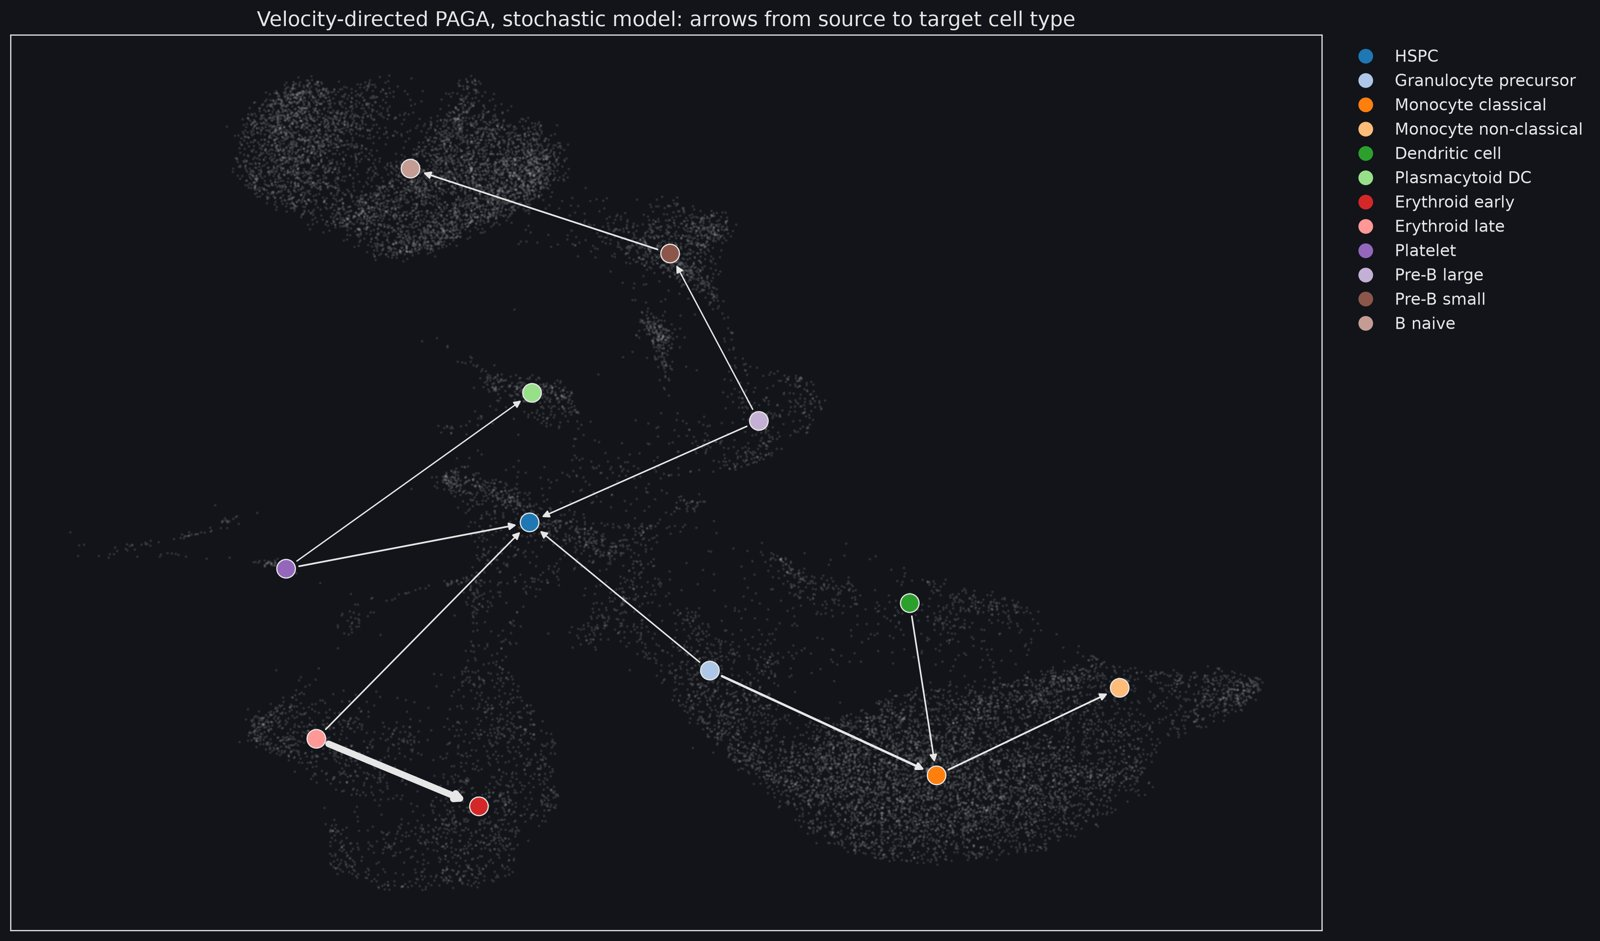

[Full-resolution figure](../figures/trajectory/velocity_progenitor/velocity_progenitor_paga_stochastic.png)

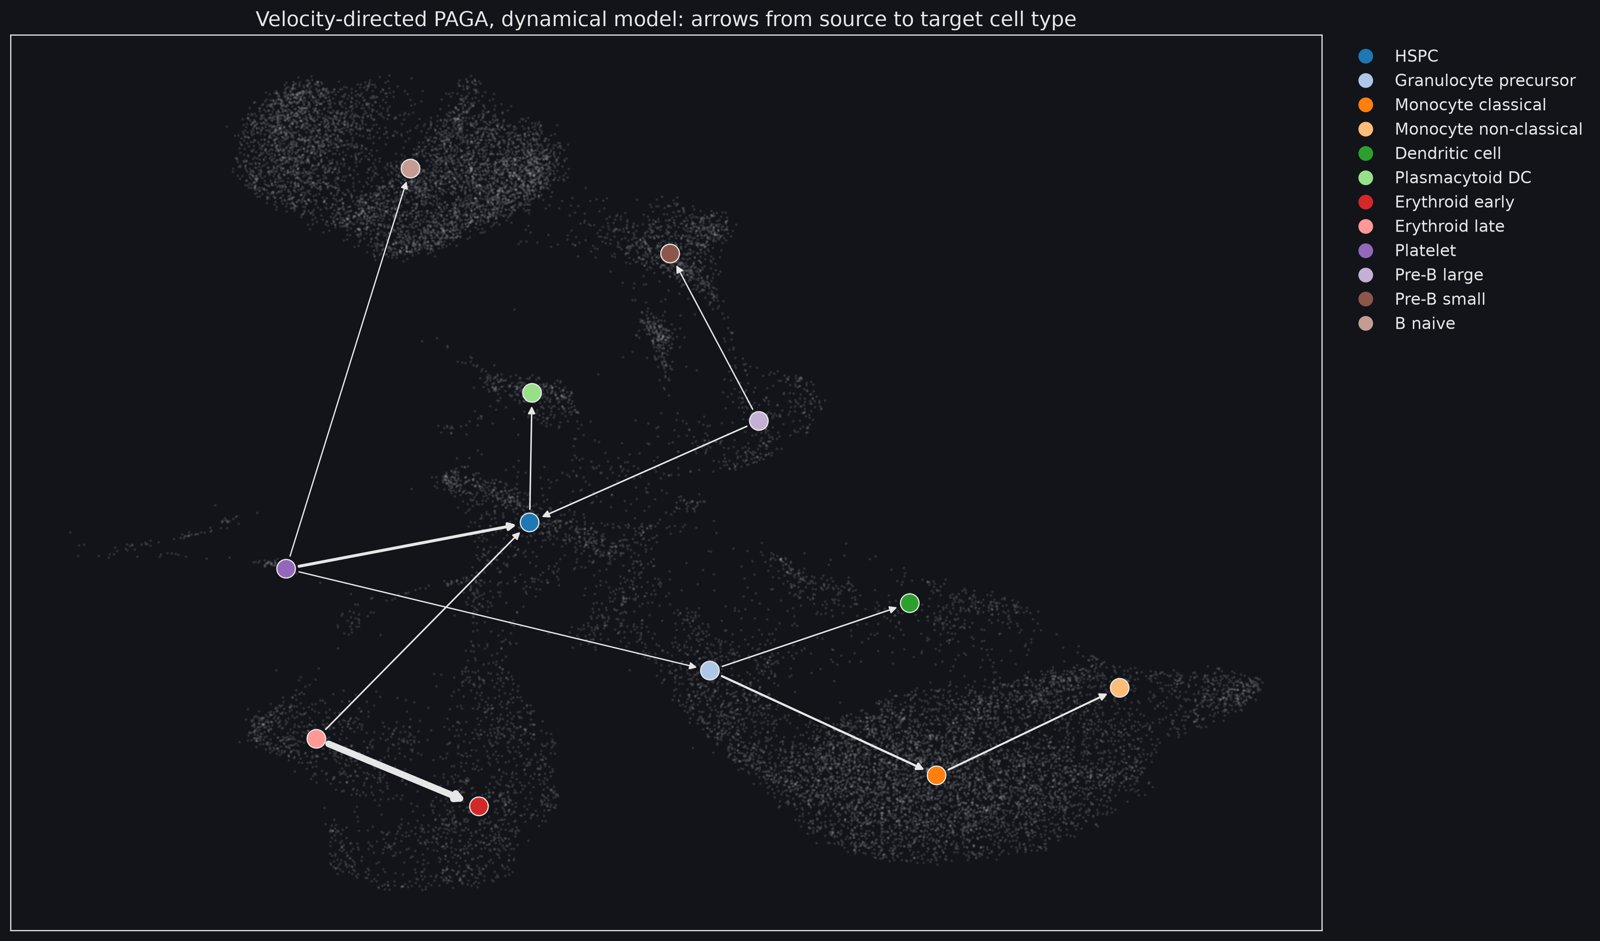

[Full-resolution figure](../figures/trajectory/velocity_progenitor/velocity_progenitor_paga_dynamical.png)

In [48]:
for model in ("stochastic", "dynamical"):
    show(f"trajectory/velocity_progenitor/velocity_progenitor_paga_{model}.png", width=800)

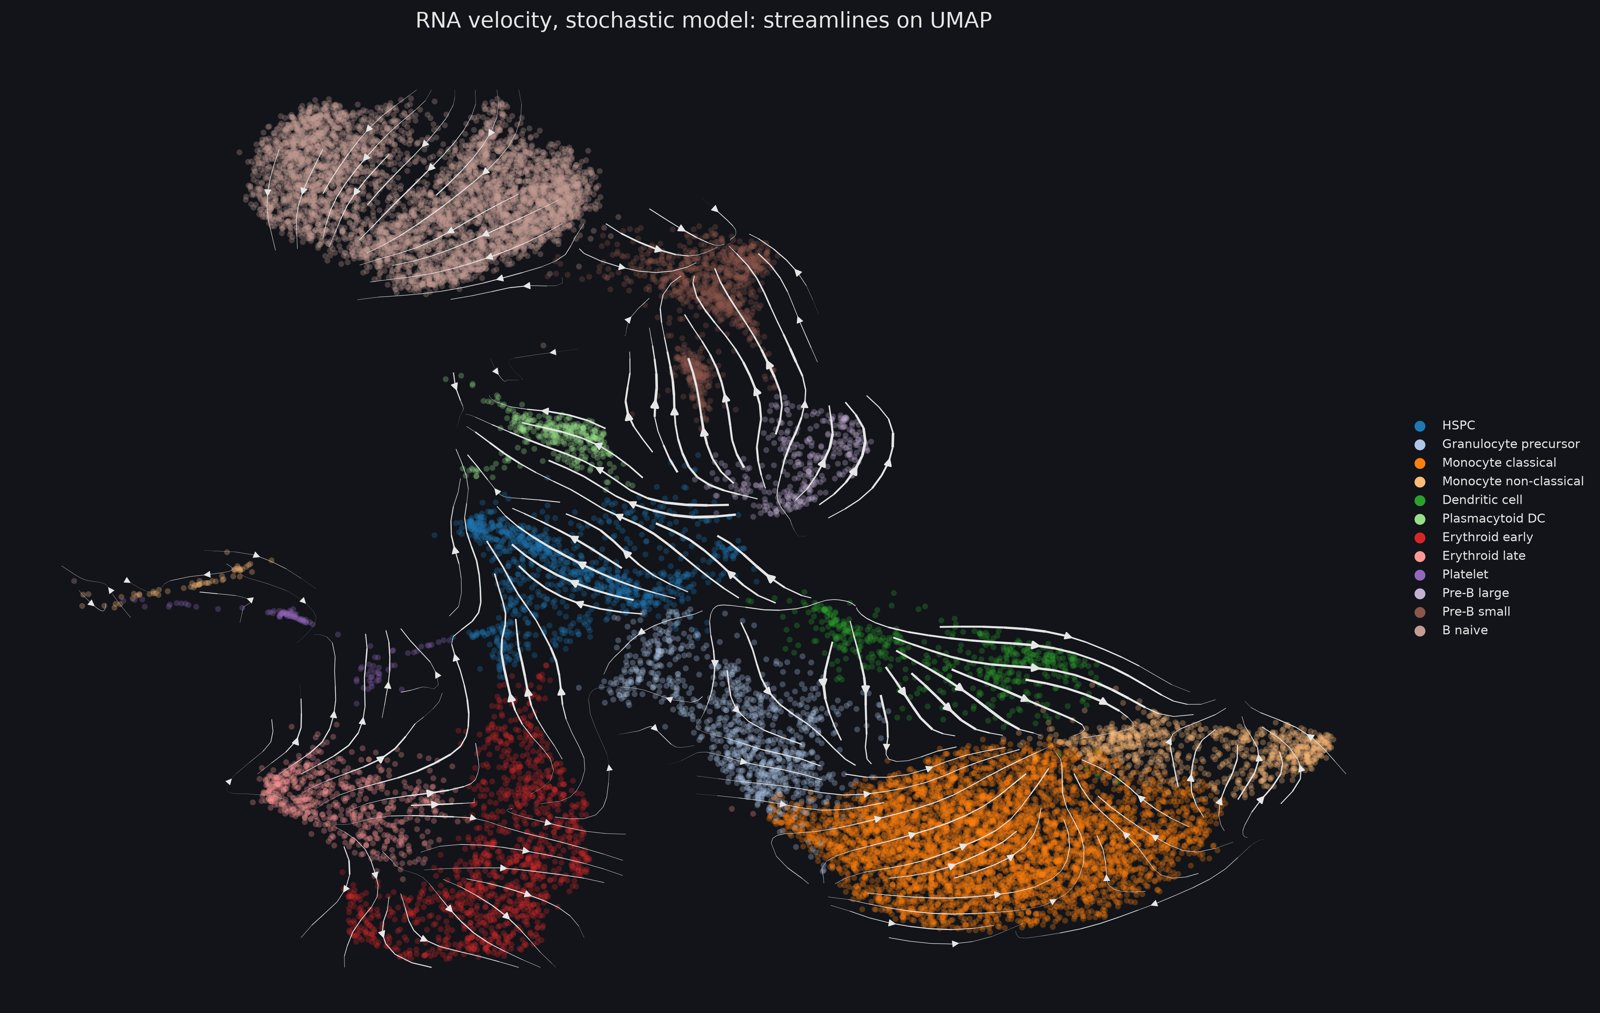

[Full-resolution figure](../figures/trajectory/velocity_progenitor/velocity_progenitor_stream_stochastic.png)

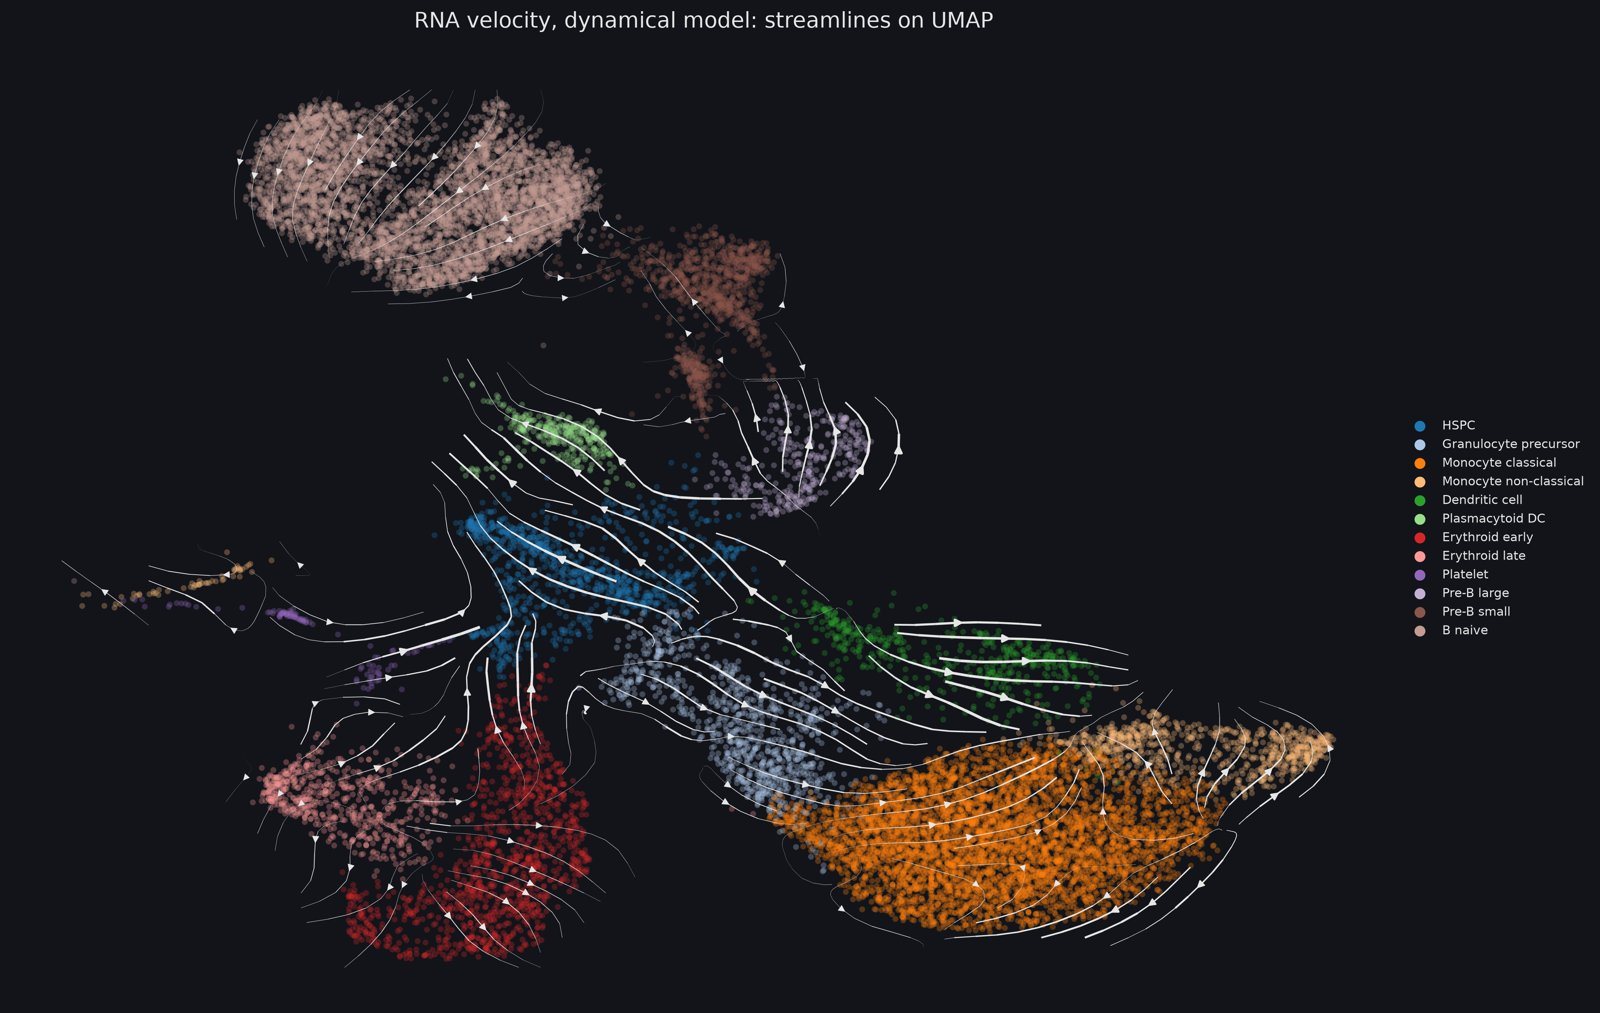

[Full-resolution figure](../figures/trajectory/velocity_progenitor/velocity_progenitor_stream_dynamical.png)

In [49]:
for model in ("stochastic", "dynamical"):
    show(f"trajectory/velocity_progenitor/velocity_progenitor_stream_{model}.png")

- **PAGA:** in both models the thickest arrow is Erythroid late -> Erythroid
  early, and HSPC (centre) is where arrows converge - from Platelet, Pre-B
  large, Erythroid late and (stochastic) Granulocyte precursor.
- **Streamlines (only the 12 progenitor labels; the plot is zoomed to them):**
  - Correct: Pre-B large streams curve up into Pre-B small; the monocyte region
    flows toward the non-classical tip.
  - Wrong: streams inside Erythroid early run up out of the island into the
    HSPC hub; the platelet streams on the left run into HSPC; inside B naive the
    streams have no common direction.

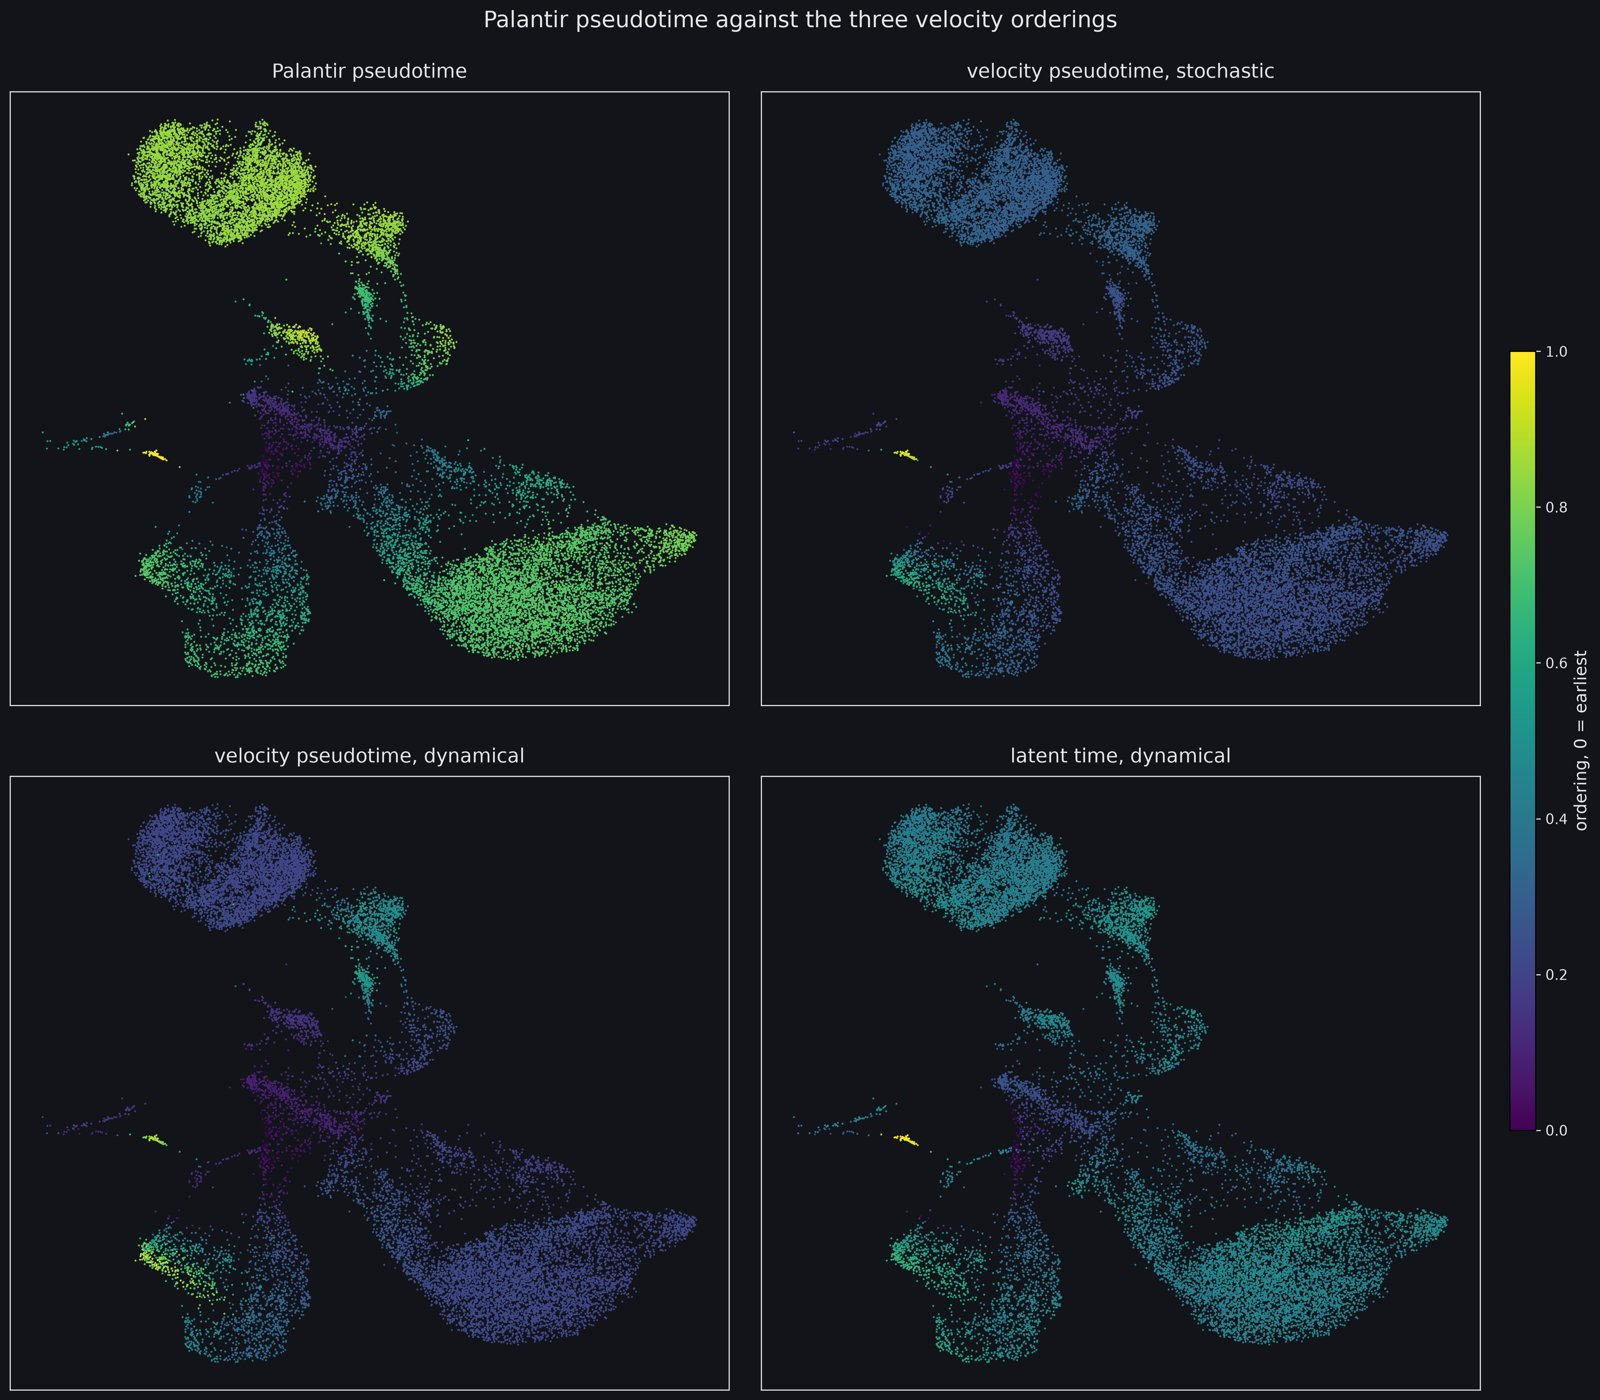

[Full-resolution figure](../figures/trajectory/velocity_progenitor/velocity_progenitor_orderings_umap.png)

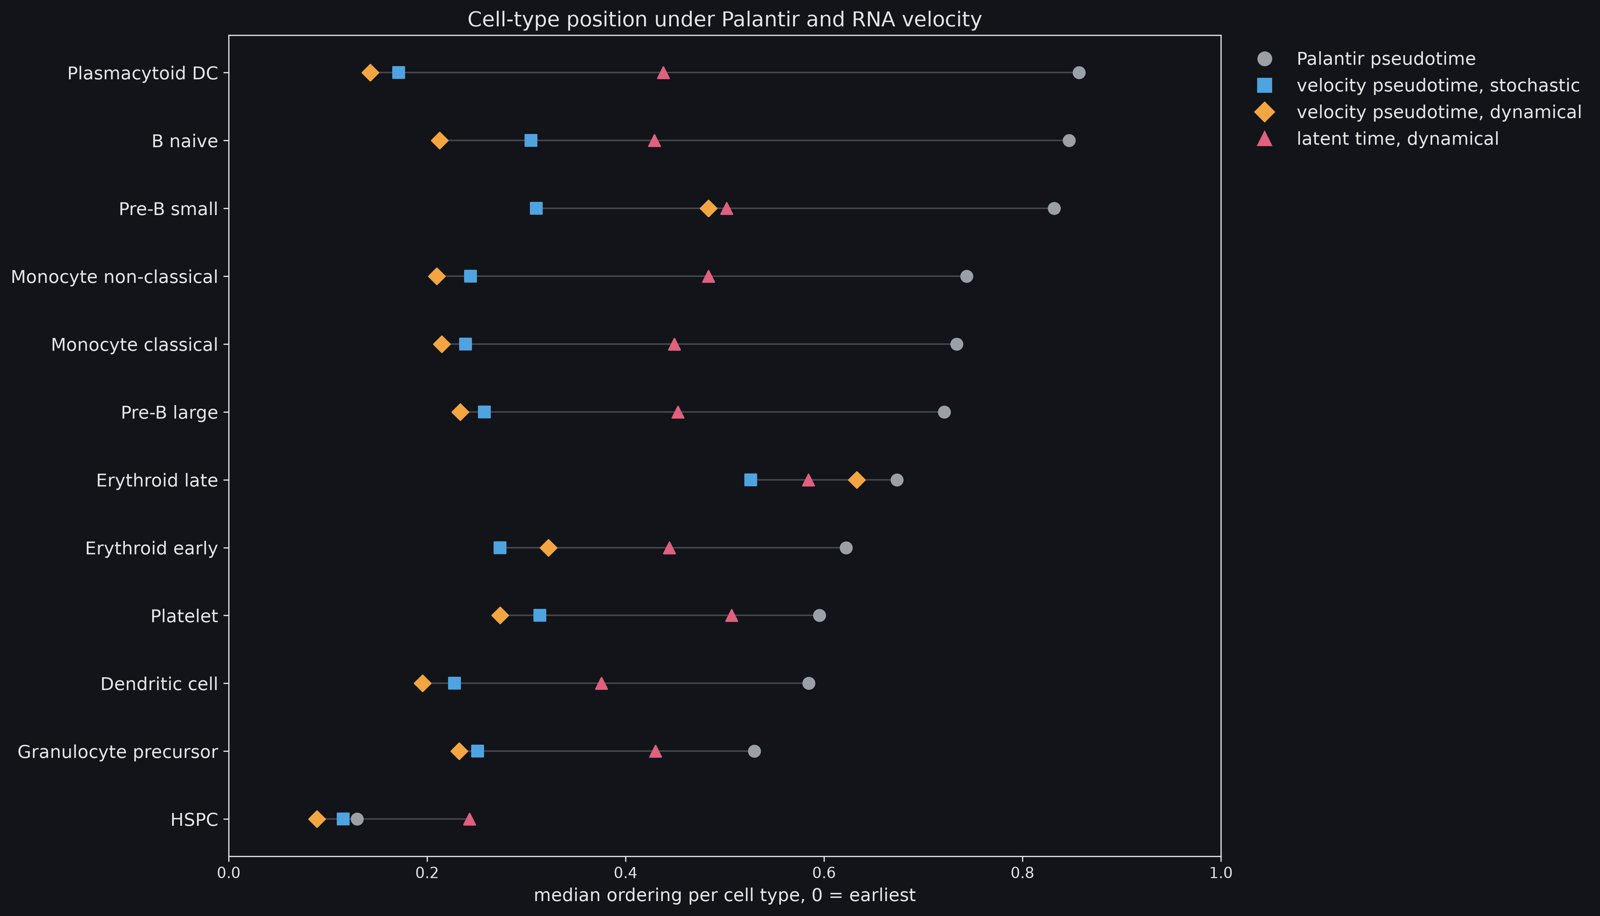

[Full-resolution figure](../figures/trajectory/velocity_progenitor/velocity_progenitor_celltype_orderings.png)

In [50]:
show("trajectory/velocity_progenitor/velocity_progenitor_orderings_umap.png")
show("trajectory/velocity_progenitor/velocity_progenitor_celltype_orderings.png", width=750)

- **Same fixed scale as the whole-sample figure.** The stochastic panel is
  almost all dark (0.1-0.3); the dynamical panel brightens only at the
  Erythroid late tip; latent time is a near-uniform teal.
- **Per cell type**: the grey Palantir circle sits far to the right of the
  three velocity markers for every B and myeloid label; only HSPC and Erythroid
  late bring the four together.
- **The bright speck left of centre** is again visible in all four panels
  (section 13).

,groups tested,groups ≥ 0.1,which
measure,,,
stochastic_velocity_pseudotime,65,0,
stochastic_velocity_confidence,65,2,Pre-B small MantonBM8 -0.146; B naive MantonBM3 -0.258
dynamical_velocity_pseudotime,65,1,Erythroid late MantonBM6 -0.131
dynamical_velocity_confidence,65,0,
latent_time,65,0,


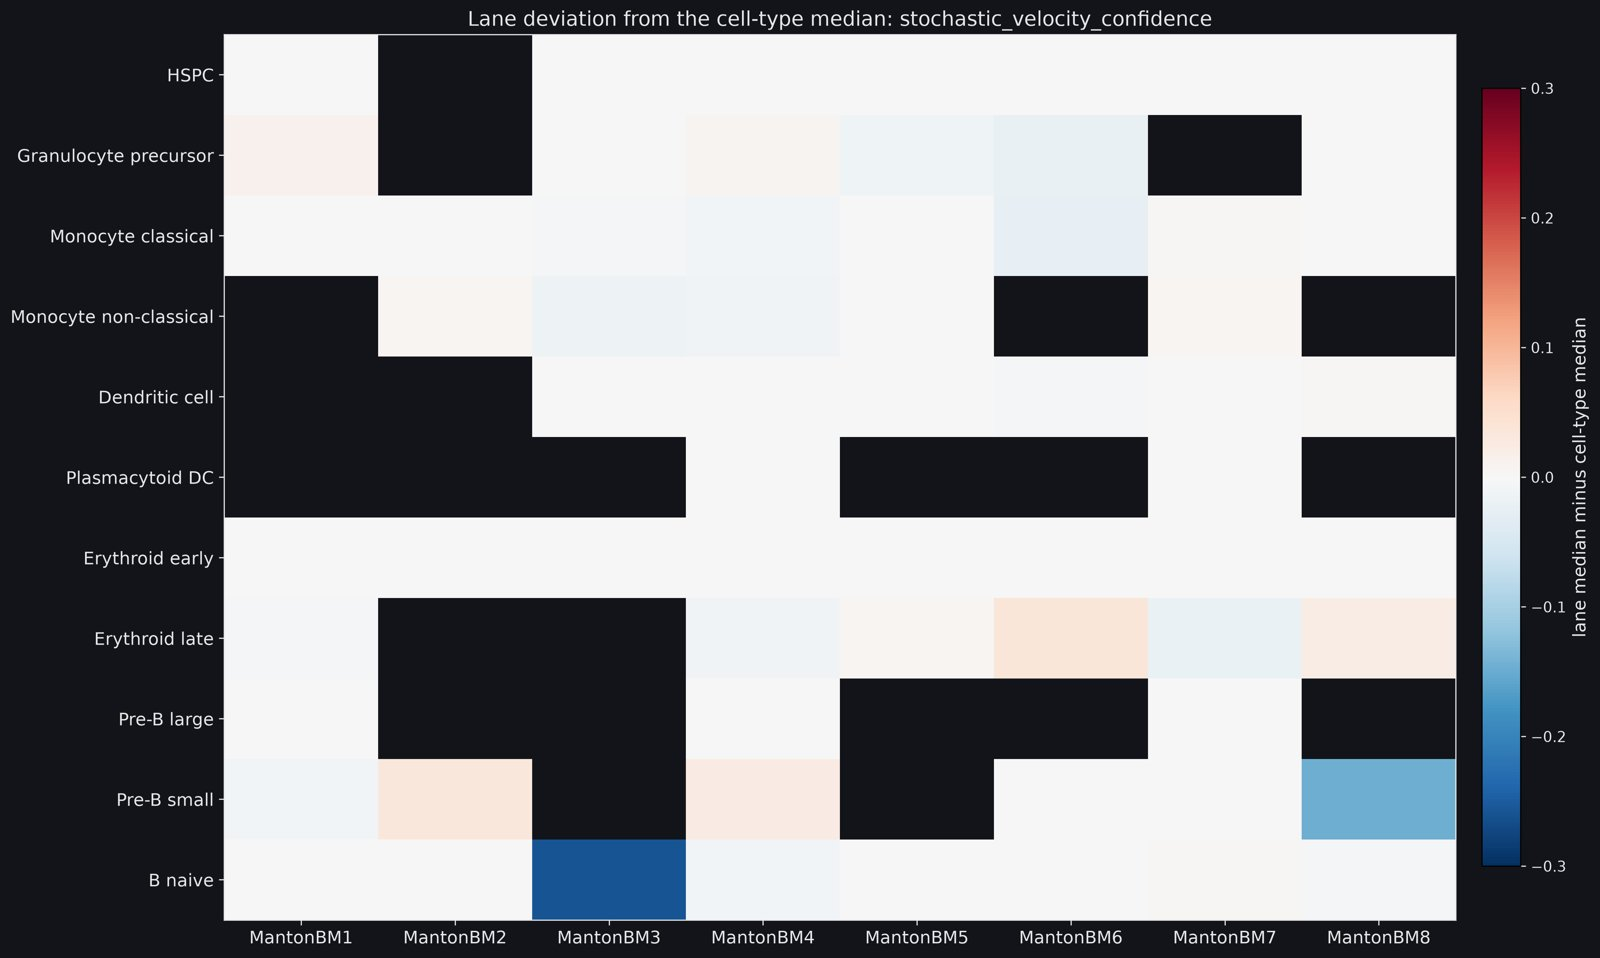

[Full-resolution figure](../figures/trajectory/velocity_progenitor/velocity_progenitor_lane_stochastic_velocity_confidence.png)

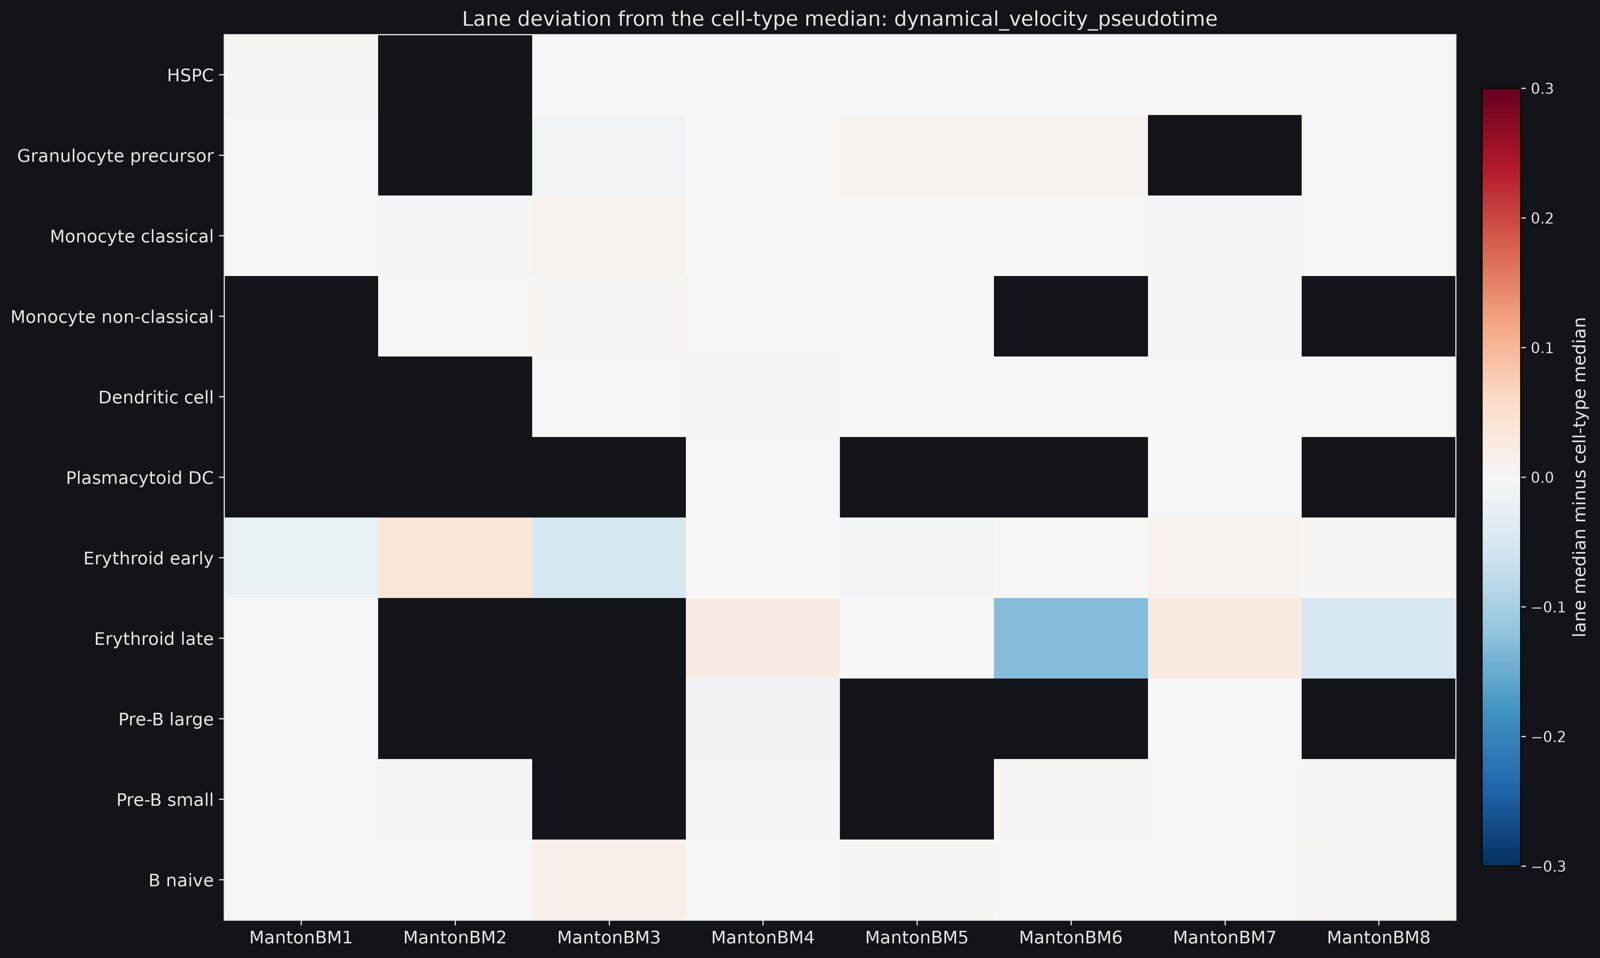

[Full-resolution figure](../figures/trajectory/velocity_progenitor/velocity_progenitor_lane_dynamical_velocity_pseudotime.png)

In [51]:
display(lane_effects("velocity_progenitor"))
for measure in ("stochastic_velocity_confidence", "dynamical_velocity_pseudotime"):
    show(f"trajectory/velocity_progenitor/velocity_progenitor_lane_{measure}.png", width=750)

- **Positions are again lane-independent**, with one exception: Erythroid late
  in MantonBM6 sits 0.131 earlier on the dynamical pseudotime (71 cells).
- **B naive in MantonBM3 is the strongest lane effect in either run: −0.258**
  (stochastic confidence). In the whole-sample run the same cells were
  **+0.145**. A lane effect that changes sign between two fits of the same
  cells is a property of how those cells sit in each neighbour graph, not a
  fixed property of the lane. MantonBM3 produces the confidence outliers in
  both runs.

## 13. The bright speck is a group of platelets

In [52]:
late = whole[whole["palantir"] >= 0.95]
display(late["cell_type"].value_counts().rename("cells with Palantir ≥ 0.95").to_frame().T)
display(late["lane"].value_counts().rename("platelets with Palantir ≥ 0.95").to_frame().T)
platelets = whole[whole["cell_type"] == "Platelet"]
display(pd.DataFrame({
    "Palantir ≥ 0.95": late[orderings[:4]].median(),
    "other platelets": platelets[platelets["palantir"] < 0.95][orderings[:4]].median(),
}).round(3))
pd.Series({
    column: progenitor.loc[progenitor[column] >= 0.9, "cell_type"].value_counts().to_dict()
    for column in ("stochastic_velocity_pseudotime", "latent_time")
}, name="progenitor run: cells ≥ 0.9").to_frame()

cell_type,Platelet
cells with Palantir ≥ 0.95,47


lane,MantonBM2,MantonBM7,MantonBM1,MantonBM3,MantonBM6,MantonBM5,MantonBM8,MantonBM4
platelets with Palantir ≥ 0.95,19,7,5,4,4,4,3,1


,Palantir ≥ 0.95,other platelets
palantir,0.992,0.391
stochastic_velocity_pseudotime,0.518,0.725
dynamical_velocity_pseudotime,0.506,0.563
latent_time,0.667,0.365


,progenitor run: cells ≥ 0.9
stochastic_velocity_pseudotime,{'Platelet': 38}
latent_time,{'Platelet': 46}


- **The small cluster that is bright in the Palantir maps, recorded earlier as
  unidentified, is 47 of the 103 platelets.** Every cell with Palantir
  pseudotime ≥ 0.95 is a platelet.
- **19 of the 47 come from MantonBM2** (which has 22 platelets in all); the
  other 56 platelets are spread over the lanes and sit much earlier
  (Palantir median 0.39 against 0.99).
- **The same cells are late in the progenitor velocity run** (all 38 cells
  with stochastic pseudotime ≥ 0.9 and all 46 with latent time ≥ 0.9 are
  platelets, all from this group) and in the whole-sample latent time (median
  0.667, later than 96% of all cells). In the whole-sample pseudotimes they are
  mid-axis.
- **Reading:** the platelets form two groups that every ordering separates, and
  one is concentrated in one donor. Platelet results in this stage - the
  widest pseudotime box, the fragile CellRank end point, the strong arrows into
  HSPC - rest on 103 cells split in two. What separates the groups was not
  tested.

## 14. Conclusions

**What holds**
- **The root and HSPC multipotency**: HSPC first by a 0.27 gap; least
  committed population (entropy 0.804, top fate 0.335).
- **Three orders recovered without labels**: Granulocyte precursor -> Monocyte
  classical -> non-classical (the only lineage correct end to end, including by
  velocity), Pre-B large -> Pre-B small -> B naive, Erythroid early -> late.
- **Four end points confirmed by two methods**: Monocyte classical, B naive,
  Platelet, NK (0.94-0.98).
- **Correct gene order inside lineages**: GATA1 -> KLF1 -> heme and membrane
  genes -> globins; alarmins -> CD14 -> non-classical genes; S phase -> mitosis in
  Pre-B large.
- **`diffmap_pca` is the right space**: the only one that orders the erythroid
  stages correctly.

**What fails, and why**
- **The mature lymphoid block (56% of cells) has no development to find**, and
  every method says so in its own way: a dense PAGA block, a flat pseudotime
  plateau, one undifferentiated CellRank basin named NK, a cytotoxic gradient
  dressed as a trajectory, an invented bridge in two different places, and
  velocity arrows that run backwards and against the CellRank field.
- **Two CellRank end points are intermediates** (Pre-B large is the cell
  cycle; the erythroid stages split).
- **RNA velocity confirms only the myeloid direction and the early B step.** It
  reverses the erythroid series in all four runs (worse with the lymphoid
  block removed), points into HSPC, and is most confident where it is wrong.
  The erythroid programme genes cannot be fitted by the kinetic model, and
  Erythroid late has no unspliced signal above the platelet floor.
- **Small groups distort everything they touch**: T proliferating (47 cells)
  and the platelets (103, in two groups).

**Rules carried forward**
- Connectivity is adjacency, not descent; a spanning tree is always connected.
- A trajectory method always returns an order; the cell-type labels are the
  test.
- Take a driver gene to the raw counts before believing it.
- Velocity confidence is not evidence; only arrows and streamlines carry
  direction; report a velocity edge only if it holds in both runs.
- Check velocity per lane before per cell type.

## Additional Figures

All in `figures/trajectory/`, by script:

- `paga_topology/`: [diffmap_pca heatmap](../figures/trajectory/paga_topology/paga_topology_diffmap_pca_heatmap.png),
  [diffmap_scvi heatmap](../figures/trajectory/paga_topology/paga_topology_diffmap_scvi_heatmap.png)
- `pt_palantir/`: [pseudotime by cell type, four runs](../figures/trajectory/pt_palantir/pt_palantir_pseudotime_by_celltype.png)
- `pt_cellrank/`: [fate by cell type, 8](../figures/trajectory/pt_cellrank/pt_cellrank_fate_by_celltype_k8.png),
  [5](../figures/trajectory/pt_cellrank/pt_cellrank_fate_by_celltype_k5.png),
  [4](../figures/trajectory/pt_cellrank/pt_cellrank_fate_by_celltype_k4.png);
  [fate UMAP, 5](../figures/trajectory/pt_cellrank/pt_cellrank_fate_umap_k5.png),
  [4](../figures/trajectory/pt_cellrank/pt_cellrank_fate_umap_k4.png)
- `fate_drivers/`: [leading driver per fate on the UMAP](../figures/trajectory/fate_drivers/fate_drivers_umap.png)
- `gene_trends/`: [B naive](../figures/trajectory/gene_trends/gene_trends_b_naive.png),
  [Erythroid late](../figures/trajectory/gene_trends/gene_trends_erythroid_late.png),
  [Plasmacytoid DC](../figures/trajectory/gene_trends/gene_trends_plasmacytoid_dc.png),
  [Pre-B large](../figures/trajectory/gene_trends/gene_trends_pre_b_large.png)
- `trajectory_report/`: [overview panels](../figures/trajectory/trajectory_report/trajectory_report_overview.png)
- `trajectory_backbone/`: [tree by pseudotime](../figures/trajectory/trajectory_backbone/trajectory_backbone_tree_pseudotime.png),
  [tree nodes](../figures/trajectory/trajectory_backbone/trajectory_backbone_tree_nodes.png),
  [entropy](../figures/trajectory/trajectory_backbone/trajectory_backbone_entropy.png)
- `principal_graph/`: [segments](../figures/trajectory/principal_graph/principal_graph_segments.png),
  [pseudotime by cell type](../figures/trajectory/principal_graph/principal_graph_pseudotime_by_celltype.png),
  [agreement with Palantir](../figures/trajectory/principal_graph/principal_graph_agreement.png)
- `velocity_scvelo/`: lane heatmaps for [stochastic pseudotime](../figures/trajectory/velocity_scvelo/velocity_scvelo_lane_stochastic_velocity_pseudotime.png),
  [dynamical pseudotime](../figures/trajectory/velocity_scvelo/velocity_scvelo_lane_dynamical_velocity_pseudotime.png),
  [latent time](../figures/trajectory/velocity_scvelo/velocity_scvelo_lane_latent_time.png)
- `velocity_progenitor/`: lane heatmaps for [stochastic pseudotime](../figures/trajectory/velocity_progenitor/velocity_progenitor_lane_stochastic_velocity_pseudotime.png),
  [dynamical confidence](../figures/trajectory/velocity_progenitor/velocity_progenitor_lane_dynamical_velocity_confidence.png),
  [latent time](../figures/trajectory/velocity_progenitor/velocity_progenitor_lane_latent_time.png)